# NOTEBOOK 06 — IMAGE PREPROCESSING AND DETECTION LABELS

## 1. Mục tiêu

Notebook tập trung vào việc đọc và phân tích dữ liệu ảnh DICOM, chuẩn hóa cường độ pixel, xử lý Full Image, kiểm tra sự tương ứng giữa Full Image và Normalized ROI Mask, trích xuất Bounding Box và xây dựng Detection Dataset phục vụ huấn luyện mô hình học sâu.

## 2. Phạm vi dữ liệu

Notebook 06 kế thừa Mass Experimental Dataset từ Notebook 05.

- Tổng annotation: 1.696.
- Số Patient ID: 892.
- Train: 1.054 annotations, 552 Patient ID.
- Validation: 264 annotations, 139 Patient ID.
- Test: 378 annotations, 201 Patient ID.
- Full Image truy xuất được: 1.696.
- Normalized ROI Mask truy xuất được: 1.696.
- Patient ID overlap giữa các tập: 0.

Phạm vi xử lý chỉ bao gồm Mass. Calcification không thuộc Detection Dataset thực nghiệm hiện tại.

Notebook sử dụng các thành phần dữ liệu:

- Full Image: ảnh X-quang tuyến vú gốc được sử dụng làm đầu vào mô hình.
- Normalized ROI Mask: mặt nạ vùng tổn thương đã được chuẩn hóa kích thước tại Notebook 05.
- Annotation: thông tin mô tả tổn thương.
- Patient ID: định danh phục vụ kiểm soát phân chia dữ liệu.
- Dataset Split: nhãn Train, Validation và Test đã được xác định tại Notebook 05.

## 3. Giới hạn và vấn đề cần xác minh

Kết quả Notebook 05 cho thấy:

- 1.618 ROI Mask có kích thước trùng với Full Image.
- 78 ROI Mask có kích thước khác Full Image và đã được chuẩn hóa bằng Nearest Neighbor Resize.
- Cả 1.696 Normalized ROI Mask đều không rỗng và đã được xuất thành công.
- 78 trường hợp khác kích thước đã được kiểm tra trực quan bằng overlay sau khi resize và ghi nhận vị trí tổn thương phù hợp.
- 1.618 trường hợp cùng kích thước chưa được kiểm tra overlay riêng lẻ toàn bộ.

Việc hai ảnh có cùng kích thước không tự động chứng minh chúng có cùng hệ tọa độ không gian. Vì vậy, Notebook 06 cần tiếp tục kiểm tra sự tương ứng giữa Full Image và ROI Mask trước khi sử dụng Bounding Box trích xuất làm nhãn định vị trên Full Image.

Bounding Box được tạo từ vùng foreground của Normalized ROI Mask là nhãn suy ra từ annotation mask, không phải tọa độ Bounding Box độc lập được xác nhận trực tiếp trên Full Image.

Các trường hợp chưa đủ bằng chứng về căn chỉnh không gian phải được ghi nhận và xử lý riêng, không tự động đưa vào tập nhãn định vị hợp lệ.

## 5. Phạm vi xử lý

Notebook này thực hiện:

- Kiểm tra và nạp Mass Experimental Dataset từ Notebook 05.
- Đọc và giải mã DICOM Pixel Data.
- Phân tích đặc điểm pixel và cường độ ảnh.
- Xây dựng quy trình tiền xử lý Full Image.
- Kiểm tra Normalized ROI Mask và sự tương ứng với Full Image.
- Trích xuất Bounding Box từ vùng foreground của ROI Mask.
- Đồng bộ tọa độ Bounding Box khi thay đổi kích thước ảnh.
- Xây dựng Detection Dataset theo Train/Validation/Test.
- Kiểm tra tính toàn vẹn và trực quan hóa ảnh kèm Bounding Box.
- Xuất manifest, nhãn định vị và báo cáo chất lượng dữ liệu.

Notebook 06 không thực hiện huấn luyện hoặc tối ưu mô hình học sâu. Các kết quả được sử dụng làm đầu vào cho giai đoạn xây dựng mô hình tại Notebook tiếp theo.

In [5]:
# 6.1.1 — Cấu hình và nạp dữ liệu
from pathlib import Path
import pandas as pd
import numpy as np

PROJECT_ROOT = Path(r"C:\Breast-Cancer-CBIS-DDSM")

NB05_EXPORT_DIR = (
    PROJECT_ROOT
    / "Data"
    / "processed"
    / "nb05_mass_annotation_dataset"
    / "nb05_9_mass_experimental_dataset_20261109_011240"
)

NB06_OUTPUT_DIR = (
    PROJECT_ROOT
    / "Data"
    / "processed"
    / "nb06_detection_dataset"
)

NB06_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

DATASET_FILE = NB05_EXPORT_DIR / "mass_experimental_dataset.csv"
SPLIT_FILE = NB05_EXPORT_DIR / "mass_split_summary.csv"
PATHOLOGY_FILE = NB05_EXPORT_DIR / "mass_pathology_distribution.csv"
INTEGRITY_FILE = NB05_EXPORT_DIR / "mass_integrity_report.csv"

required_files = {
    "Mass Experimental Dataset": DATASET_FILE,
    "Split Summary": SPLIT_FILE,
    "Pathology Distribution": PATHOLOGY_FILE,
    "Integrity Report": INTEGRITY_FILE
}

missing_files = [
    name for name, path in required_files.items()
    if not path.is_file()
]

if missing_files:
    raise FileNotFoundError(
        f"Không tìm thấy các tệp đầu vào: {missing_files}"
    )

mass_dataset_df = pd.read_csv(DATASET_FILE)
mass_split_summary_df = pd.read_csv(SPLIT_FILE)
mass_pathology_distribution_df = pd.read_csv(PATHOLOGY_FILE)
mass_integrity_report_df = pd.read_csv(INTEGRITY_FILE)

print("PROJECT ROOT:", PROJECT_ROOT)
print("NOTEBOOK 05 EXPORT:", NB05_EXPORT_DIR)
print("NOTEBOOK 06 OUTPUT:", NB06_OUTPUT_DIR)

print("\nDATASET SHAPE:", mass_dataset_df.shape)
print("SPLIT SUMMARY SHAPE:", mass_split_summary_df.shape)
print("PATHOLOGY DISTRIBUTION SHAPE:", mass_pathology_distribution_df.shape)
print("INTEGRITY REPORT SHAPE:", mass_integrity_report_df.shape)

print("\nTẤT CẢ TỆP ĐẦU VÀO ĐÃ ĐƯỢC NẠP THÀNH CÔNG.")

PROJECT ROOT: C:\Breast-Cancer-CBIS-DDSM
NOTEBOOK 05 EXPORT: C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb05_mass_annotation_dataset\nb05_9_mass_experimental_dataset_20261109_011240
NOTEBOOK 06 OUTPUT: C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb06_detection_dataset

DATASET SHAPE: (1696, 47)
SPLIT SUMMARY SHAPE: (3, 5)
PATHOLOGY DISTRIBUTION SHAPE: (9, 5)
INTEGRITY REPORT SHAPE: (10, 5)

TẤT CẢ TỆP ĐẦU VÀO ĐÃ ĐƯỢC NẠP THÀNH CÔNG.


In [6]:
# 6.1.2 — Kiểm tra cấu trúc Dataset

print("DANH SÁCH CỘT MASS EXPERIMENTAL DATASET")

for index, column in enumerate(mass_dataset_df.columns, start=1):
    print(f"{index:02d}. {column}")

print("\nKIỂU DỮ LIỆU")

display(
    mass_dataset_df.dtypes
    .astype(str)
    .rename("data_type")
    .to_frame()
)

print("\n5 DÒNG DỮ LIỆU ĐẦU TIÊN")

display(mass_dataset_df.head())

DANH SÁCH CỘT MASS EXPERIMENTAL DATASET
01. annotation_id
02. patient_id
03. _patient_key
04. laterality
05. image_view
06. breast_density
07. abnormality_id
08. abnormality_type
09. pathology
10. assessment
11. subtlety
12. mass_shape
13. mass_margins
14. lesion_candidate_id
15. review_group_id
16. annotation_link_status
17. lesion_type
18. lesion_type_normalized
19. source_split
20. source_table
21. source_csv
22. source_row_index
23. source_row_number
24. _source_split_normalized
25. dataset_split
26. full_image_path
27. full_image_mapping_path_exists
28. full_image_study_uid
29. full_image_series_uid
30. full_image_sop_instance_uid
31. full_image_review_status
32. full_image_mapping_status
33. _full_image_merge_status
34. normalized_mask_path
35. normalization_status
36. normalization_method
37. alignment_review_status
38. source_mask_rows
39. source_mask_columns
40. target_full_rows
41. target_full_columns
42. scale_x
43. scale_y
44. foreground_pixels
45. foreground_ratio
46. erro

,data_type
annotation_id,str
patient_id,str
_patient_key,str
laterality,str
image_view,str
breast_density,int64
abnormality_id,int64
abnormality_type,str
pathology,str
assessment,int64



5 DÒNG DỮ LIỆU ĐẦU TIÊN


,annotation_id,patient_id,_patient_key,laterality,image_view,breast_density,abnormality_id,abnormality_type,pathology,assessment,...,source_mask_rows,source_mask_columns,target_full_rows,target_full_columns,scale_x,scale_y,foreground_pixels,foreground_ratio,error,_normalized_mask_merge_status
0,mass_train__00001,P_00001,P_00001,LEFT,CC,3,1,mass,MALIGNANT,4,...,4808,3024,4808,3024,1.0,1.0,120561,0.008292,NaN,both
1,mass_train__00002,P_00001,P_00001,LEFT,MLO,3,1,mass,MALIGNANT,4,...,4800,2656,4800,2656,1.0,1.0,32198,0.002526,NaN,both
2,mass_train__00003,P_00004,P_00004,LEFT,CC,3,1,mass,BENIGN,4,...,5491,2986,5491,2986,1.0,1.0,113289,0.006909,NaN,both
3,mass_train__00004,P_00004,P_00004,LEFT,MLO,3,1,mass,BENIGN,4,...,5491,3046,5491,3046,1.0,1.0,89475,0.005350,NaN,both
4,mass_train__00005,P_00004,P_00004,RIGHT,MLO,3,1,mass,BENIGN,4,...,5491,2911,5491,2911,1.0,1.0,91758,0.005741,NaN,both


In [7]:
# 6.1.3 — Kiểm tra số lượng và phân chia Dataset

print("TỔNG QUAN DATASET")

overview = {
    "annotation_count": len(mass_dataset_df),
    "unique_annotation_id": (
        mass_dataset_df["annotation_id"].nunique()
        if "annotation_id" in mass_dataset_df.columns else None
    ),
    "unique_patient_id": (
        mass_dataset_df["patient_id"].nunique()
        if "patient_id" in mass_dataset_df.columns else None
    ),
    "missing_annotation_id": (
        mass_dataset_df["annotation_id"].isna().sum()
        if "annotation_id" in mass_dataset_df.columns else None
    ),
    "missing_patient_id": (
        mass_dataset_df["patient_id"].isna().sum()
        if "patient_id" in mass_dataset_df.columns else None
    )
}

display(pd.DataFrame([overview]))

print("\nPHÂN BỐ DATASET SPLIT")

if "dataset_split" in mass_dataset_df.columns:
    display(
        mass_dataset_df.groupby("dataset_split")
        .agg(
            annotation_count=("annotation_id", "count"),
            patient_count=("patient_id", "nunique")
        )
        .reset_index()
    )
else:
    print("Chưa tìm thấy cột dataset_split. Cần kiểm tra tên cột thực tế.")

TỔNG QUAN DATASET


,annotation_count,unique_annotation_id,unique_patient_id,missing_annotation_id,missing_patient_id
0,1696,1696,892,0,0



PHÂN BỐ DATASET SPLIT


,dataset_split,annotation_count,patient_count
0,test,378,201
1,train,1054,552
2,validation,264,139


In [8]:
# 6.1.4 — Xác định các cột phục vụ tiền xử lý

column_groups = {
    "annotation": ["annotation_id", "patient_id", "dataset_split"],
    "lesion": ["pathology", "abnormality_type", "mass_shape", "mass_margins"],
    "full_image": ["full_image", "_image_path", "image_path"],
    "roi_mask": ["normalized_mask_path", "roi_mask", "mask_path"],
}

for group_name, keywords in column_groups.items():
    matched_columns = [
        column for column in mass_dataset_df.columns
        if any(keyword.lower() in column.lower() for keyword in keywords)
    ]

    print(f"\n{group_name.upper()}")
    print(matched_columns)

print("\nCÁC BẢNG KIỂM TRA TỪ NOTEBOOK 05")

display(mass_split_summary_df)
display(mass_pathology_distribution_df)
display(mass_integrity_report_df)


ANNOTATION
['annotation_id', 'patient_id', 'dataset_split']

LESION
['abnormality_type', 'pathology', 'mass_shape', 'mass_margins']

FULL_IMAGE
['full_image_path', 'full_image_mapping_path_exists', 'full_image_study_uid', 'full_image_series_uid', 'full_image_sop_instance_uid', 'full_image_review_status', 'full_image_mapping_status', '_full_image_merge_status']

ROI_MASK
['normalized_mask_path']

CÁC BẢNG KIỂM TRA TỪ NOTEBOOK 05


,dataset_split,annotation_count,patient_count,full_image_count,normalized_mask_count
0,train,1054,552,1054,1054
1,validation,264,139,264,264
2,test,378,201,378,378


,dataset_split,pathology,annotation_count,patient_count,annotation_ratio
0,test,BENIGN,194,101,0.513228
1,test,BENIGN_WITHOUT_CALLBACK,37,20,0.097884
2,test,MALIGNANT,147,85,0.388889
3,train,BENIGN,463,243,0.439279
4,train,BENIGN_WITHOUT_CALLBACK,83,43,0.078748
5,train,MALIGNANT,508,278,0.481973
6,validation,BENIGN,114,61,0.431818
7,validation,BENIGN_WITHOUT_CALLBACK,21,11,0.079545
8,validation,MALIGNANT,129,68,0.488636


,check,status,observed,expected,note
0,Annotation count,PASS,1696,1696,Tổng số Annotation
1,Unique Annotation ID,PASS,1696,1696,Không có Annotation ID trùng
2,Full Image files,PASS,1696,1696,Tất cả tệp Full Image tồn tại
3,Normalized ROI Mask files,PASS,1696,1696,Tất cả tệp mask tồn tại
4,Normalization success,PASS,1696,1696,Tất cả mask chuẩn hóa thành công
5,Identity masks,PASS,1618,1618,Giữ nguyên kích thước ban đầu
6,Resized masks,PASS,78,78,"Resize bằng Nearest Neighbor, đã kiểm tra overlay"
7,Empty masks,PASS,0,0,Không có mask rỗng
8,Patient-level leakage,PASS,0,0,Không có Patient ID giao nhau giữa các tập
9,Original Test preservation,PASS,378,378,Giữ nguyên Annotation ID của Test nguồn


### 06.2 — Đọc và phân tích DICOM Pixel Data

### Mục tiêu
- Đọc ảnh DICOM từ đường dẫn Full Image đã được xác định tại Notebook 05.
- Kiểm tra khả năng giải mã Pixel Data.
- Thu thập kích thước ảnh, kiểu dữ liệu pixel và các thuộc tính DICOM liên quan.
- Phân tích Photometric Interpretation để xác định cách biểu diễn cường độ ảnh.
- Ghi nhận các trường hợp lỗi đọc hoặc giải mã ảnh.

In [10]:
# 6.2.1 — Kiểm tra thư viện và đường dẫn DICOM
import pydicom

print("PYDICOM VERSION:", pydicom.__version__)

required_columns = [
    "annotation_id",
    "patient_id",
    "dataset_split",
    "image_view",
    "full_image_path"
]

missing_columns = [
    col for col in required_columns
    if col not in mass_dataset_df.columns
]

if missing_columns:
    raise KeyError(f"Thiếu các cột: {missing_columns}")

dicom_input_df = mass_dataset_df[required_columns].copy()

dicom_input_df["full_image_path"] = (
    dicom_input_df["full_image_path"].astype(str).str.strip()
)

dicom_input_df["path_exists"] = (
    dicom_input_df["full_image_path"]
    .map(lambda x: Path(x).is_file())
)

print("TỔNG ANNOTATION:", len(dicom_input_df))
print("ĐƯỜNG DẪN TỒN TẠI:", dicom_input_df["path_exists"].sum())
print("ĐƯỜNG DẪN KHÔNG TỒN TẠI:", (~dicom_input_df["path_exists"]).sum())
print("SỐ DICOM PATH DUY NHẤT:", dicom_input_df["full_image_path"].nunique())

display(
    dicom_input_df[
        ["annotation_id", "dataset_split", "image_view",
         "full_image_path", "path_exists"]
    ].head(10)
)

if not dicom_input_df["path_exists"].all():
    display(
        dicom_input_df.loc[
            ~dicom_input_df["path_exists"],
            ["annotation_id", "full_image_path"]
        ]
    )
    raise FileNotFoundError("Có đường dẫn Full Image không tồn tại.")

PYDICOM VERSION: 3.0.2
TỔNG ANNOTATION: 1696
ĐƯỜNG DẪN TỒN TẠI: 1696
ĐƯỜNG DẪN KHÔNG TỒN TẠI: 0
SỐ DICOM PATH DUY NHẤT: 1592


,annotation_id,dataset_split,image_view,full_image_path,path_exists
0,mass_train__00001,train,CC,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,True
1,mass_train__00002,train,MLO,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,True
2,mass_train__00003,train,CC,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,True
3,mass_train__00004,train,MLO,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,True
4,mass_train__00005,train,MLO,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,True
5,mass_train__00006,train,CC,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,True
6,mass_train__00007,train,MLO,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,True
7,mass_train__00008,train,MLO,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,True
8,mass_train__00009,train,CC,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,True
9,mass_train__00010,train,MLO,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,True


In [11]:
# 6.2.2 — Giải mã DICOM và kiểm tra Pixel Data

sample_groups = []

for (split_name, view_name), group in dicom_input_df.groupby(
    ["dataset_split", "image_view"]
):
    sample_groups.append(
        group.sample(
            n=min(2, len(group)),
            random_state=42
        )
    )

dicom_sample_df = (
    pd.concat(sample_groups, ignore_index=True)
    .drop_duplicates(subset=["full_image_path"])
    .reset_index(drop=True)
)

print("SỐ ẢNH DICOM ĐƯỢC CHỌN:", len(dicom_sample_df))

dicom_audit_records = []

for _, row in dicom_sample_df.iterrows():

    record = {
        "annotation_id": row["annotation_id"],
        "patient_id": row["patient_id"],
        "dataset_split": row["dataset_split"],
        "image_view": row["image_view"],
        "full_image_path": row["full_image_path"],
        "metadata_read_status": "FAILED",
        "pixel_decode_status": "NOT_TESTED",
        "rows": None,
        "columns": None,
        "pixel_dtype": None,
        "pixel_min": None,
        "pixel_max": None,
        "photometric_interpretation": None,
        "bits_allocated": None,
        "bits_stored": None,
        "pixel_representation": None,
        "samples_per_pixel": None,
        "number_of_frames": None,
        "rescale_slope": None,
        "rescale_intercept": None,
        "error": None
    }

    try:
        dicom_path = Path(row["full_image_path"])
        ds = pydicom.dcmread(str(dicom_path))

        record["metadata_read_status"] = "SUCCESS"

        record["rows"] = getattr(ds, "Rows", None)
        record["columns"] = getattr(ds, "Columns", None)
        record["photometric_interpretation"] = getattr(
            ds, "PhotometricInterpretation", None
        )
        record["bits_allocated"] = getattr(ds, "BitsAllocated", None)
        record["bits_stored"] = getattr(ds, "BitsStored", None)
        record["pixel_representation"] = getattr(
            ds, "PixelRepresentation", None
        )
        record["samples_per_pixel"] = getattr(
            ds, "SamplesPerPixel", None
        )
        record["number_of_frames"] = getattr(
            ds, "NumberOfFrames", 1
        )
        record["rescale_slope"] = getattr(ds, "RescaleSlope", None)
        record["rescale_intercept"] = getattr(
            ds, "RescaleIntercept", None
        )

        try:
            pixel_array = ds.pixel_array

            record["pixel_decode_status"] = "SUCCESS"
            record["rows"] = pixel_array.shape[-2] if pixel_array.ndim >= 2 else None
            record["columns"] = pixel_array.shape[-1] if pixel_array.ndim >= 2 else None
            record["pixel_dtype"] = str(pixel_array.dtype)
            record["pixel_min"] = float(np.min(pixel_array))
            record["pixel_max"] = float(np.max(pixel_array))

        except Exception as pixel_error:
            record["pixel_decode_status"] = "FAILED"
            record["error"] = str(pixel_error)

    except Exception as dicom_error:
        record["error"] = str(dicom_error)

    dicom_audit_records.append(record)

dicom_sample_audit_df = pd.DataFrame(dicom_audit_records)

display(dicom_sample_audit_df)

SỐ ẢNH DICOM ĐƯỢC CHỌN: 12


,annotation_id,patient_id,dataset_split,image_view,full_image_path,metadata_read_status,pixel_decode_status,rows,columns,pixel_dtype,...,pixel_max,photometric_interpretation,bits_allocated,bits_stored,pixel_representation,samples_per_pixel,number_of_frames,rescale_slope,rescale_intercept,error
0,mass_test__00043,P_00194,test,CC,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,SUCCESS,SUCCESS,4776,2776,uint16,...,65535.0,MONOCHROME2,16,16,0,1,1,None,None,None
1,mass_test__00097,P_00409,test,CC,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,SUCCESS,SUCCESS,5311,2986,uint16,...,65535.0,MONOCHROME2,16,16,0,1,1,None,None,None
2,mass_test__00179,P_00820,test,MLO,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,SUCCESS,SUCCESS,4680,2576,uint16,...,65535.0,MONOCHROME2,16,16,0,1,1,None,None,None
3,mass_test__00029,P_00156,test,MLO,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,SUCCESS,SUCCESS,4536,2904,uint16,...,60547.0,MONOCHROME2,16,16,0,1,1,None,None,None
4,mass_train__01226,P_01755,train,CC,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,SUCCESS,SUCCESS,5688,3968,uint16,...,65535.0,MONOCHROME2,16,16,0,1,1,None,None,None
5,mass_train__00217,P_00320,train,CC,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,SUCCESS,SUCCESS,4664,3096,uint16,...,65535.0,MONOCHROME2,16,16,0,1,1,None,None,None
6,mass_train__01255,P_01804,train,MLO,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,SUCCESS,SUCCESS,4592,2880,uint16,...,60855.0,MONOCHROME2,16,16,0,1,1,None,None,None
7,mass_train__01221,P_01751,train,MLO,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,SUCCESS,SUCCESS,5744,3896,uint16,...,65535.0,MONOCHROME2,16,16,0,1,1,None,None,None
8,mass_train__00515,P_00732,validation,CC,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,SUCCESS,SUCCESS,4672,2784,uint16,...,65535.0,MONOCHROME2,16,16,0,1,1,None,None,None
9,mass_train__00075,P_00095,validation,CC,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,SUCCESS,SUCCESS,5888,4056,uint16,...,65535.0,MONOCHROME2,16,16,0,1,1,None,None,None


In [12]:
# 6.2.3 — Tổng hợp kết quả kiểm tra

print("KẾT QUẢ GIẢI MÃ DICOM")

display(
    dicom_sample_audit_df.groupby(
        ["dataset_split", "image_view"],
        dropna=False
    )
    .agg(
        sample_count=("annotation_id", "count"),
        metadata_success=(
            "metadata_read_status",
            lambda x: (x == "SUCCESS").sum()
        ),
        pixel_decode_success=(
            "pixel_decode_status",
            lambda x: (x == "SUCCESS").sum()
        )
    )
    .reset_index()
)

print("\nPHOTOMETRIC INTERPRETATION")

display(
    dicom_sample_audit_df[
        "photometric_interpretation"
    ].value_counts(dropna=False).rename_axis(
        "photometric_interpretation"
    ).reset_index(name="image_count")
)

print("\nPIXEL DTYPE")

display(
    dicom_sample_audit_df["pixel_dtype"]
    .value_counts(dropna=False)
    .rename_axis("pixel_dtype")
    .reset_index(name="image_count")
)

print("\nCÁC TRƯỜNG HỢP GIẢI MÃ THẤT BẠI")

display(
    dicom_sample_audit_df.loc[
        dicom_sample_audit_df["pixel_decode_status"] != "SUCCESS",
        [
            "annotation_id",
            "full_image_path",
            "metadata_read_status",
            "pixel_decode_status",
            "error"
        ]
    ]
)

KẾT QUẢ GIẢI MÃ DICOM


,dataset_split,image_view,sample_count,metadata_success,pixel_decode_success
0,test,CC,2,2,2
1,test,MLO,2,2,2
2,train,CC,2,2,2
3,train,MLO,2,2,2
4,validation,CC,2,2,2
5,validation,MLO,2,2,2



PHOTOMETRIC INTERPRETATION


,photometric_interpretation,image_count
0,MONOCHROME2,12



PIXEL DTYPE


,pixel_dtype,image_count
0,uint16,12



CÁC TRƯỜNG HỢP GIẢI MÃ THẤT BẠI


,annotation_id,full_image_path,metadata_read_status,pixel_decode_status,error


In [13]:
# 6.2.4 — Kiểm tra toàn bộ Full Image DICOM

dicom_unique_df = (
    dicom_input_df
    .groupby("full_image_path", as_index=False)
    .agg(
        annotation_count=("annotation_id", "nunique"),
        patient_count=("patient_id", "nunique"),
        patient_ids=("patient_id", lambda x: "|".join(sorted(x.unique()))),
        dataset_splits=("dataset_split", lambda x: "|".join(sorted(x.unique()))),
        image_views=("image_view", lambda x: "|".join(sorted(x.unique()))),
        annotation_ids=("annotation_id", lambda x: "|".join(x.astype(str)))
    )
)

print("UNIQUE DICOM IMAGES:", len(dicom_unique_df))

dicom_full_audit_records = []

for index, row in dicom_unique_df.iterrows():

    record = {
        "full_image_path": row["full_image_path"],
        "annotation_count": row["annotation_count"],
        "patient_count": row["patient_count"],
        "patient_ids": row["patient_ids"],
        "dataset_splits": row["dataset_splits"],
        "image_views": row["image_views"],
        "annotation_ids": row["annotation_ids"],
        "metadata_read_status": "FAILED",
        "pixel_decode_status": "NOT_TESTED",
        "rows": None,
        "columns": None,
        "pixel_dtype": None,
        "pixel_min": None,
        "pixel_max": None,
        "photometric_interpretation": None,
        "bits_allocated": None,
        "bits_stored": None,
        "pixel_representation": None,
        "samples_per_pixel": None,
        "number_of_frames": None,
        "transfer_syntax_uid": None,
        "sop_instance_uid": None,
        "pixel_data_present": False,
        "error": None
    }

    try:
        ds = pydicom.dcmread(row["full_image_path"])

        record["metadata_read_status"] = "SUCCESS"
        record["photometric_interpretation"] = getattr(
            ds, "PhotometricInterpretation", None
        )
        record["bits_allocated"] = getattr(ds, "BitsAllocated", None)
        record["bits_stored"] = getattr(ds, "BitsStored", None)
        record["pixel_representation"] = getattr(
            ds, "PixelRepresentation", None
        )
        record["samples_per_pixel"] = getattr(
            ds, "SamplesPerPixel", None
        )
        record["number_of_frames"] = getattr(ds, "NumberOfFrames", 1)
        record["transfer_syntax_uid"] = str(
            ds.file_meta.TransferSyntaxUID
        ) if hasattr(ds, "file_meta") and hasattr(
            ds.file_meta, "TransferSyntaxUID"
        ) else None
        record["sop_instance_uid"] = getattr(
            ds, "SOPInstanceUID", None
        )
        record["pixel_data_present"] = (
            "PixelData" in ds
        )

        if not record["pixel_data_present"]:
            raise ValueError("DICOM không chứa PixelData.")

        pixel_array = ds.pixel_array

        if pixel_array.ndim < 2:
            raise ValueError(
                f"Pixel Array không có đủ 2 chiều: {pixel_array.shape}"
            )

        record["pixel_decode_status"] = "SUCCESS"
        record["rows"] = pixel_array.shape[-2]
        record["columns"] = pixel_array.shape[-1]
        record["pixel_dtype"] = str(pixel_array.dtype)
        record["pixel_min"] = float(np.min(pixel_array))
        record["pixel_max"] = float(np.max(pixel_array))

        del pixel_array
        del ds

    except Exception as error:
        record["error"] = str(error)

    dicom_full_audit_records.append(record)

    if (index + 1) % 100 == 0:
        print(
            f"Đã kiểm tra {index + 1}/{len(dicom_unique_df)} DICOM"
        )

dicom_full_audit_df = pd.DataFrame(dicom_full_audit_records)

audit_output_path = (
    NB06_OUTPUT_DIR / "nb06_2_full_image_dicom_audit.csv"
)

dicom_full_audit_df.to_csv(
    audit_output_path,
    index=False,
    encoding="utf-8-sig"
)

print("\nHOÀN THÀNH KIỂM TRA DICOM")
print("AUDIT FILE:", audit_output_path)

UNIQUE DICOM IMAGES: 1592
Đã kiểm tra 100/1592 DICOM
Đã kiểm tra 200/1592 DICOM
Đã kiểm tra 300/1592 DICOM
Đã kiểm tra 400/1592 DICOM
Đã kiểm tra 500/1592 DICOM
Đã kiểm tra 600/1592 DICOM
Đã kiểm tra 700/1592 DICOM
Đã kiểm tra 800/1592 DICOM
Đã kiểm tra 900/1592 DICOM
Đã kiểm tra 1000/1592 DICOM
Đã kiểm tra 1100/1592 DICOM
Đã kiểm tra 1200/1592 DICOM
Đã kiểm tra 1300/1592 DICOM
Đã kiểm tra 1400/1592 DICOM
Đã kiểm tra 1500/1592 DICOM

HOÀN THÀNH KIỂM TRA DICOM
AUDIT FILE: C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb06_detection_dataset\nb06_2_full_image_dicom_audit.csv


In [14]:
# 6.2.5 — Tổng hợp kết quả giải mã toàn bộ ảnh

print("TỔNG QUAN DICOM AUDIT")

display(
    pd.DataFrame([{
        "unique_dicom_count": len(dicom_full_audit_df),
        "metadata_success": (
            dicom_full_audit_df["metadata_read_status"] == "SUCCESS"
        ).sum(),
        "pixel_decode_success": (
            dicom_full_audit_df["pixel_decode_status"] == "SUCCESS"
        ).sum(),
        "pixel_decode_failed": (
            dicom_full_audit_df["pixel_decode_status"] != "SUCCESS"
        ).sum(),
        "missing_pixel_data": (
            ~dicom_full_audit_df["pixel_data_present"]
        ).sum(),
        "unique_sop_instance_uid": (
            dicom_full_audit_df["sop_instance_uid"].nunique()
        )
    }])
)

print("\nPHOTOMETRIC INTERPRETATION")

display(
    dicom_full_audit_df["photometric_interpretation"]
    .value_counts(dropna=False)
    .rename_axis("photometric_interpretation")
    .reset_index(name="image_count")
)

print("\nPIXEL DTYPE")

display(
    dicom_full_audit_df["pixel_dtype"]
    .value_counts(dropna=False)
    .rename_axis("pixel_dtype")
    .reset_index(name="image_count")
)

print("\nBITS ALLOCATED / BITS STORED")

display(
    dicom_full_audit_df.groupby(
        ["bits_allocated", "bits_stored"],
        dropna=False
    )
    .size()
    .reset_index(name="image_count")
)

print("\nKÍCH THƯỚC ẢNH")

display(
    dicom_full_audit_df.groupby(
        ["rows", "columns"],
        dropna=False
    )
    .size()
    .reset_index(name="image_count")
    .sort_values("image_count", ascending=False)
    .head(20)
)

print("\nCÁC ẢNH GIẢI MÃ THẤT BẠI")

display(
    dicom_full_audit_df.loc[
        dicom_full_audit_df["pixel_decode_status"] != "SUCCESS",
        [
            "full_image_path",
            "annotation_count",
            "pixel_decode_status",
            "error"
        ]
    ]
)

print("\nKIỂM TRA DICOM ĐƯỢC LIÊN KẾT VỚI NHIỀU ANNOTATION")

display(
    dicom_full_audit_df.loc[
        dicom_full_audit_df["annotation_count"] > 1,
        [
            "full_image_path",
            "annotation_count",
            "patient_count",
            "dataset_splits",
            "image_views"
        ]
    ].head(20)
)

TỔNG QUAN DICOM AUDIT


,unique_dicom_count,metadata_success,pixel_decode_success,pixel_decode_failed,missing_pixel_data,unique_sop_instance_uid
0,1592,1592,1592,0,0,1592



PHOTOMETRIC INTERPRETATION


,photometric_interpretation,image_count
0,MONOCHROME2,1592



PIXEL DTYPE


,pixel_dtype,image_count
0,uint16,1592


... (4 outputs left out)


CÁC ẢNH GIẢI MÃ THẤT BẠI


,full_image_path,annotation_count,pixel_decode_status,error



KIỂM TRA DICOM ĐƯỢC LIÊN KẾT VỚI NHIỀU ANNOTATION


,full_image_path,annotation_count,patient_count,dataset_splits,image_views
13,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,2,1,test,CC
14,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,2,1,test,MLO
33,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,2,1,test,CC
34,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,2,1,test,MLO
66,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,2,1,test,CC
67,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,2,1,test,MLO
187,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,2,1,test,MLO
198,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,2,1,test,CC
199,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,2,1,test,MLO
213,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,3,1,test,CC


- Không có lỗi đọc hoặc giải mã ảnh trong toàn bộ 1.592 DICOM.
- Số lượng SOP Instance UID bằng số lượng đường dẫn DICOM duy nhất. Trong tập dữ liệu được kiểm tra, mỗi đường dẫn tương ứng với một SOP Instance UID duy nhất.
- Tất cả ảnh đều là MONOCHROME2, dữ liệu pixel uint16, 16-bit. Vì vậy, hiện tại chưa có căn cứ để đảo ngược cường độ ảnh hoặc chuyển ảnh sang 8-bit.
- Kích thước ảnh không đồng nhất. Đây là đặc điểm cần tính đến khi thiết kế bước resize và chuẩn hóa ảnh.

In [14]:
# 6.2.6 — Kiểm tra tính nhất quán của DICOM được dùng chung

shared_dicom_df = dicom_unique_df[
    dicom_unique_df["annotation_count"] > 1
].copy()

shared_dicom_df["split_count"] = (
    shared_dicom_df["dataset_splits"]
    .fillna("")
    .astype(str)
    .apply(lambda x: len([v for v in __import__("re").split(r"[|;,]", x) if v.strip()]))
)

shared_dicom_df["view_count"] = (
    shared_dicom_df["image_views"]
    .fillna("")
    .astype(str)
    .apply(lambda x: len([v for v in __import__("re").split(r"[|;,]", x) if v.strip()]))
)

shared_patient_conflicts_df = shared_dicom_df[
    shared_dicom_df["patient_count"] > 1
].copy()

shared_split_conflicts_df = shared_dicom_df[
    shared_dicom_df["split_count"] > 1
].copy()

shared_view_conflicts_df = shared_dicom_df[
    shared_dicom_df["view_count"] > 1
].copy()

print("TỔNG QUAN DICOM ĐƯỢC DÙNG CHUNG")
print(f"Số DICOM liên kết nhiều Annotation: {len(shared_dicom_df):,}")
print(f"DICOM liên kết nhiều Patient ID: {len(shared_patient_conflicts_df):,}")
print(f"DICOM xuất hiện ở nhiều Dataset Split: {len(shared_split_conflicts_df):,}")
print(f"DICOM có nhiều Image View: {len(shared_view_conflicts_df):,}")

print("\nCÁC TRƯỜNG HỢP CẦN KIỂM TRA")
display(
    shared_patient_conflicts_df[
        ["full_image_path", "annotation_count", "patient_count",
         "patient_ids", "dataset_splits", "image_views"]
    ].head(20)
)

display(
    shared_split_conflicts_df[
        ["full_image_path", "annotation_count", "patient_count",
         "patient_ids", "dataset_splits", "image_views"]
    ].head(20)
)

display(
    shared_view_conflicts_df[
        ["full_image_path", "annotation_count", "patient_count",
         "patient_ids", "dataset_splits", "image_views"]
    ].head(20)
)

TỔNG QUAN DICOM ĐƯỢC DÙNG CHUNG
Số DICOM liên kết nhiều Annotation: 71
DICOM liên kết nhiều Patient ID: 0
DICOM xuất hiện ở nhiều Dataset Split: 0
DICOM có nhiều Image View: 0

CÁC TRƯỜNG HỢP CẦN KIỂM TRA


,full_image_path,annotation_count,patient_count,patient_ids,dataset_splits,image_views


,full_image_path,annotation_count,patient_count,patient_ids,dataset_splits,image_views


,full_image_path,annotation_count,patient_count,patient_ids,dataset_splits,image_views


### 06.3 — Phân tích phân phối cường độ Pixel
### Mục tiêu:
- Bước này là xác định đặc điểm cường độ Pixel thực tế trước khi quyết định chuẩn hóa ảnh. 
- Thống kê trên 1.592 DICOM duy nhất, không tính lặp 71 ảnh được dùng chung.

In [15]:
# 6.3.1 — Phân tích phân phối cường độ Pixel

from IPython.display import display

NB06_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

PERCENTILES = [1, 5, 25, 50, 75, 95, 99]
HISTOGRAM_BINS = 65536

image_records = []

global_histogram = np.zeros(HISTOGRAM_BINS, dtype=np.int64)
global_pixel_count = 0
global_zero_count = 0
global_sum = 0.0
global_sum_squared = 0.0

for index, row in dicom_unique_df.reset_index(drop=True).iterrows():

    image_path = Path(row["full_image_path"])

    record = {
        "full_image_path": str(image_path),
        "annotation_count": row["annotation_count"],
        "patient_count": row["patient_count"],
        "dataset_splits": row["dataset_splits"],
        "image_views": row["image_views"],
        "analysis_status": "success",
        "error": None
    }

    try:
        ds = pydicom.dcmread(str(image_path))
        pixel_array = ds.pixel_array

        if pixel_array.ndim != 2:
            raise ValueError(
                f"Ảnh không có cấu trúc 2D: shape={pixel_array.shape}"
            )

        if not np.issubdtype(pixel_array.dtype, np.integer):
            raise TypeError(
                f"Pixel dtype không phải số nguyên: {pixel_array.dtype}"
            )

        pixel_values = pixel_array.reshape(-1).astype(
            np.int64,
            copy=False
        )

        if pixel_values.min() < 0 or pixel_values.max() >= HISTOGRAM_BINS:
            raise ValueError(
                "Giá trị Pixel nằm ngoài phạm vi histogram 0–65535"
            )

        nonzero_values = pixel_values[pixel_values > 0]

        histogram = np.bincount(
            pixel_values,
            minlength=HISTOGRAM_BINS
        )

        global_histogram += histogram

        pixel_count = len(pixel_values)
        zero_count = int(np.count_nonzero(pixel_values == 0))

        global_pixel_count += pixel_count
        global_zero_count += zero_count

        global_sum += np.sum(pixel_values, dtype=np.float64)
        global_sum_squared += np.sum(
            pixel_values.astype(np.float64) ** 2,
            dtype=np.float64
        )

        record.update({
            "rows": pixel_array.shape[0],
            "columns": pixel_array.shape[1],
            "pixel_count": pixel_count,
            "pixel_dtype": str(pixel_array.dtype),
            "pixel_min": int(pixel_values.min()),
            "pixel_max": int(pixel_values.max()),
            "pixel_mean": float(np.mean(pixel_values)),
            "pixel_std": float(np.std(pixel_values)),
            "zero_pixel_count": zero_count,
            "zero_pixel_ratio": zero_count / pixel_count,
            "nonzero_pixel_count": len(nonzero_values),
            "nonzero_pixel_ratio": len(nonzero_values) / pixel_count
        })

        for percentile in PERCENTILES:
            record[f"pixel_p{percentile}"] = float(
                np.percentile(pixel_values, percentile)
            )

            if len(nonzero_values) > 0:
                record[f"nonzero_p{percentile}"] = float(
                    np.percentile(nonzero_values, percentile)
                )
            else:
                record[f"nonzero_p{percentile}"] = np.nan

        del pixel_array, pixel_values, nonzero_values, histogram, ds

    except Exception as error:
        record["analysis_status"] = "failed"
        record["error"] = str(error)

    image_records.append(record)

    if (index + 1) % 100 == 0:
        print(f"Đã phân tích {index + 1}/{len(dicom_unique_df)} DICOM")

pixel_intensity_df = pd.DataFrame(image_records)

print("\nHOÀN THÀNH PHÂN TÍCH CƯỜNG ĐỘ PIXEL")
print(f"Tổng DICOM: {len(pixel_intensity_df):,}")
print(
    "Thành công:",
    (pixel_intensity_df["analysis_status"] == "success").sum()
)
print(
    "Thất bại:",
    (pixel_intensity_df["analysis_status"] == "failed").sum()
)

display(pixel_intensity_df.head())

Đã phân tích 100/1592 DICOM
Đã phân tích 200/1592 DICOM
Đã phân tích 300/1592 DICOM
Đã phân tích 400/1592 DICOM
Đã phân tích 500/1592 DICOM
Đã phân tích 600/1592 DICOM
Đã phân tích 700/1592 DICOM
Đã phân tích 800/1592 DICOM
Đã phân tích 900/1592 DICOM
Đã phân tích 1000/1592 DICOM
Đã phân tích 1100/1592 DICOM
Đã phân tích 1200/1592 DICOM
Đã phân tích 1300/1592 DICOM
Đã phân tích 1400/1592 DICOM
Đã phân tích 1500/1592 DICOM

HOÀN THÀNH PHÂN TÍCH CƯỜNG ĐỘ PIXEL
Tổng DICOM: 1,592
Thành công: 1592
Thất bại: 0


,full_image_path,annotation_count,patient_count,dataset_splits,image_views,analysis_status,error,rows,columns,pixel_count,...,pixel_p25,nonzero_p25,pixel_p50,nonzero_p50,pixel_p75,nonzero_p75,pixel_p95,nonzero_p95,pixel_p99,nonzero_p99
0,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,1,1,test,CC,success,None,4006,1846,7395076,...,0.0,21085.0,0.0,33312.0,14005.0,39867.0,41674.0,45287.0,48354.0,65535.0
1,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,1,1,test,MLO,success,None,5491,2011,11042401,...,0.0,32556.0,0.0,41695.0,40287.0,48396.0,60413.0,64615.0,65535.0,65535.0
2,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,1,1,test,CC,success,None,5904,3200,18892800,...,0.0,25650.0,0.0,30824.0,30472.0,33290.0,35932.0,38552.0,42185.0,52489.0
3,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,1,1,test,MLO,success,None,5952,3352,19951104,...,0.0,23911.0,5835.0,30340.0,30956.0,37055.0,47337.0,49098.0,54272.0,60657.0
4,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,1,1,test,CC,success,None,5116,2641,13511356,...,0.0,24332.0,0.0,29613.0,26005.0,38482.0,44115.0,48164.0,49374.0,51025.0


In [16]:
# 6.3.2 — Tổng hợp phân phối cường độ Pixel

successful_images_df = pixel_intensity_df[
    pixel_intensity_df["analysis_status"] == "success"
].copy()

if len(successful_images_df) != len(dicom_unique_df):
    raise ValueError(
        "Có DICOM phân tích thất bại. Cần xử lý trước khi tổng hợp."
    )

if global_pixel_count == 0:
    raise ValueError("Không có Pixel nào được phân tích.")

def histogram_percentile(histogram, percentile):

    cumulative = np.cumsum(histogram, dtype=np.int64)
    target = percentile / 100 * (cumulative[-1] - 1)

    return int(np.searchsorted(cumulative, target, side="right"))

nonzero_histogram = global_histogram.copy()
nonzero_histogram[0] = 0

global_mean = global_sum / global_pixel_count
global_variance = (
    global_sum_squared / global_pixel_count
    - global_mean ** 2
)

global_summary = {
    "image_count": len(successful_images_df),
    "total_pixel_count": global_pixel_count,
    "zero_pixel_count": global_zero_count,
    "zero_pixel_ratio": global_zero_count / global_pixel_count,
    "nonzero_pixel_count": global_pixel_count - global_zero_count,
    "nonzero_pixel_ratio": (
        global_pixel_count - global_zero_count
    ) / global_pixel_count,
    "global_mean": global_mean,
    "global_std": np.sqrt(max(global_variance, 0)),
    "global_min": int(np.flatnonzero(global_histogram)[0]),
    "global_max": int(np.flatnonzero(global_histogram)[-1])
}

for percentile in PERCENTILES:
    global_summary[f"global_p{percentile}"] = histogram_percentile(
        global_histogram,
        percentile
    )

    if global_pixel_count > global_zero_count:
        global_summary[f"nonzero_p{percentile}"] = histogram_percentile(
            nonzero_histogram,
            percentile
        )
    else:
        global_summary[f"nonzero_p{percentile}"] = np.nan

pixel_global_summary_df = pd.DataFrame([global_summary])

print("PHÂN PHỐI PIXEL TOÀN BỘ ẢNH")
display(pixel_global_summary_df.T)

print("THỐNG KÊ THEO ẢNH")
display(
    successful_images_df[
        [
            "pixel_min",
            "pixel_max",
            "pixel_mean",
            "pixel_std",
            "zero_pixel_ratio",
            "nonzero_pixel_ratio",
            "pixel_p1",
            "pixel_p50",
            "pixel_p99"
        ]
    ].describe().T
)

PHÂN PHỐI PIXEL TOÀN BỘ ẢNH


,0
image_count,1.592000e+03
total_pixel_count,2.680881e+10
zero_pixel_count,1.356975e+10
zero_pixel_ratio,5.061676e-01
nonzero_pixel_count,1.323906e+10
nonzero_pixel_ratio,4.938324e-01
global_mean,1.398431e+04
global_std,1.740406e+04
global_min,0.000000e+00
global_max,6.553500e+04


THỐNG KÊ THEO ẢNH


,count,mean,std,min,25%,50%,75%,max
pixel_min,1592.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
pixel_max,1592.0,65009.058417,1822.476294,49066.000000,65535.000000,65535.000000,65535.000000,65535.000000
pixel_mean,1592.0,13751.139516,4577.048664,2955.658331,10408.983199,13383.283699,17018.415453,33101.721099
pixel_std,1592.0,16479.720565,2830.333261,8574.058427,14487.080398,16397.117325,18363.872801,24213.169394
zero_pixel_ratio,1592.0,0.511885,0.113086,0.000065,0.436092,0.508707,0.588298,0.870655
nonzero_pixel_ratio,1592.0,0.488115,0.113086,0.129345,0.411702,0.491293,0.563908,0.999935
pixel_p1,1592.0,1.460427,58.270860,0.000000,0.000000,0.000000,0.000000,2325.000000
pixel_p50,1592.0,5781.016960,8653.226961,0.000000,0.000000,0.000000,9693.500000,47931.000000
pixel_p99,1592.0,53252.159171,9007.169077,27279.000000,46786.000000,53380.000000,61230.750000,65535.000000


In [17]:
# 6.3.3 — Lưu kết quả phân tích cường độ Pixel

PIXEL_INTENSITY_FILE = (
    NB06_OUTPUT_DIR / "nb06_3_pixel_intensity_by_image.csv"
)

PIXEL_GLOBAL_SUMMARY_FILE = (
    NB06_OUTPUT_DIR / "nb06_3_pixel_intensity_global_summary.csv"
)

PIXEL_HISTOGRAM_FILE = (
    NB06_OUTPUT_DIR / "nb06_3_pixel_intensity_histogram.csv"
)

pixel_intensity_df.to_csv(
    PIXEL_INTENSITY_FILE,
    index=False,
    encoding="utf-8-sig"
)

pixel_global_summary_df.to_csv(
    PIXEL_GLOBAL_SUMMARY_FILE,
    index=False,
    encoding="utf-8-sig"
)

pixel_histogram_df = pd.DataFrame({
    "pixel_value": np.arange(HISTOGRAM_BINS),
    "pixel_count": global_histogram,
    "nonzero_pixel_count": nonzero_histogram
})

pixel_histogram_df.to_csv(
    PIXEL_HISTOGRAM_FILE,
    index=False,
    encoding="utf-8-sig"
)

print("ĐÃ LƯU KẾT QUẢ")
print(PIXEL_INTENSITY_FILE)
print(PIXEL_GLOBAL_SUMMARY_FILE)
print(PIXEL_HISTOGRAM_FILE)

ĐÃ LƯU KẾT QUẢ
C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb06_detection_dataset\nb06_3_pixel_intensity_by_image.csv
C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb06_detection_dataset\nb06_3_pixel_intensity_global_summary.csv
C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb06_detection_dataset\nb06_3_pixel_intensity_histogram.csv


### Phân tích phân bố Pixel

| Chỉ số | Kết quả |
| :--- | :---: |
| **Tổng số Pixel** | 26,81 tỷ |
| **Pixel bằng 0** | 13,57 tỷ (50,62%) |
| **Pixel khác 0** | 13,24 tỷ (49,38%) |
| **Mean toàn bộ Pixel** | 13.984,31 |
| **Standard deviation** | 17.404,06 |
| **Min – Max** | 0 – 65.535 |
| **Median toàn bộ Pixel** | 0 |
| **Median Pixel khác 0** | 29.216 |

---

### Điểm cần phân biệt quan trọng:
* **`global_p50 = 0`**: Là vị trí bách phân vị (percentile) tính trên **tất cả pixel**, bao gồm cả phần nền đen (vùng pixel có giá trị bằng 0).
* **`nonzero_p50 = 29.216`**: Là bách phân vị chỉ tính riêng trên **các pixel khác 0**.
* **Ý nghĩa thống kê**: Đây là hai phân phối hoàn toàn khác nhau. Do đó, **không thể lấy `global_p50` làm đại diện cho cường độ vùng mô vú** (breast tissue intensity).

---

### Giải thích sự khác biệt về tỷ lệ Pixel bằng 0:
* Tỷ lệ pixel bằng 0 trung bình tính theo từng ảnh là khoảng **51,19%**.
* Tỷ lệ tính trên tổng thể toàn cục là **50,62%**.
* **Nguyên nhân**: Do kích thước ảnh trong tập dữ liệu **không đồng nhất**. 
  * Số liệu toàn cục (global) mang trọng số theo tổng số pixel của từng ảnh.
  * Tỷ lệ trung bình theo ảnh coi mỗi ảnh có trọng số đóng góp hoàn toàn như nhau bất kể kích thước lớn nhỏ.

In [ ]:
# 6.3.4 — Kiểm tra Pixel Padding và Display Metadata

import pydicom

metadata_records = []
metadata_tags = [
    "PhotometricInterpretation",
    "BitsAllocated",
    "BitsStored",
    "HighBit",
    "PixelRepresentation",
    "PixelPaddingValue",
    "PixelPaddingRangeLimit",
    "RescaleSlope",
    "RescaleIntercept",
    "WindowCenter",
    "WindowWidth",
    "VOILUTSequence",
    "PresentationLUTShape",
    "PixelIntensityRelationship",
    "PixelIntensityRelationshipSign"
]

for index, row in dicom_unique_df.reset_index(drop=True).iterrows():

    record = {
        "full_image_path": row["full_image_path"],
        "metadata_status": "success",
        "error": None
    }

    try:
        ds = pydicom.dcmread(
            str(row["full_image_path"]),
            stop_before_pixels=True
        )

        for tag in metadata_tags:
            value = getattr(ds, tag, None)

            if value is None:
                record[tag] = None
            elif tag == "VOILUTSequence":
                record[tag] = len(value)
            else:
                record[tag] = str(value)

    except Exception as error:
        record["metadata_status"] = "failed"
        record["error"] = str(error)

    metadata_records.append(record)

    if (index + 1) % 200 == 0:
        print(f"Đã kiểm tra metadata {index + 1}/1592 DICOM")

dicom_display_metadata_df = pd.DataFrame(metadata_records)

print("HOÀN THÀNH METADATA AUDIT")
print("Tổng DICOM:", len(dicom_display_metadata_df))
print(
    "Thành công:",
    (dicom_display_metadata_df["metadata_status"] == "success").sum()
)
print(
    "Thất bại:",
    (dicom_display_metadata_df["metadata_status"] == "failed").sum()
)

display(dicom_display_metadata_df.head())

Đã kiểm tra metadata 200/1592 DICOM
Đã kiểm tra metadata 400/1592 DICOM
Đã kiểm tra metadata 600/1592 DICOM
Đã kiểm tra metadata 800/1592 DICOM
Đã kiểm tra metadata 1000/1592 DICOM
Đã kiểm tra metadata 1200/1592 DICOM
Đã kiểm tra metadata 1400/1592 DICOM
HOÀN THÀNH METADATA AUDIT
Tổng DICOM: 1592
Thành công: 1592
Thất bại: 0


,full_image_path,metadata_status,error,PhotometricInterpretation,BitsAllocated,BitsStored,HighBit,PixelRepresentation,PixelPaddingValue,PixelPaddingRangeLimit,RescaleSlope,RescaleIntercept,WindowCenter,WindowWidth,VOILUTSequence,PresentationLUTShape,PixelIntensityRelationship,PixelIntensityRelationshipSign
0,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,success,None,MONOCHROME2,16,16,15,0,None,None,None,None,None,None,None,None,None,None
1,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,success,None,MONOCHROME2,16,16,15,0,None,None,None,None,None,None,None,None,None,None
2,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,success,None,MONOCHROME2,16,16,15,0,None,None,None,None,None,None,None,None,None,None
3,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,success,None,MONOCHROME2,16,16,15,0,None,None,None,None,None,None,None,None,None,None
4,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,success,None,MONOCHROME2,16,16,15,0,None,None,None,None,None,None,None,None,None,None


In [19]:
# 6.3.5 — Tổng hợp DICOM Display Metadata

metadata_summary_records = []

for column in metadata_tags:

    values = dicom_display_metadata_df[column]

    value_counts = (
        values.fillna("<MISSING>")
        .value_counts(dropna=False)
    )

    for value, count in value_counts.items():
        metadata_summary_records.append({
            "metadata": column,
            "value": value,
            "image_count": count
        })

dicom_display_metadata_summary_df = pd.DataFrame(
    metadata_summary_records
)

for column in metadata_tags:
    print(f"\n{column}")
    display(
        dicom_display_metadata_summary_df[
            dicom_display_metadata_summary_df["metadata"] == column
        ]
    )


PhotometricInterpretation


,metadata,value,image_count
0,PhotometricInterpretation,MONOCHROME2,1592



BitsAllocated


,metadata,value,image_count
1,BitsAllocated,16,1592



BitsStored


,metadata,value,image_count
2,BitsStored,16,1592


... (20 outputs left out)


PixelIntensityRelationship


,metadata,value,image_count
13,PixelIntensityRelationship,<MISSING>,1592



PixelIntensityRelationshipSign


,metadata,value,image_count
14,PixelIntensityRelationshipSign,<MISSING>,1592


In [20]:
# 6.3.6 — Phân phối cường độ Pixel khác 0 theo ảnh

nonzero_intensity_columns = [
    "nonzero_p1",
    "nonzero_p5",
    "nonzero_p25",
    "nonzero_p50",
    "nonzero_p75",
    "nonzero_p95",
    "nonzero_p99"
]

nonzero_intensity_summary_df = (
    pixel_intensity_df[
        pixel_intensity_df["analysis_status"] == "success"
    ][nonzero_intensity_columns]
    .describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9])
    .T
)

print("PHÂN PHỐI PERCENTILE PIXEL KHÁC 0 GIỮA CÁC ẢNH")
display(nonzero_intensity_summary_df)

print("TỶ LỆ PIXEL BẰNG 0 THEO DATASET SPLIT")

zero_ratio_by_split_df = (
    pixel_intensity_df
    .groupby("dataset_splits")
    .agg(
        image_count=("full_image_path", "count"),
        mean_zero_ratio=("zero_pixel_ratio", "mean"),
        median_zero_ratio=("zero_pixel_ratio", "median"),
        min_zero_ratio=("zero_pixel_ratio", "min"),
        max_zero_ratio=("zero_pixel_ratio", "max")
    )
    .reset_index()
)

display(zero_ratio_by_split_df)

PHÂN PHỐI PERCENTILE PIXEL KHÁC 0 GIỮA CÁC ẢNH


,count,mean,std,min,10%,25%,50%,75%,90%,max
nonzero_p1,1592.0,682.032959,431.409678,44.0,154.0,331.00,639.0,969.00,1253.0,2642.0
nonzero_p5,1592.0,3575.995603,2099.482338,177.0,837.0,1850.00,3479.5,4998.25,6104.7,16029.0
nonzero_p25,1592.0,19703.439698,6928.322585,991.0,10834.0,15244.75,19983.5,24429.25,28357.6,45575.0
nonzero_p50,1592.0,29325.128769,6200.539619,5042.0,21783.0,25166.00,29259.5,33244.50,37250.8,49803.0
nonzero_p75,1592.0,36294.803078,6572.305831,18891.0,28049.1,31809.50,35912.0,40581.00,44949.6,57976.0
nonzero_p95,1592.0,48249.388819,8584.541075,25518.0,37345.8,42329.00,47728.5,53616.75,60931.7,65535.0
nonzero_p99,1592.0,56819.681263,8188.572445,28931.0,44743.4,50790.50,58708.0,65535.00,65535.0,65535.0


TỶ LỆ PIXEL BẰNG 0 THEO DATASET SPLIT


,dataset_splits,image_count,mean_zero_ratio,median_zero_ratio,min_zero_ratio,max_zero_ratio
0,test,361,0.506563,0.506752,0.183723,0.870655
1,train,982,0.513936,0.509849,0.000065,0.859446
2,validation,249,0.511512,0.505441,0.137670,0.800190


In [21]:
# 6.3.7 — Lưu kết quả kiểm tra Display Metadata

METADATA_AUDIT_FILE = (
    NB06_OUTPUT_DIR / "nb06_3_dicom_display_metadata.csv"
)

METADATA_SUMMARY_FILE = (
    NB06_OUTPUT_DIR / "nb06_3_dicom_display_metadata_summary.csv"
)

NONZERO_SUMMARY_FILE = (
    NB06_OUTPUT_DIR / "nb06_3_nonzero_intensity_summary.csv"
)

ZERO_SPLIT_FILE = (
    NB06_OUTPUT_DIR / "nb06_3_zero_pixel_ratio_by_split.csv"
)

dicom_display_metadata_df.to_csv(
    METADATA_AUDIT_FILE,
    index=False,
    encoding="utf-8-sig"
)

dicom_display_metadata_summary_df.to_csv(
    METADATA_SUMMARY_FILE,
    index=False,
    encoding="utf-8-sig"
)

nonzero_intensity_summary_df.to_csv(
    NONZERO_SUMMARY_FILE,
    encoding="utf-8-sig"
)

zero_ratio_by_split_df.to_csv(
    ZERO_SPLIT_FILE,
    index=False,
    encoding="utf-8-sig"
)

print("ĐÃ LƯU CÁC FILE:")
print(METADATA_AUDIT_FILE)
print(METADATA_SUMMARY_FILE)
print(NONZERO_SUMMARY_FILE)
print(ZERO_SPLIT_FILE)

ĐÃ LƯU CÁC FILE:
C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb06_detection_dataset\nb06_3_dicom_display_metadata.csv
C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb06_detection_dataset\nb06_3_dicom_display_metadata_summary.csv
C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb06_detection_dataset\nb06_3_nonzero_intensity_summary.csv
C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb06_detection_dataset\nb06_3_zero_pixel_ratio_by_split.csv


,full_image_path,dataset_splits,image_views,rows,columns,zero_pixel_ratio,nonzero_p1,nonzero_p50,nonzero_p99
0,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,train,MLO,5671,2851,0.000065,2325.0,19426.0,63964.0
1,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,train,MLO,4624,3104,0.369364,1542.0,28578.0,58477.0
2,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,validation,CC,5491,3166,0.508809,1232.0,42451.0,65535.0
3,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,test,CC,4824,3352,0.662574,771.0,30031.0,65535.0
4,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,test,CC,4624,3056,0.870655,485.0,43286.0,65535.0


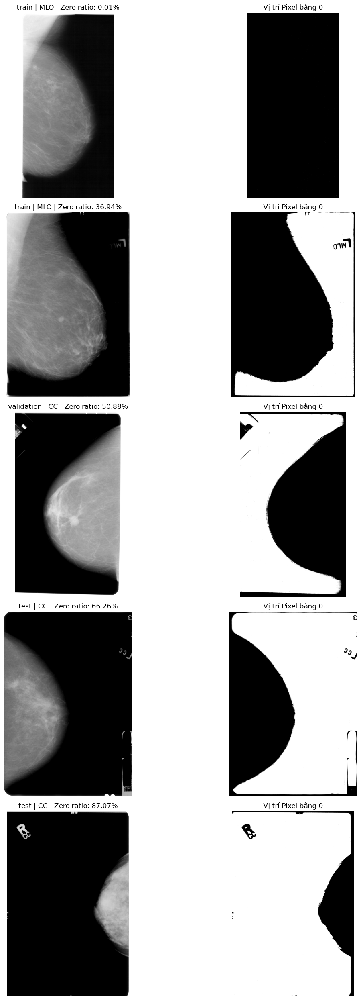

In [22]:
# 6.3.8 — Kiểm tra trực quan Pixel bằng 0

import matplotlib.pyplot as plt
import pydicom
import numpy as np
import pandas as pd

from IPython.display import display

valid_intensity_df = pixel_intensity_df[
    pixel_intensity_df["analysis_status"] == "success"
].copy()

quantile_levels = [0.00, 0.10, 0.50, 0.90, 1.00]

selected_indices = []

for q in quantile_levels:
    target_ratio = valid_intensity_df["zero_pixel_ratio"].quantile(q)

    selected_index = (
        (valid_intensity_df["zero_pixel_ratio"] - target_ratio)
        .abs()
        .idxmin()
    )

    if selected_index not in selected_indices:
        selected_indices.append(selected_index)

visual_samples_df = valid_intensity_df.loc[
    selected_indices
].copy()

visual_samples_df["zero_ratio_rank"] = (
    visual_samples_df["zero_pixel_ratio"].rank(method="first")
)

display(
    visual_samples_df[
        [
            "full_image_path",
            "dataset_splits",
            "image_views",
            "rows",
            "columns",
            "zero_pixel_ratio",
            "nonzero_p1",
            "nonzero_p50",
            "nonzero_p99"
        ]
    ].reset_index(drop=True)
)

fig, axes = plt.subplots(
    len(visual_samples_df),
    2,
    figsize=(14, 5 * len(visual_samples_df))
)

if len(visual_samples_df) == 1:
    axes = np.array([axes])

for plot_index, (_, row) in enumerate(visual_samples_df.iterrows()):

    ds = pydicom.dcmread(row["full_image_path"])
    image = ds.pixel_array

    nonzero_pixels = image[image > 0]

    vmin, vmax = np.percentile(
        nonzero_pixels,
        [1, 99]
    )

    zero_mask = image == 0

    axes[plot_index, 0].imshow(
        image,
        cmap="gray",
        vmin=vmin,
        vmax=vmax
    )

    axes[plot_index, 0].set_title(
        f"{row['dataset_splits']} | {row['image_views']} | "
        f"Zero ratio: {row['zero_pixel_ratio']:.2%}"
    )

    axes[plot_index, 1].imshow(
        zero_mask,
        cmap="gray",
        vmin=0,
        vmax=1
    )

    axes[plot_index, 1].set_title(
        "Vị trí Pixel bằng 0"
    )

    axes[plot_index, 0].axis("off")
    axes[plot_index, 1].axis("off")

    del ds, image, nonzero_pixels, zero_mask

plt.tight_layout()
plt.show()

### 06.3.8 — Nhận xét kết quả kiểm tra trực quan Pixel 0

Kết quả kiểm tra 5 ảnh đại diện cho thấy những đặc điểm quan trọng về phân bố nền và giá trị pixel:

* **Phân bố của Pixel 0**: Ở các ảnh có tỷ lệ pixel không (Zero Ratio) cao, giá trị `Pixel == 0` chủ yếu tập trung tại vùng nền bên ngoài mô vú.
* **Biến động tỷ lệ**: Tỷ lệ Pixel 0 thay đổi đáng kể giữa các ảnh, dao động từ **0,01% đến 87,07%**.
* **Hiện tượng nền tối**: Ảnh có Zero Ratio rất thấp vẫn xuất hiện vùng nền tối khi quan sát trực quan, cho thấy vùng nền không nhất thiết chỉ chứa các pixel có giá trị bằng 0 tuyệt đối.

---

### Nhận xét & Kết luận kỹ thuật:

* **Hạn chế của việc lọc ngưỡng**: Không thể sử dụng điều kiện `Pixel == 0` để xác định toàn bộ vùng nền hoặc dùng nó làm tiêu chí phân đoạn mô vú (*breast segmentation*). 
* **Bảo toàn dữ liệu**: Việc loại bỏ Pixel 0 cũng không phù hợp vì có nguy cơ làm biến dạng hoặc thay đổi dữ liệu ảnh gốc (DICOM pixel data).
* **Định hướng xử lý**: 
  * Lựa chọn **Per-image Percentile Normalization** làm phương pháp thử nghiệm ban đầu. Phương pháp này xác định ngưỡng cường độ riêng cho từng ảnh, sau đó giới hạn các giá trị cực thấp và cực cao trước khi chuẩn hóa về dải $[0, 1]$.
  * Hướng tiếp cận này được ưu tiên do phân phối cường độ và tỷ lệ Pixel 0 có sự khác biệt rõ rệt giữa các ảnh. 
  * Tuy nhiên, cần thực hiện so sánh giữa phương pháp chuẩn hóa trên toàn bộ ảnh với chuẩn hóa trên vùng mô vú được phân đoạn đáng tin cậy trước khi đưa ra quyết định phương án chính thức.
* **Kết luận**: Giữ nguyên Pixel Data gốc, **không loại bỏ Pixel 0** và tiến hành chuyển sang đánh giá phương pháp chuẩn hóa cường độ trong mục **06.4**.

In [ ]:
# 06.4.1 — Kiểm tra dữ liệu đầu vào cho thử nghiệm chuẩn hóa

print("=== DATAFRAME INFORMATION ===")

for name, df in [
    ("pixel_intensity_df", pixel_intensity_df),
    ("dicom_unique_df", dicom_unique_df),
    ("mass_dataset_df", mass_dataset_df)
]:
    print(f"\n{name}")
    print("Shape:", df.shape)
    print("Columns:")
    print(df.columns.tolist())

print("\n=== LIBRARY VERSIONS ===")
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("pydicom:", pydicom.__version__)

print("\n=== SAMPLE RECORDS ===")

display(pixel_intensity_df.head(3))
display(dicom_unique_df.head(3))

print("\n=== INPUT VALIDATION ===")

assert len(pixel_intensity_df) > 0
assert len(dicom_unique_df) > 0
assert "full_image_path" in mass_dataset_df.columns

print("Các DataFrame đã sẵn sàng.")

=== DATAFRAME INFORMATION ===

pixel_intensity_df
Shape: (1592, 33)
Columns:
['full_image_path', 'annotation_count', 'patient_count', 'dataset_splits', 'image_views', 'analysis_status', 'error', 'rows', 'columns', 'pixel_count', 'pixel_dtype', 'pixel_min', 'pixel_max', 'pixel_mean', 'pixel_std', 'zero_pixel_count', 'zero_pixel_ratio', 'nonzero_pixel_count', 'nonzero_pixel_ratio', 'pixel_p1', 'nonzero_p1', 'pixel_p5', 'nonzero_p5', 'pixel_p25', 'nonzero_p25', 'pixel_p50', 'nonzero_p50', 'pixel_p75', 'nonzero_p75', 'pixel_p95', 'nonzero_p95', 'pixel_p99', 'nonzero_p99']

dicom_unique_df
Shape: (1592, 7)
Columns:
['full_image_path', 'annotation_count', 'patient_count', 'patient_ids', 'dataset_splits', 'image_views', 'annotation_ids']

mass_dataset_df
Shape: (1696, 47)
Columns:
['annotation_id', 'patient_id', '_patient_key', 'laterality', 'image_view', 'breast_density', 'abnormality_id', 'abnormality_type', 'pathology', 'assessment', 'subtlety', 'mass_shape', 'mass_margins', 'lesion_candid

,full_image_path,annotation_count,patient_count,dataset_splits,image_views,analysis_status,error,rows,columns,pixel_count,...,pixel_p25,nonzero_p25,pixel_p50,nonzero_p50,pixel_p75,nonzero_p75,pixel_p95,nonzero_p95,pixel_p99,nonzero_p99
0,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,1,1,test,CC,success,None,4006,1846,7395076,...,0.0,21085.0,0.0,33312.0,14005.0,39867.0,41674.0,45287.0,48354.0,65535.0
1,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,1,1,test,MLO,success,None,5491,2011,11042401,...,0.0,32556.0,0.0,41695.0,40287.0,48396.0,60413.0,64615.0,65535.0,65535.0
2,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,1,1,test,CC,success,None,5904,3200,18892800,...,0.0,25650.0,0.0,30824.0,30472.0,33290.0,35932.0,38552.0,42185.0,52489.0


,full_image_path,annotation_count,patient_count,patient_ids,dataset_splits,image_views,annotation_ids
0,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,1,1,P_00016,test,CC,mass_test__00001
1,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,1,1,P_00016,test,MLO,mass_test__00002
2,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,1,1,P_00017,test,CC,mass_test__00003



=== INPUT VALIDATION ===
Các DataFrame đã sẵn sàng.


In [28]:
# 06.4.2 — Xác nhận OpenCV và truy xuất danh sách ảnh khảo sát

import cv2

print("OpenCV version:", cv2.__version__)

print("\n=== CÁC DATAFRAME CÓ THỂ LƯU KẾ HOẠCH KHẢO SÁT ===")

candidate_names = [
    name for name, obj in globals().copy().items()
    if isinstance(obj, pd.DataFrame)
    and any(key in name.lower() for key in ["sample", "plan", "visual", "inspection"])
]

if not candidate_names:
    print("Không tìm thấy DataFrame có tên liên quan đến sample/plan/visual.")
else:
    for name in candidate_names:
        df = globals()[name]

        print(f"\n{name}")
        print("Shape:", df.shape)
        print("Columns:", df.columns.tolist())

        relevant_columns = [
            col for col in df.columns
            if col in [
                "annotation_id",
                "full_image_path",
                "zero_pixel_ratio",
                "pixel_p1",
                "pixel_p99",
                "selection_label",
                "selection_method"
            ]
        ]

        if relevant_columns:
            display(df[relevant_columns].head(10))

print("\n=== THỐNG KÊ ẢNH GỐC ===")
print("Số DICOM duy nhất:", len(dicom_unique_df))
print("Số ảnh có thống kê pixel:", len(pixel_intensity_df))
print("Số ảnh khảo sát thành công:",
      (pixel_intensity_df["analysis_status"] == "success").sum())

OpenCV version: 5.0.0

=== CÁC DATAFRAME CÓ THỂ LƯU KẾ HOẠCH KHẢO SÁT ===

dicom_sample_df
Shape: (12, 6)
Columns: ['annotation_id', 'patient_id', 'dataset_split', 'image_view', 'full_image_path', 'path_exists']


,annotation_id,full_image_path
0,mass_test__00043,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...
1,mass_test__00097,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...
2,mass_test__00179,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...
3,mass_test__00029,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...
4,mass_train__01226,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...
5,mass_train__00217,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...
6,mass_train__01255,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...
7,mass_train__01221,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...
8,mass_train__00515,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...
9,mass_train__00075,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...



dicom_sample_audit_df
Shape: (12, 21)
Columns: ['annotation_id', 'patient_id', 'dataset_split', 'image_view', 'full_image_path', 'metadata_read_status', 'pixel_decode_status', 'rows', 'columns', 'pixel_dtype', 'pixel_min', 'pixel_max', 'photometric_interpretation', 'bits_allocated', 'bits_stored', 'pixel_representation', 'samples_per_pixel', 'number_of_frames', 'rescale_slope', 'rescale_intercept', 'error']


,annotation_id,full_image_path
0,mass_test__00043,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...
1,mass_test__00097,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...
2,mass_test__00179,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...
3,mass_test__00029,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...
4,mass_train__01226,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...
5,mass_train__00217,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...
6,mass_train__01255,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...
7,mass_train__01221,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...
8,mass_train__00515,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...
9,mass_train__00075,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...



visual_samples_df
Shape: (5, 34)
Columns: ['full_image_path', 'annotation_count', 'patient_count', 'dataset_splits', 'image_views', 'analysis_status', 'error', 'rows', 'columns', 'pixel_count', 'pixel_dtype', 'pixel_min', 'pixel_max', 'pixel_mean', 'pixel_std', 'zero_pixel_count', 'zero_pixel_ratio', 'nonzero_pixel_count', 'nonzero_pixel_ratio', 'pixel_p1', 'nonzero_p1', 'pixel_p5', 'nonzero_p5', 'pixel_p25', 'nonzero_p25', 'pixel_p50', 'nonzero_p50', 'pixel_p75', 'nonzero_p75', 'pixel_p95', 'nonzero_p95', 'pixel_p99', 'nonzero_p99', 'zero_ratio_rank']


,full_image_path,zero_pixel_ratio,pixel_p1,pixel_p99
710,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,0.000065,2325.0,63964.0
982,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,0.369364,0.0,51762.0
553,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,0.508809,0.0,65535.0
224,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,0.662574,0.0,43858.0
218,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,0.870655,0.0,51388.0



=== THỐNG KÊ ẢNH GỐC ===
Số DICOM duy nhất: 1592
Số ảnh có thống kê pixel: 1592
Số ảnh khảo sát thành công: 1592


In [29]:
# 06.4.3 — Thử nghiệm chuẩn hóa A/B trên 5 ảnh đại diện

# Lấy đúng 5 ảnh đã khảo sát ở Notebook 06.3.8
ab_sample_df = (
    visual_samples_df
    .sort_values("zero_ratio_rank")
    .reset_index(drop=True)
    .copy()
)

assert len(ab_sample_df) == 5, "Không tìm thấy đủ 5 ảnh đại diện."
assert ab_sample_df["full_image_path"].notna().all()
assert ab_sample_df["full_image_path"].map(
    lambda x: Path(x).is_file()
).all(), "Có đường dẫn DICOM không tồn tại."

# Hàm chuẩn hóa theo P1 và P99
def percentile_normalization(image, reference_mask=None):

    image_float = image.astype(np.float32)

    if reference_mask is None:
        reference_pixels = image_float.reshape(-1)
    else:
        reference_pixels = image_float[reference_mask]

    if reference_pixels.size == 0:
        raise ValueError("Không có Pixel hợp lệ để tính percentile.")

    lower = float(np.percentile(reference_pixels, 1))
    upper = float(np.percentile(reference_pixels, 99))

    if upper <= lower:
        raise ValueError(
            f"Khoảng percentile không hợp lệ: P1={lower}, P99={upper}"
        )

    normalized = np.clip(
        (image_float - lower) / (upper - lower),
        0,
        1
    )

    return normalized, lower, upper


# Hàm phân đoạn vùng sáng bằng Otsu
def segment_breast_candidate(image):

    if image.dtype != np.uint16:
        raise TypeError(
            f"Ảnh không có kiểu uint16: {image.dtype}"
        )

    threshold, binary = cv2.threshold(
        image,
        0,
        1,
        cv2.THRESH_BINARY + cv2.THRESH_OTSU
    )

    binary = binary.astype(np.uint8)

    # Đóng các khoảng trống nhỏ trong vùng ứng viên
    kernel_size = max(
        3,
        min(31, int(round(min(image.shape) * 0.005)) | 1)
    )

    kernel = cv2.getStructuringElement(
        cv2.MORPH_ELLIPSE,
        (kernel_size, kernel_size)
    )

    closed = cv2.morphologyEx(
        binary,
        cv2.MORPH_CLOSE,
        kernel
    )

    # Giữ thành phần liên thông lớn nhất
    component_count, labels, stats, centroids = (
        cv2.connectedComponentsWithStats(
            closed,
            connectivity=8
        )
    )

    if component_count <= 1:
        raise ValueError("Không tìm thấy vùng foreground.")

    largest_label = 1 + np.argmax(stats[1:, cv2.CC_STAT_AREA])

    breast_candidate_mask = labels == largest_label

    if breast_candidate_mask.sum() == 0:
        raise ValueError("Mặt nạ phân đoạn rỗng.")

    return breast_candidate_mask, float(threshold), kernel_size


# Đọc DICOM và tạo hai phiên bản chuẩn hóa
ab_results = []
ab_visual_data = []

for sample_index, row in ab_sample_df.iterrows():

    image_path = row["full_image_path"]

    dicom = pydicom.dcmread(image_path)
    image = dicom.pixel_array

    if image.ndim != 2:
        raise ValueError(
            f"Ảnh không phải grayscale 2D: {row['annotation_id']}"
        )

    image = image.astype(np.uint16, copy=False)

    # A — P1 và P99 trên toàn ảnh
    image_a, a_p1, a_p99 = percentile_normalization(image)

    # B — Phân đoạn và tính P1, P99 trong vùng ứng viên
    breast_mask, otsu_threshold, kernel_size = (
        segment_breast_candidate(image)
    )

    image_b, b_p1, b_p99 = percentile_normalization(
        image,
        reference_mask=breast_mask
    )

    mask_ratio = float(breast_mask.mean())

    ab_results.append({
        "sample_number": sample_index + 1,
        "full_image_path": image_path,
        "zero_pixel_ratio": row["zero_pixel_ratio"],
        "otsu_threshold": otsu_threshold,
        "segmentation_ratio": mask_ratio,
        "segmentation_pixel_count": int(breast_mask.sum()),
        "kernel_size": kernel_size,
        "A_p1": a_p1,
        "A_p99": a_p99,
        "B_p1": b_p1,
        "B_p99": b_p99,
        "A_range": a_p99 - a_p1,
        "B_range": b_p99 - b_p1
    })

    ab_visual_data.append({
        "annotation_id": row.get("annotation_id", f"Sample_{sample_index + 1}"),
        "image": image,
        "mask": breast_mask,
        "image_a": image_a,
        "image_b": image_b,
        "a_p1": a_p1,
        "a_p99": a_p99,
        "b_p1": b_p1,
        "b_p99": b_p99,
        "otsu_threshold": otsu_threshold,
        "mask_ratio": mask_ratio
    })

# Bảng kết quả định lượng
ab_comparison_df = pd.DataFrame(ab_results)

display(
    ab_comparison_df[
        [
            "sample_number",
            "zero_pixel_ratio",
            "segmentation_ratio",
            "otsu_threshold",
            "A_p1",
            "A_p99",
            "B_p1",
            "B_p99",
            "A_range",
            "B_range"
        ]
    ].round(4)
)

print("Số ảnh thử nghiệm:", len(ab_comparison_df))
print("Số ảnh xử lý thành công:", len(ab_visual_data))


,sample_number,zero_pixel_ratio,segmentation_ratio,otsu_threshold,A_p1,A_p99,B_p1,B_p99,A_range,B_range
0,1,0.0001,0.4928,21884.0,2325.0,63964.0,21884.0,65535.0,61639.0,43651.0
1,2,0.3694,0.5580,15809.0,0.0,51762.0,15456.0,59842.0,51762.0,44386.0
2,3,0.5088,0.4199,22535.0,0.0,65535.0,23102.0,65535.0,65535.0,42433.0
3,4,0.6626,0.2721,16293.0,0.0,43858.0,15588.0,65535.0,43858.0,49947.0
4,5,0.8707,0.0954,22303.0,0.0,51388.0,22524.0,65535.0,51388.0,43011.0


Số ảnh thử nghiệm: 5
Số ảnh xử lý thành công: 5


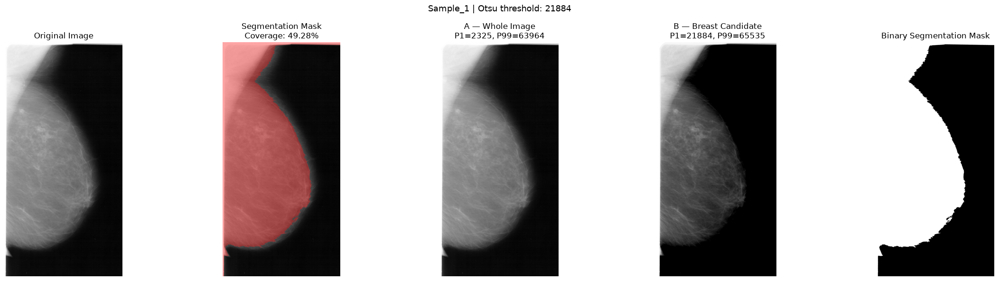

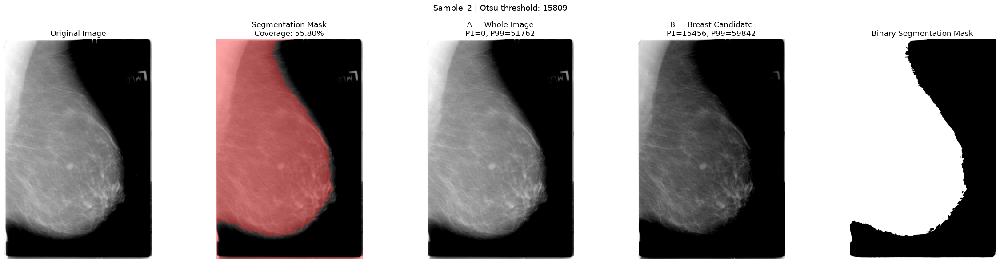

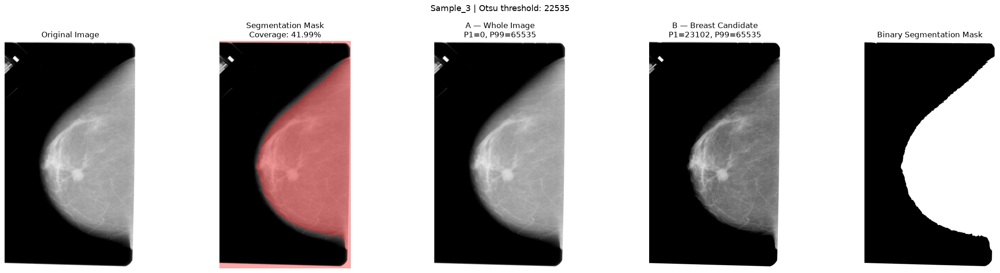

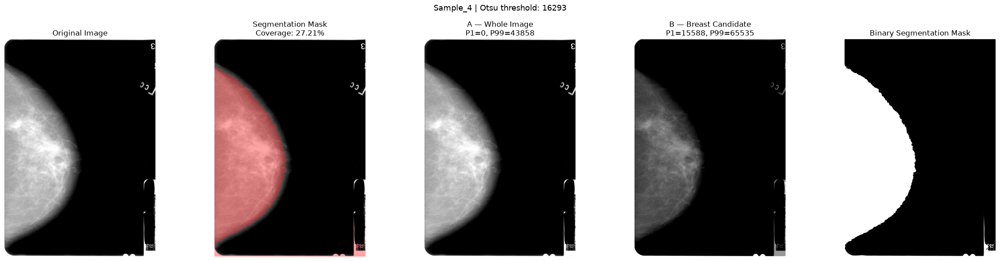

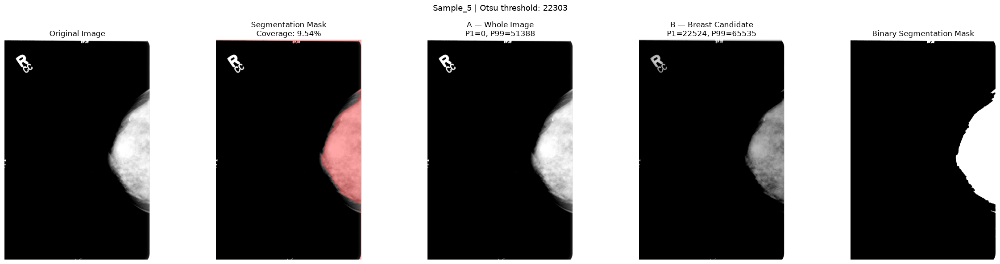

In [30]:
# 06.4.4 — So sánh trực quan hai phương pháp chuẩn hóa

for item in ab_visual_data:

    fig, axes = plt.subplots(1, 5, figsize=(24, 6))

    image = item["image"]
    mask = item["mask"]

    # Ảnh gốc dùng P1–P99 toàn ảnh để hiển thị
    original_display, _, _ = percentile_normalization(image)

    axes[0].imshow(original_display, cmap="gray", vmin=0, vmax=1)
    axes[0].set_title("Original Image")

    axes[1].imshow(original_display, cmap="gray", vmin=0, vmax=1)
    axes[1].imshow(
        np.ma.masked_where(~mask, mask),
        cmap="autumn",
        alpha=0.35
    )
    axes[1].set_title(
        f"Segmentation Mask\nCoverage: {item['mask_ratio']:.2%}"
    )

    axes[2].imshow(item["image_a"], cmap="gray", vmin=0, vmax=1)
    axes[2].set_title(
        f"A — Whole Image\nP1={item['a_p1']:.0f}, "
        f"P99={item['a_p99']:.0f}"
    )

    axes[3].imshow(item["image_b"], cmap="gray", vmin=0, vmax=1)
    axes[3].set_title(
        f"B — Breast Candidate\nP1={item['b_p1']:.0f}, "
        f"P99={item['b_p99']:.0f}"
    )

    axes[4].imshow(mask, cmap="gray", vmin=0, vmax=1)
    axes[4].set_title("Binary Segmentation Mask")

    for ax in axes:
        ax.axis("off")

    fig.suptitle(
        f"{item['annotation_id']} | "
        f"Otsu threshold: {item['otsu_threshold']:.0f}",
        fontsize=13
    )

    plt.tight_layout()
    plt.show()


### Đánh giá trực quan kết quả chuẩn hóa A/B

Qua quan sát 5 ảnh đại diện, kết quả ghi nhận giữa hai phương pháp chuẩn hóa như sau:

* **Phương pháp A** (Tính ngưỡng $P_1 - P_99$ trên toàn bộ ảnh):
  * Mang lại hình ảnh sáng hơn.
  * Các đường vân mô vú trở nên rõ ràng và dễ quan sát hơn.
* **Phương pháp B** (Tính ngưỡng $P_1 - P_99$ trong vùng mô vú đã phân đoạn):
  * Hình ảnh có phần tối hơn một chút.
  * Vẫn duy trì và bảo lưu tốt các cấu trúc sáng bên trong mô vú.

#### Đánh giá mặt nạ phân đoạn:
* Mặt nạ phân đoạn (Segmentation Mask) sử dụng trong Phương pháp B đã được quan sát trên cả 5 ảnh mẫu.
* Kết quả ghi nhận **chưa xuất hiện hiện tượng bỏ sót hoặc nhận nhầm vùng mô vú rõ rệt**. 
* Tuy nhiên, đây mới chỉ là đánh giá trực quan ban đầu và **chưa xác nhận được khả năng bảo toàn toàn bộ vùng tổn thương** (lesion region).

---

### Kết luận tạm thời & Hướng đi tiếp theo:

* **Tạm thời giữ cả hai phương pháp (A và B)** để tiếp tục tiến hành các bước đánh giá định lượng sâu hơn.
* **Chưa đưa ra lựa chọn phương pháp chuẩn hóa chính thức** ở giai đoạn này.
* **Chưa áp dụng đại trà** cho toàn bộ dataset cho đến khi hoàn tất các tiêu chí kiểm định bổ sung.

In [31]:
# 06.4.5 — Kiểm tra ROI Mask trên vùng phân đoạn

sample_roi_audit_records = []
sample_roi_visual_data = []

for sample_index, sample_row in ab_sample_df.iterrows():

    image_path = str(sample_row["full_image_path"])
    image = ab_visual_data[sample_index]["image"]
    breast_mask = ab_visual_data[sample_index]["mask"]

    # Tìm tất cả annotation liên kết với Full Image
    matched_annotations = mass_dataset_df[
        mass_dataset_df["full_image_path"].astype(str) == image_path
    ].copy()

    if matched_annotations.empty:
        print(f"Không tìm thấy annotation: Sample {sample_index + 1}")
        continue

    combined_roi_mask = np.zeros(image.shape, dtype=bool)
    annotation_roi_masks = []

    for _, annotation in matched_annotations.iterrows():

        annotation_id = annotation["annotation_id"]
        roi_path = Path(str(annotation["normalized_mask_path"]))

        record = {
            "sample_number": sample_index + 1,
            "annotation_id": annotation_id,
            "patient_id": annotation["patient_id"],
            "image_view": annotation["image_view"],
            "dataset_split": annotation["dataset_split"],
            "normalized_mask_path": str(roi_path),
            "roi_status": None,
            "roi_pixels": 0,
            "covered_pixels": 0,
            "outside_pixels": 0,
            "roi_coverage": np.nan
        }

        if not roi_path.is_file():
            record["roi_status"] = "file_missing"
            sample_roi_audit_records.append(record)
            continue

        roi_array = cv2.imread(
            str(roi_path),
            cv2.IMREAD_UNCHANGED
        )

        if roi_array is None:
            record["roi_status"] = "read_failed"
            sample_roi_audit_records.append(record)
            continue

        if roi_array.ndim == 3:
            if roi_array.shape[2] == 1:
                roi_array = roi_array[:, :, 0]
            else:
                record["roi_status"] = "unexpected_channels"
                sample_roi_audit_records.append(record)
                continue

        if roi_array.shape != image.shape:
            record["roi_status"] = "shape_mismatch"
            record["roi_shape"] = str(roi_array.shape)
            record["full_image_shape"] = str(image.shape)
            sample_roi_audit_records.append(record)
            continue

        # Chuyển ROI Mask thành mặt nạ nhị phân
        roi_mask = roi_array > 0

        roi_pixels = int(roi_mask.sum())

        if roi_pixels == 0:
            record["roi_status"] = "empty_mask"
            sample_roi_audit_records.append(record)
            continue

        # Đối chiếu ROI với vùng phân đoạn B
        covered_pixels = int(
            np.logical_and(roi_mask, breast_mask).sum()
        )

        outside_pixels = roi_pixels - covered_pixels

        roi_coverage = covered_pixels / roi_pixels

        record.update({
            "roi_status": "success",
            "roi_pixels": roi_pixels,
            "covered_pixels": covered_pixels,
            "outside_pixels": outside_pixels,
            "roi_coverage": roi_coverage
        })

        sample_roi_audit_records.append(record)

        annotation_roi_masks.append(roi_mask)
        combined_roi_mask |= roi_mask

    if annotation_roi_masks:

        total_roi_pixels = int(combined_roi_mask.sum())

        total_covered_pixels = int(
            np.logical_and(
                combined_roi_mask,
                breast_mask
            ).sum()
        )

        combined_coverage = (
            total_covered_pixels / total_roi_pixels
            if total_roi_pixels > 0 else np.nan
        )

        sample_roi_visual_data.append({
            "sample_number": sample_index + 1,
            "image": image,
            "breast_mask": breast_mask,
            "roi_mask": combined_roi_mask,
            "roi_pixels": total_roi_pixels,
            "covered_pixels": total_covered_pixels,
            "outside_pixels": total_roi_pixels - total_covered_pixels,
            "roi_coverage": combined_coverage
        })


# Tổng hợp kết quả
sample_roi_audit_df = pd.DataFrame(
    sample_roi_audit_records
)

sample_roi_summary_df = (
    sample_roi_audit_df
    .groupby("sample_number", as_index=False)
    .agg(
        annotation_count=("annotation_id", "count"),
        successful_masks=(
            "roi_status",
            lambda x: (x == "success").sum()
        ),
        total_roi_pixels=("roi_pixels", "sum"),
        total_covered_pixels=("covered_pixels", "sum"),
        total_outside_pixels=("outside_pixels", "sum")
    )
)

sample_roi_summary_df["roi_coverage"] = (
    sample_roi_summary_df["total_covered_pixels"]
    / sample_roi_summary_df["total_roi_pixels"].replace(0, np.nan)
)

print("=== ROI AUDIT BY ANNOTATION ===")
display(sample_roi_audit_df)

print("\n=== ROI COVERAGE BY SAMPLE ===")
display(sample_roi_summary_df.round(4))

print("\n=== ROI STATUS COUNTS ===")
display(
    sample_roi_audit_df["roi_status"]
    .value_counts(dropna=False)
    .rename_axis("roi_status")
    .reset_index(name="count")
)


=== ROI AUDIT BY ANNOTATION ===


,sample_number,annotation_id,patient_id,image_view,dataset_split,normalized_mask_path,roi_status,roi_pixels,covered_pixels,outside_pixels,roi_coverage
0,1,mass_train__00386,P_00543,MLO,train,C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb05...,success,138701,138701,0,1.000000
1,2,mass_train__00676,P_00972,MLO,train,C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb05...,success,22096,22096,0,1.000000
2,3,mass_train__00215,P_00319,CC,validation,C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb05...,success,173615,173615,0,1.000000
3,4,mass_test__00239,P_01140,CC,test,C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb05...,success,47646,47646,0,1.000000
4,5,mass_test__00233,P_01108,CC,test,C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb05...,success,131720,125440,6280,0.952323



=== ROI COVERAGE BY SAMPLE ===


,sample_number,annotation_count,successful_masks,total_roi_pixels,total_covered_pixels,total_outside_pixels,roi_coverage
0,1,1,1,138701,138701,0,1.0000
1,2,1,1,22096,22096,0,1.0000
2,3,1,1,173615,173615,0,1.0000
3,4,1,1,47646,47646,0,1.0000
4,5,1,1,131720,125440,6280,0.9523



=== ROI STATUS COUNTS ===


,roi_status,count
0,success,5


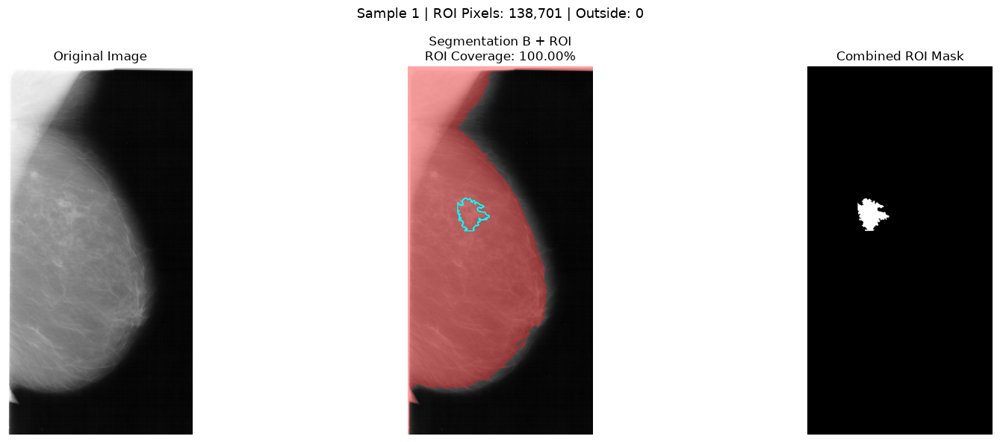

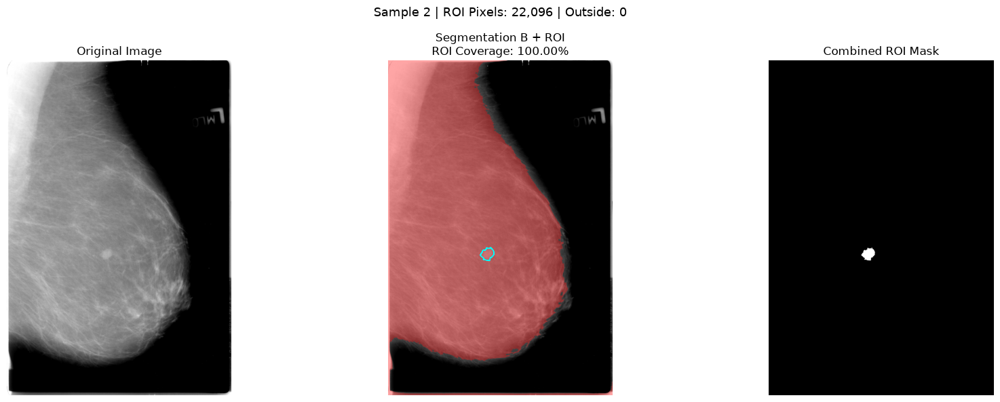

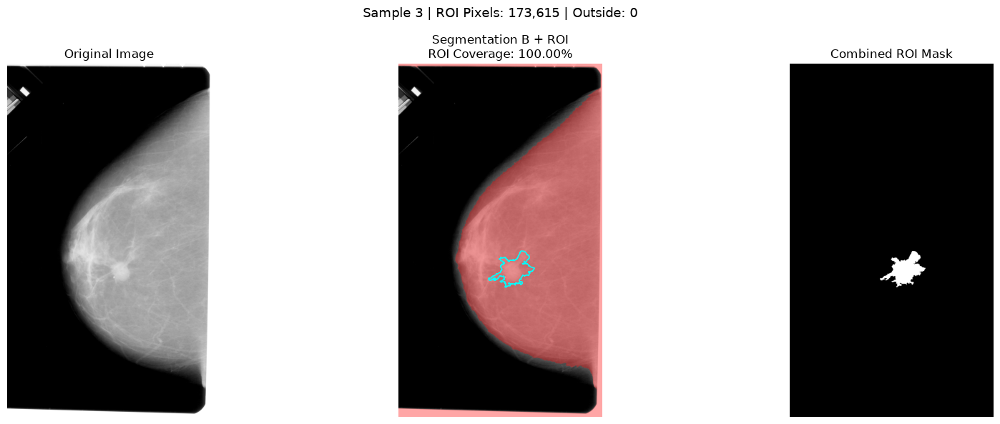

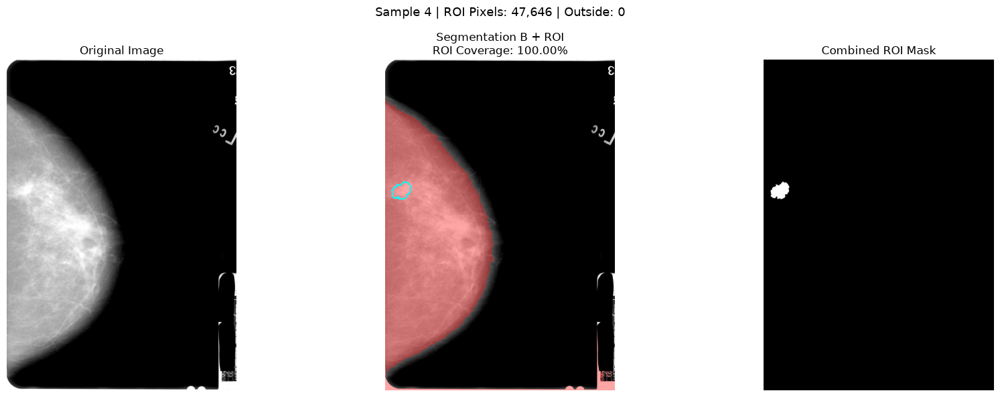

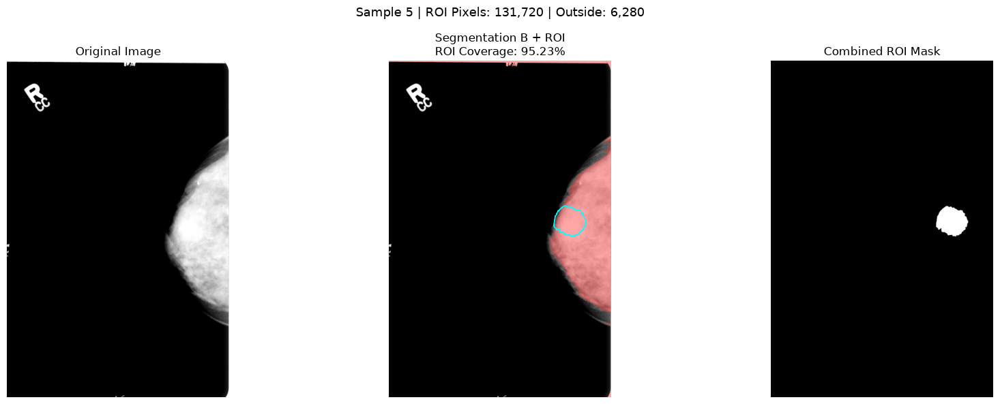

In [32]:
# 06.4.6 — Hiển thị ROI Mask và Segmentation Mask

for item in sample_roi_visual_data:

    image = item["image"]
    breast_mask = item["breast_mask"]
    roi_mask = item["roi_mask"]

    original_display, _, _ = percentile_normalization(image)

    fig, axes = plt.subplots(1, 3, figsize=(18, 6))

    axes[0].imshow(
        original_display,
        cmap="gray",
        vmin=0,
        vmax=1
    )
    axes[0].set_title("Original Image")

    axes[1].imshow(
        original_display,
        cmap="gray",
        vmin=0,
        vmax=1
    )

    axes[1].imshow(
        np.ma.masked_where(~breast_mask, breast_mask),
        cmap="autumn",
        alpha=0.35
    )

    axes[1].contour(
        roi_mask.astype(np.uint8),
        levels=[0.5],
        colors=["cyan"],
        linewidths=1
    )

    axes[1].set_title(
        f"Segmentation B + ROI\n"
        f"ROI Coverage: {item['roi_coverage']:.2%}"
    )

    axes[2].imshow(
        roi_mask,
        cmap="gray",
        vmin=0,
        vmax=1
    )
    axes[2].set_title("Combined ROI Mask")

    for ax in axes:
        ax.axis("off")

    fig.suptitle(
        f"Sample {item['sample_number']} | "
        f"ROI Pixels: {item['roi_pixels']:,} | "
        f"Outside: {item['outside_pixels']:,}",
        fontsize=13
    )

    plt.tight_layout()
    plt.show()


### Đánh giá ROI Mask và Segmentation Mask

Kết quả đối chiếu chi tiết trên 5 ảnh đại diện cho thấy toàn bộ 5 `ROI Mask` đều được đọc thành công và có kích thước hoàn toàn tương thích với `Full Image`:

* **Độ bao phủ (ROI Coverage)**:
  * **4 / 5 ảnh** đạt tỷ lệ bao phủ tuyệt đối (**100%**).
  * **Sample 5** đạt **95,23%**, tương ứng với khoảng 6.280 pixel ROI nằm bên ngoài vùng phân đoạn (`segmentation mask`). 
* **Kiểm tra trực quan**: Phần sai khác ở Sample 5 chủ yếu xuất phát từ việc ranh giới khoanh vùng ROI rộng hơn một chút so với mô vú thực tế, và **không làm thay đổi hay lệch vị trí vùng tổn thương**.
* **Tính toàn vẹn dữ liệu**: Không ghi nhận bất kỳ lỗi đọc dữ liệu (`read error`) hay hiện tượng ROI Mask rỗng (`empty mask`).

---

### Nhận xét & Kết luận sơ bộ:
* Nhìn chung, **Phương pháp chuẩn hóa B** (tính ngưỡng dựa trên vùng phân đoạn) thể hiện khả năng bao phủ vùng tổn thương rất tốt trên 5 ảnh thử nghiệm.
* Kết quả này được xem là **đạt yêu cầu kiểm tra ban đầu**, tạo tiền đề tin cậy để tiếp tục mở rộng đánh giá, tuy nhiên vẫn cần lưu ý rằng kết quả trên 5 mẫu **chưa đại diện cho toàn bộ 1.696 ảnh** trong dataset.

In [35]:
print("ab_visual_data:")
print(ab_visual_data[0].keys())
print(ab_visual_data[0]["annotation_id"])

print("\nab_sample_df:")
display(ab_sample_df.head())

print("\nsample_roi_visual_data:")
print(sample_roi_visual_data[0].keys())
print(sample_roi_visual_data[0])

ab_visual_data:
dict_keys(['annotation_id', 'image', 'mask', 'image_a', 'image_b', 'a_p1', 'a_p99', 'b_p1', 'b_p99', 'otsu_threshold', 'mask_ratio'])
Sample_1

ab_sample_df:


,full_image_path,annotation_count,patient_count,dataset_splits,image_views,analysis_status,error,rows,columns,pixel_count,...,nonzero_p25,pixel_p50,nonzero_p50,pixel_p75,nonzero_p75,pixel_p95,nonzero_p95,pixel_p99,nonzero_p99,zero_ratio_rank
0,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,1,1,train,MLO,success,None,5671,2851,16168021,...,4678.0,19426.0,19426.0,34993.0,34993.0,56695.0,56695.0,63964.0,63964.0,1.0
1,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,1,1,train,MLO,success,None,4624,3104,14352896,...,24505.0,23162.0,28578.0,29855.0,31815.0,40555.0,45421.0,51762.0,58477.0,2.0
2,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,1,1,validation,CC,success,None,5491,3166,17384506,...,35875.0,0.0,42451.0,42388.0,44804.0,51170.0,65535.0,65535.0,65535.0,3.0
3,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,1,1,test,CC,success,None,4824,3352,16170048,...,21731.0,0.0,30031.0,22480.0,34038.0,36879.0,41436.0,43858.0,65535.0,4.0
4,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,1,1,test,CC,success,None,4624,3056,14130944,...,23933.0,0.0,43286.0,0.0,47667.0,45509.0,52643.0,51388.0,65535.0,5.0



sample_roi_visual_data:
dict_keys(['sample_number', 'image', 'breast_mask', 'roi_mask', 'roi_pixels', 'covered_pixels', 'outside_pixels', 'roi_coverage'])
{'sample_number': 1, 'image': array([[ 5329,  6884, 65535, ..., 64006, 64027, 64006],
       [65535, 65535, 65535, ..., 64048, 63880, 63943],
       [65535, 65535, 65535, ..., 63964, 64006, 64027],
       ...,
       [65535, 65535, 65535, ...,  3858,  3963,  4089],
       [65535, 65535, 65535, ...,  4573,  3900,  3123],
       [65535, 65535, 65535, ...,  4846,  4152,  3921]],
      shape=(5671, 2851), dtype=uint16), 'breast_mask': array([[ True,  True,  True, ...,  True,  True,  True],
       [ True,  True,  True, ...,  True,  True,  True],
       [ True,  True,  True, ...,  True,  True,  True],
       ...,
       [ True,  True,  True, ..., False, False, False],
       [ True,  True,  True, ..., False, False, False],
       [ True,  True,  True, ..., False, False, False]],
      shape=(5671, 2851)), 'roi_mask': array([[False, False,

In [36]:
# 06.4.7 — So sánh tương phản ROI giữa A và B

roi_visual_lookup = {
    item["sample_number"]: item
    for item in sample_roi_visual_data
}

contrast_results = []
contrast_visual_data = []

for sample in ab_visual_data:
    sample_number = int(sample["annotation_id"].split("_")[-1])

    if sample_number not in roi_visual_lookup:
        raise ValueError(
            f"Không tìm thấy ROI của Sample_{sample_number}"
        )

    roi_data = roi_visual_lookup[sample_number]

    roi_mask = np.asarray(roi_data["roi_mask"], dtype=bool)
    breast_mask = np.asarray(roi_data["breast_mask"], dtype=bool)

    image_a = np.asarray(sample["image_a"], dtype=np.float32)
    image_b = np.asarray(sample["image_b"], dtype=np.float32)

    if not (
        roi_mask.shape == breast_mask.shape
        == image_a.shape == image_b.shape
    ):
        raise ValueError(
            f"Kích thước không đồng nhất tại Sample_{sample_number}"
        )

    roi_pixels = roi_mask & breast_mask

    roi_coverage = (
        roi_pixels.sum() / roi_mask.sum()
        if roi_mask.sum() > 0 else 0
    )

    if roi_pixels.sum() == 0:
        raise ValueError(
            f"ROI không nằm trong vùng segmentation tại Sample_{sample_number}"
        )

    rows, cols = np.where(roi_mask)

    bbox_height = rows.max() - rows.min() + 1
    bbox_width = cols.max() - cols.min() + 1

    margin = int(round(0.10 * max(bbox_height, bbox_width)))
    margin = max(10, min(margin, 100))

    kernel_size = 2 * margin + 1

    kernel = cv2.getStructuringElement(
        cv2.MORPH_ELLIPSE,
        (kernel_size, kernel_size)
    )

    dilated_roi = cv2.dilate(
        roi_mask.astype(np.uint8),
        kernel
    ).astype(bool)

    ring_mask = dilated_roi & (~roi_mask) & breast_mask

    if ring_mask.sum() < 100:
        raise ValueError(
            f"Vùng mô tham chiếu quá nhỏ tại Sample_{sample_number}"
        )

    for method, image in [
        ("A", image_a),
        ("B", image_b)
    ]:
        roi_values = image[roi_pixels]
        ring_values = image[ring_mask]

        roi_mean = float(roi_values.mean())
        roi_std = float(roi_values.std())

        ring_mean = float(ring_values.mean())
        ring_std = float(ring_values.std())

        contrast_difference = roi_mean - ring_mean

        cnr = (
            abs(contrast_difference) / ring_std
            if ring_std > 0 else np.nan
        )

        contrast_results.append({
            "sample_number": sample_number,
            "method": method,
            "roi_pixel_count": int(roi_pixels.sum()),
            "ring_pixel_count": int(ring_mask.sum()),
            "roi_coverage": roi_coverage,
            "roi_mean": roi_mean,
            "roi_std": roi_std,
            "ring_mean": ring_mean,
            "ring_std": ring_std,
            "contrast_difference": contrast_difference,
            "absolute_contrast": abs(contrast_difference),
            "cnr": cnr,
            "ring_margin_pixels": margin
        })

    contrast_visual_data.append({
        "sample_number": sample_number,
        "roi_mask": roi_mask,
        "roi_pixels": roi_pixels,
        "ring_mask": ring_mask,
        "image_a": image_a,
        "image_b": image_b,
        "roi_coverage": roi_coverage
    })

contrast_df = pd.DataFrame(contrast_results)

contrast_comparison_df = contrast_df.pivot(
    index="sample_number",
    columns="method",
    values=[
        "absolute_contrast",
        "cnr",
        "roi_mean",
        "ring_mean"
    ]
)

print("=== ROI CONTRAST RESULTS ===")
display(contrast_df.round(4))

print("=== A/B COMPARISON ===")
display(contrast_comparison_df.round(4))

print("=== AVERAGE METRICS ===")
contrast_average_df = (
    contrast_df.groupby("method")[
        ["absolute_contrast", "cnr", "roi_mean", "ring_mean"]
    ]
    .mean()
    .round(4)
)

display(contrast_average_df)


=== ROI CONTRAST RESULTS ===


,sample_number,method,roi_pixel_count,ring_pixel_count,roi_coverage,roi_mean,roi_std,ring_mean,ring_std,contrast_difference,absolute_contrast,cnr,ring_margin_pixels
0,1,A,138701,112566,1.0000,0.5943,0.0358,0.5664,0.0412,0.0279,0.0279,0.6781,51
1,1,B,138701,112566,1.0000,0.3911,0.0506,0.3517,0.0582,0.0395,0.0395,0.6781,51
2,2,A,22096,13987,1.0000,0.6447,0.0413,0.5599,0.0213,0.0848,0.0848,3.9754,19
3,2,B,22096,13987,1.0000,0.4036,0.0482,0.3047,0.0249,0.0989,0.0989,3.9754,19
4,3,A,173615,202530,1.0000,0.7486,0.0615,0.6819,0.0380,0.0667,0.0667,1.7540,71
5,3,B,173615,202530,1.0000,0.6117,0.0950,0.5087,0.0587,0.1030,0.1030,1.7540,71
6,4,A,47646,30404,1.0000,0.9207,0.0627,0.8264,0.0611,0.0943,0.0943,1.5425,28
7,4,B,47646,30404,1.0000,0.5004,0.0611,0.4136,0.0538,0.0868,0.0868,1.6144,28
8,5,A,125440,51958,0.9523,0.9296,0.1163,0.9133,0.1190,0.0163,0.0163,0.1369,44
9,5,B,125440,51958,0.9523,0.5954,0.1444,0.5690,0.1428,0.0264,0.0264,0.1848,44


=== A/B COMPARISON ===


absolute_contrast             cnr         roi_mean          \
method                        A       B       A       B        A       B   
sample_number                                                              
1                        0.0279  0.0395  0.6781  0.6781   0.5943  0.3911   
2                        0.0848  0.0989  3.9754  3.9754   0.6447  0.4036   
3                        0.0667  0.1030  1.7540  1.7540   0.7486  0.6117   
4                        0.0943  0.0868  1.5425  1.6144   0.9207  0.5004   
5                        0.0163  0.0264  0.1369  0.1848   0.9296  0.5954   

              ring_mean          
method                A       B  
sample_number                    
1                0.5664  0.3517  
2                0.5599  0.3047  
3                0.6819  0.5087  
4                0.8264  0.4136  
5                0.9133  0.5690

=== AVERAGE METRICS ===


,absolute_contrast,cnr,roi_mean,ring_mean
method,,,,
A,0.0580,1.6174,0.7676,0.7096
B,0.0709,1.6414,0.5005,0.4295


# Đánh giá và lựa chọn phương pháp chuẩn hóa ảnh

## 1. Kết quả so sánh định lượng

Thử nghiệm được thực hiện trên 5 ảnh nhũ ảnh đại diện, sử dụng cùng ROI Mask và vùng mô tham chiếu để đánh giá hai phương pháp:

* **Phương pháp A:** Chuẩn hóa $P_1 / P_{99}$ trên toàn bộ ảnh.
* **Phương pháp B:** Phân đoạn vùng mô vú, sau đó chuẩn hóa $P_1 / P_{99}$ dựa trên vùng được phân đoạn.

#### Bảng so sánh các chỉ số trung bình:

| Chỉ số | Phương pháp A | Phương pháp B | Mức chênh lệch / Nhận xét |
| :--- | :---: | :---: | :--- |
| **Absolute Contrast** | 0.0580 | **0.0709** | B cao hơn A khoảng **22.2%** |
| **CNR** | 1.6174 | **1.6414** | B cao hơn A không đáng kể (**1.5%**) |
| **ROI Mean** | **0.7676** | 0.5005 | A duy trì mức cường độ sáng cao hơn |
| **Ring Mean** | **0.7096** | 0.4295 | A duy trì nền mô xung quanh sáng hơn |

> **Nhận xét chỉ số:** Phương pháp B có *Absolute Contrast* trung bình cao hơn khoảng 22.2% so với A. Tuy nhiên, chỉ số *CNR* (Contrast-to-Noise Ratio) chỉ tăng khoảng 1.5%. Điều này cho thấy mức cải thiện về chênh lệch cường độ tuyệt đối chưa chuyển thành mức cải thiện tương ứng về khả năng phân biệt ROI với vùng mô xung quanh.

#### Thống kê chi tiết trên 5 mẫu thử nghiệm:
* **Absolute Contrast**: B cao hơn A ở 4/5 mẫu; A cao hơn B ở 1/5 mẫu.
* **CNR**: Giữa hai phương pháp gần như tương đương.
* **ROI Coverage**: Đạt **100%** ở 4/5 mẫu và **95.23%** ở mẫu còn lại.

---

## 2. Đánh giá trực quan

Qua quan sát ảnh sau chuẩn hóa:
* **Phương pháp A**: Cho hình ảnh sáng hơn, các cấu trúc mô tuyến vú rõ ràng và dễ quan sát hơn.
* **Phương pháp B**: Vẫn giữ được các cấu trúc sáng trong vùng mô vú, nhưng hình ảnh có xu hướng tối hơn tổng thể.

Sự khác biệt này hoàn toàn phù hợp với cơ chế xác định bách phân vị (percentile) của hai phương pháp:
1. **Phương pháp A** sử dụng phân phối cường độ của toàn ảnh (bao gồm cả vùng nền tối).
2. **Phương pháp B** chỉ sử dụng các pixel nằm trong vùng phân đoạn (`segmentation mask`) để xác định ngưỡng $P_1$ và $P_{99}$.

Do đó, hai phương pháp tạo ra các khoảng cường độ chuẩn hóa khác nhau. Giá trị *Absolute Contrast* cao hơn ở B không đồng nghĩa với việc toàn bộ cấu trúc mô hoặc tổn thương được thể hiện trực quan tốt hơn.

---

## 3. Nguyên nhân và lý do lựa chọn phương pháp A

Phương pháp A được lựa chọn làm phương pháp chuẩn hóa chính cho các giai đoạn tiếp theo vì 4 lý do kỹ thuật cốt lõi:

1. **Chất lượng trực quan phù hợp với mục tiêu nghiên cứu:**
   * Ảnh sau chuẩn hóa bằng A thể hiện rõ các cấu trúc mô tuyến vú và vùng tổn thương trong quá trình kiểm tra trực quan. Đây là yếu tố quyết định đối với bài toán phát hiện, định vị và phân loại tổn thương trên ảnh X-quang tuyến vú (*Mammography*).
2. **Kết quả CNR giữa hai phương pháp gần như tương đương:**
   * CNR trung bình của A đạt **1.6174**, trong khi B đạt **1.6414**. Chênh lệch tương đối nhỏ (1.5%), chưa cho thấy ưu thế rõ ràng của B về tương phản cục bộ giữa ROI và vùng mô tham chiếu.
3. **Không phụ thuộc vào chất lượng phân đoạn vùng mô vú:**
   * Phương pháp A không cần sử dụng `segmentation mask` để xác định ngưỡng chuẩn hóa. Điều này giúp giảm sự phụ thuộc vào một bước xử lý bổ sung và hạn chế triệt để nguy cơ sai lệch cường độ do phân đoạn không chính xác.
4. **Phù hợp với cấu trúc Detection Dataset:**
   * `Full Image` được sử dụng làm ảnh đầu vào cho mô hình học sâu. 
   * `Normalized ROI Mask` được sử dụng riêng để trích xuất Bounding Box. 
   * Nhãn `Pathology` được giữ lại để phục vụ nhiệm vụ phân biệt tổn thương lành tính và ác tính.
   * Việc tách biệt tiền xử lý ảnh và xây dựng nhãn định vị giúp quy trình xử lý rõ ràng, dễ kiểm soát và có khả năng tái lập cao (*reproducibility*).

---

## 4. Quyết định lựa chọn chính thức

**Phương pháp A — Chuẩn hóa $P_1 / P_{99}$ trên toàn ảnh — chính thức được chọn làm phương pháp chuẩn hóa chủ đạo.**

#### Cấu hình áp dụng chi tiết:
* **Đầu vào:** DICOM Pixel Data, kiểu dữ liệu 16-bit.
* **Photometric Interpretation:** `MONOCHROME2`.
* **Ngưỡng dưới:** Percentile 1 ($P_1$).
* **Ngưỡng trên:** Percentile 99 ($P_{99}$).
* **Clipping:** Pixel được giới hạn trong khoảng $[P_1, P_{99}]$.
* **Chuẩn hóa:** Biến đổi tuyến tính về dải $[0, 1]$.
* **Định dạng:** Giữ nguyên ảnh grayscale.
* **Inversion:** Không đảo cường độ ảnh.
* **Hình học:** Không crop, resize hoặc thay đổi hình học ở bước chuẩn hóa.
* **Dữ liệu gốc:** Tuyệt đối không ghi đè dữ liệu DICOM gốc.

*(Lưu ý: Phương pháp B tiếp tục được giữ lại như một phương pháp đối chiếu trong các thử nghiệm tiền xử lý mở rộng, không dùng cho pipeline sản xuất chính).*


In [37]:
# 06.4.8 — Chuẩn hóa Full Image cho toàn bộ 1.696 annotation

output_dir = NB06_OUTPUT_DIR / "nb06_4_8_normalized_full_images_a"
output_dir.mkdir(parents=True, exist_ok=True)

manifest_path = output_dir / "nb06_4_8_normalization_a_manifest.csv"
summary_path = output_dir / "nb06_4_8_normalization_a_summary.csv"

required_dataset_columns = [
    "annotation_id",
    "patient_id",
    "dataset_split",
    "full_image_path"
]

required_pixel_columns = [
    "full_image_path",
    "analysis_status",
    "pixel_p1",
    "pixel_p99"
]

for col in required_dataset_columns:
    if col not in mass_dataset_df.columns:
        raise ValueError(f"Thiếu cột mass_dataset_df: {col}")

for col in required_pixel_columns:
    if col not in pixel_intensity_df.columns:
        raise ValueError(f"Thiếu cột pixel_intensity_df: {col}")

annotation_input_df = mass_dataset_df[
    required_dataset_columns
].copy()

pixel_bounds_df = pixel_intensity_df[
    required_pixel_columns
].copy()

if len(annotation_input_df) != 1696:
    raise ValueError(
        f"Số annotation không đúng: {len(annotation_input_df)}"
    )

if annotation_input_df["annotation_id"].nunique() != 1696:
    raise ValueError("Annotation ID bị trùng.")

if pixel_bounds_df["full_image_path"].nunique() != 1592:
    raise ValueError("Số DICOM duy nhất không khớp 1.592.")

if not pixel_bounds_df["analysis_status"].astype(str).str.lower().eq("success").all():
    raise ValueError("Có DICOM chưa hoàn thành phân tích pixel.")

annotation_input_df = annotation_input_df.merge(
    pixel_bounds_df,
    on="full_image_path",
    how="left",
    validate="many_to_one"
)

if len(annotation_input_df) != 1696:
    raise ValueError("Số dòng thay đổi sau khi ghép P1/P99.")

if annotation_input_df[["pixel_p1", "pixel_p99"]].isna().any().any():
    raise ValueError("Có annotation chưa tìm được P1/P99.")

if not (
    annotation_input_df["pixel_p99"] >
    annotation_input_df["pixel_p1"]
).all():
    raise ValueError("Có annotation có P99 <= P1.")

missing_paths = [
    path for path in annotation_input_df["full_image_path"]
    if not Path(path).is_file()
]

if missing_paths:
    raise FileNotFoundError(
        f"Có {len(missing_paths)} đường dẫn DICOM không tồn tại."
    )

records = []

for index, row in annotation_input_df.iterrows():
    annotation_id = str(row["annotation_id"])
    image_path = Path(row["full_image_path"])

    output_path = output_dir / f"{annotation_id}.png"

    record = {
        "annotation_id": annotation_id,
        "patient_id": row["patient_id"],
        "dataset_split": row["dataset_split"],
        "full_image_path": str(image_path),
        "normalized_image_path": str(output_path),
        "p1": float(row["pixel_p1"]),
        "p99": float(row["pixel_p99"]),
        "status": "failed",
        "rows": None,
        "columns": None,
        "clipped_low_ratio": None,
        "clipped_high_ratio": None,
        "output_dtype": None,
        "error": None
    }

    try:
        dicom = pydicom.dcmread(str(image_path))
        image = dicom.pixel_array

        if image.ndim != 2:
            raise ValueError(f"Ảnh không phải grayscale 2D: {image.shape}")

        image_float = image.astype(np.float32)

        p1 = float(row["pixel_p1"])
        p99 = float(row["pixel_p99"])

        if p99 <= p1:
            raise ValueError("P99 phải lớn hơn P1.")

        record["rows"] = image.shape[0]
        record["columns"] = image.shape[1]
        record["clipped_low_ratio"] = float(
            np.mean(image_float < p1)
        )
        record["clipped_high_ratio"] = float(
            np.mean(image_float > p99)
        )

        image_clipped = np.clip(image_float, p1, p99)

        normalized_image = (
            (image_clipped - p1) / (p99 - p1) * 255
        )

        normalized_image = np.round(
            normalized_image
        ).astype(np.uint8)

        success = cv2.imwrite(
            str(output_path),
            normalized_image
        )

        if not success or not output_path.is_file():
            raise IOError("Không thể ghi ảnh PNG.")

        record["status"] = "success"
        record["output_dtype"] = str(normalized_image.dtype)

    except Exception as error:
        record["error"] = str(error)

    records.append(record)

    if (index + 1) % 100 == 0 or index + 1 == len(annotation_input_df):
        print(f"Đã xử lý: {index + 1}/1696")

normalization_a_manifest_df = pd.DataFrame(records)

normalization_a_manifest_df.to_csv(
    manifest_path,
    index=False,
    encoding="utf-8-sig"
)

success_count = int(
    normalization_a_manifest_df["status"].eq("success").sum()
)

failed_count = len(normalization_a_manifest_df) - success_count

summary_records = [
    {
        "metric": "total_annotations",
        "value": len(normalization_a_manifest_df)
    },
    {
        "metric": "unique_dicom_images",
        "value": normalization_a_manifest_df["full_image_path"].nunique()
    },
    {
        "metric": "successful_normalizations",
        "value": success_count
    },
    {
        "metric": "failed_normalizations",
        "value": failed_count
    },
    {
        "metric": "unique_output_images",
        "value": normalization_a_manifest_df["normalized_image_path"].nunique()
    },
    {
        "metric": "missing_output_files",
        "value": sum(
            not Path(path).is_file()
            for path in normalization_a_manifest_df.loc[
                normalization_a_manifest_df["status"].eq("success"),
                "normalized_image_path"
            ]
        )
    }
]

normalization_a_summary_df = pd.DataFrame(summary_records)

normalization_a_summary_df.to_csv(
    summary_path,
    index=False,
    encoding="utf-8-sig"
)

display(normalization_a_summary_df)

print("Manifest:", manifest_path)
print("Summary:", summary_path)


Đã xử lý: 100/1696
Đã xử lý: 200/1696
Đã xử lý: 300/1696
Đã xử lý: 400/1696
Đã xử lý: 500/1696
Đã xử lý: 600/1696
Đã xử lý: 700/1696
Đã xử lý: 800/1696
Đã xử lý: 900/1696
Đã xử lý: 1000/1696
Đã xử lý: 1100/1696
Đã xử lý: 1200/1696
Đã xử lý: 1300/1696
Đã xử lý: 1400/1696
Đã xử lý: 1500/1696
Đã xử lý: 1600/1696
Đã xử lý: 1696/1696


,metric,value
0,total_annotations,1696
1,unique_dicom_images,1592
2,successful_normalizations,1696
3,failed_normalizations,0
4,unique_output_images,1696
5,missing_output_files,0


Manifest: C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb06_detection_dataset\nb06_4_8_normalized_full_images_a\nb06_4_8_normalization_a_manifest.csv
Summary: C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb06_detection_dataset\nb06_4_8_normalized_full_images_a\nb06_4_8_normalization_a_summary.csv


In [38]:
# 06.4.9 — Kiểm tra chất lượng ảnh sau chuẩn hóa A

audit_records = []

for _, row in normalization_a_manifest_df.iterrows():
    record = {
        "annotation_id": row["annotation_id"],
        "dataset_split": row["dataset_split"],
        "normalized_image_path": row["normalized_image_path"],
        "status": "failed",
        "rows": None,
        "columns": None,
        "pixel_min": None,
        "pixel_max": None,
        "pixel_mean": None,
        "pixel_std": None,
        "zero_pixel_ratio": None,
        "saturated_pixel_ratio": None,
        "dimension_match": False,
        "error": None
    }

    try:
        image = cv2.imread(
            str(row["normalized_image_path"]),
            cv2.IMREAD_UNCHANGED
        )

        if image is None:
            raise ValueError("Không đọc được ảnh PNG.")

        if image.ndim != 2:
            raise ValueError(f"Ảnh không phải grayscale: {image.shape}")

        if image.dtype != np.uint8:
            raise ValueError(f"Sai kiểu dữ liệu: {image.dtype}")

        rows, columns = image.shape

        dimension_match = (
            rows == int(row["rows"]) and
            columns == int(row["columns"])
        )

        record.update({
            "status": "success",
            "rows": rows,
            "columns": columns,
            "pixel_min": int(image.min()),
            "pixel_max": int(image.max()),
            "pixel_mean": float(image.mean()),
            "pixel_std": float(image.std()),
            "zero_pixel_ratio": float(np.mean(image == 0)),
            "saturated_pixel_ratio": float(np.mean(image == 255)),
            "dimension_match": dimension_match
        })

    except Exception as error:
        record["error"] = str(error)

    audit_records.append(record)

normalization_audit_df = pd.DataFrame(audit_records)

audit_success = normalization_audit_df["status"].eq("success")
dimension_success = normalization_audit_df["dimension_match"]

normalization_audit_summary_df = pd.DataFrame([
    {
        "metric": "total_annotations",
        "value": len(normalization_audit_df)
    },
    {
        "metric": "read_success",
        "value": int(audit_success.sum())
    },
    {
        "metric": "read_failed",
        "value": int((~audit_success).sum())
    },
    {
        "metric": "dimension_match",
        "value": int(dimension_success.sum())
    },
    {
        "metric": "dimension_mismatch",
        "value": int((~dimension_success).sum())
    },
    {
        "metric": "output_dtype_uint8",
        "value": int(
            normalization_audit_df.loc[
                audit_success, "status"
            ].count()
        )
    }
])

print("TỔNG HỢP KIỂM TRA")
display(normalization_audit_summary_df)

print("THỐNG KÊ PIXEL SAU CHUẨN HÓA")
display(
    normalization_audit_df.loc[audit_success, [
        "pixel_min",
        "pixel_max",
        "pixel_mean",
        "pixel_std",
        "zero_pixel_ratio",
        "saturated_pixel_ratio"
    ]].describe().T
)

print("KẾT QUẢ THEO DATASET SPLIT")
split_audit_df = (
    normalization_audit_df
    .groupby("dataset_split")
    .agg(
        annotation_count=("annotation_id", "count"),
        read_success=("status", lambda x: (x == "success").sum()),
        dimension_match=("dimension_match", "sum"),
        mean_pixel=("pixel_mean", "mean"),
        mean_zero_ratio=("zero_pixel_ratio", "mean"),
        mean_saturated_ratio=("saturated_pixel_ratio", "mean")
    )
    .reset_index()
)

display(split_audit_df)

print("CÁC TRƯỜNG HỢP LỖI")
display(
    normalization_audit_df[
        (~audit_success) | (~dimension_success)
    ]
)

audit_file = output_dir / "nb06_4_9_normalization_audit.csv"
summary_file = output_dir / "nb06_4_9_normalization_audit_summary.csv"
split_file = output_dir / "nb06_4_9_normalization_audit_by_split.csv"

normalization_audit_df.to_csv(
    audit_file, index=False, encoding="utf-8-sig"
)

normalization_audit_summary_df.to_csv(
    summary_file, index=False, encoding="utf-8-sig"
)

split_audit_df.to_csv(
    split_file, index=False, encoding="utf-8-sig"
)

print("Đã lưu kết quả kiểm tra.")


TỔNG HỢP KIỂM TRA


,metric,value
0,total_annotations,1696
1,read_success,1696
2,read_failed,0
3,dimension_match,1696
4,dimension_mismatch,0
5,output_dtype_uint8,1696


THỐNG KÊ PIXEL SAU CHUẨN HÓA


,count,mean,std,min,25%,50%,75%,max
pixel_min,1696.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
pixel_max,1696.0,255.000000,0.000000,255.000000,255.000000,255.000000,255.000000,255.000000
pixel_mean,1696.0,65.828672,19.492490,13.904451,52.014843,64.358909,78.755594,148.971086
pixel_std,1696.0,79.187954,10.454768,43.952952,72.179676,79.539897,86.581187,106.197585
zero_pixel_ratio,1696.0,0.513082,0.114100,0.012579,0.436846,0.510700,0.590244,0.870905
saturated_pixel_ratio,1696.0,0.012235,0.005309,0.010004,0.010196,0.010348,0.010774,0.057573


KẾT QUẢ THEO DATASET SPLIT


,dataset_split,annotation_count,read_success,dimension_match,mean_pixel,mean_zero_ratio,mean_saturated_ratio
0,test,378,378,378,65.246142,0.512930,0.012971
1,train,1054,1054,1054,66.109352,0.512715,0.011806
2,validation,264,264,264,65.542156,0.514766,0.012896


CÁC TRƯỜNG HỢP LỖI


,annotation_id,dataset_split,normalized_image_path,status,rows,columns,pixel_min,pixel_max,pixel_mean,pixel_std,zero_pixel_ratio,saturated_pixel_ratio,dimension_match,error


Đã lưu kết quả kiểm tra.


### Đánh giá kết quả chuẩn hóa ảnh bằng phương pháp A

Phương pháp A (*Whole-image $P_1\text{–}P_{99}$ normalization*) đã được triển khai và áp dụng thành công trên toàn bộ **1.696 annotation** của *Mass Experimental Dataset*.

#### Các kết quả kiểm định kỹ thuật chính:
* **Khả năng xử lý**: 1.696 / 1.696 ảnh PNG được đọc thành công tuyệt đối.
* **Tính toàn vẹn hình học**: 1.696 / 1.696 ảnh giữ nguyên hoàn toàn kích thước so với `Full Image DICOM` gốc.
* **Định dạng dữ liệu**: Toàn bộ ảnh đạt chuẩn kiểu dữ liệu `uint8`.
* **Tính đầy đủ**: Không ghi nhận trường hợp ảnh lỗi hoặc thiếu tệp đầu ra.
* **Thống kê phân phối pixel**:
  * Giá trị pixel trung bình: **65,83**.
  * Tỷ lệ pixel bằng 0 trung bình (*Zero ratio*): **51,31%**.
  * Tỷ lệ pixel bão hòa ở mức 255 trung bình (*Saturated ratio*): **1,22%**.

#### Tính đồng nhất giữa các tập dữ liệu:
Phân phối pixel giữa ba tập **Train**, **Validation** và **Test** duy trì sự đồng nhất cao. Hiện tại chưa quan sát thấy bất kỳ sự khác biệt đáng kể nào về cường độ ảnh giữa các phân chia dữ liệu này.

---

### Kết luận & Định hướng tiếp theo:

* **Kết luận kỹ thuật**: Phương pháp A đáp ứng hoàn toàn các yêu cầu chuẩn hóa kỹ thuật trên toàn bộ 1.696 annotation. Do đó, phương pháp này chính thức được lựa chọn để tiếp tục triển khai trong pipeline tiền xử lý ảnh và xây dựng *Detection Dataset*.
* **Lưu ý đánh giá**: Các kết quả kiểm tra thống kê hiện tại mới chỉ xác nhận tính ổn định về mặt phân phối số liệu, chứ chưa trực tiếp chứng minh phương pháp A tối ưu tuyệt đối về khả năng bảo toàn mọi chi tiết tổn thương nhỏ. Do đó, **việc đánh giá trực quan chuyên sâu và kiểm tra tính đồng bộ không gian giữa Full Image với ROI Mask** vẫn sẽ tiếp tục được thực hiện chặt chẽ ở các bước tiếp theo.

In [16]:
# 06.5 — ROI MASK CHECK AND BOUNDING BOX EXTRACTION
import cv2

# 1. Cấu hình

PROJECT_ROOT = Path(r"C:\Breast-Cancer-CBIS-DDSM")

NB06_OUTPUT_DIR = (
    PROJECT_ROOT
    / "Data"
    / "processed"
    / "nb06_detection_dataset"
)

NB065_OUTPUT_DIR = (
    NB06_OUTPUT_DIR / "nb06_5_roi_mask_bbox_extraction"
)

NB065_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

required_columns = [
    "annotation_id",
    "patient_id",
    "dataset_split",
    "pathology",
    "full_image_path",
    "normalized_mask_path",
    "normalization_status",
    "normalization_method",
    "alignment_review_status"
]

if "mass_dataset_df" not in globals():
    raise NameError(
        "Chưa có mass_dataset_df. Hãy chạy lại phần khởi tạo dữ liệu Notebook 06.1."
    )

missing_columns = [
    col for col in required_columns
    if col not in mass_dataset_df.columns
]

if missing_columns:
    raise ValueError(
        f"Thiếu cột trong mass_dataset_df: {missing_columns}"
    )

roi_input_df = (
    mass_dataset_df[required_columns]
    .copy()
    .reset_index(drop=True)
)

if len(roi_input_df) != 1696:
    raise ValueError(
        f"Số annotation không đúng: {len(roi_input_df)}"
    )

if roi_input_df["annotation_id"].nunique() != 1696:
    raise ValueError("Annotation ID bị trùng.")

if roi_input_df["normalized_mask_path"].isna().any():
    raise ValueError("Có annotation thiếu đường dẫn Normalized ROI Mask.")

if not roi_input_df["normalization_status"].eq("success").all():
    raise ValueError("Có ROI Mask chưa chuẩn hóa thành công.")

# 2. Kiểm tra ROI Mask và trích xuất Bounding Box

bbox_records = []

for index, row in roi_input_df.iterrows():

    mask_path = Path(row["normalized_mask_path"])

    record = {
        "annotation_id": row["annotation_id"],
        "patient_id": row["patient_id"],
        "dataset_split": row["dataset_split"],
        "pathology": row["pathology"],
        "full_image_path": row["full_image_path"],
        "normalized_mask_path": str(mask_path),
        "normalization_method": row["normalization_method"],
        "alignment_review_status": row["alignment_review_status"],
        "mask_status": "failed",
        "bbox_status": "not_extracted",
        "mask_height": None,
        "mask_width": None,
        "mask_dtype": None,
        "unique_pixel_values": None,
        "foreground_pixels": None,
        "foreground_ratio": None,
        "connected_components": None,
        "x_min": None,
        "y_min": None,
        "x_max": None,
        "y_max": None,
        "bbox_width": None,
        "bbox_height": None,
        "bbox_area": None,
        "bbox_area_ratio": None,
        "bbox_center_x": None,
        "bbox_center_y": None,
        "error": None
    }

    try:
        if not mask_path.is_file():
            raise FileNotFoundError(
                "Không tìm thấy Normalized ROI Mask."
            )

        mask = cv2.imread(
            str(mask_path),
            cv2.IMREAD_GRAYSCALE
        )

        if mask is None:
            raise ValueError("Không đọc được ROI Mask.")

        if mask.ndim != 2:
            raise ValueError(
                f"ROI Mask không phải grayscale 2D: {mask.shape}"
            )

        mask_height, mask_width = mask.shape

        foreground = mask > 0
        foreground_pixels = int(np.count_nonzero(foreground))

        unique_values = np.unique(mask)

        record.update({
            "mask_status": "success",
            "mask_height": mask_height,
            "mask_width": mask_width,
            "mask_dtype": str(mask.dtype),
            "unique_pixel_values": len(unique_values),
            "foreground_pixels": foreground_pixels,
            "foreground_ratio": (
                foreground_pixels / (mask_height * mask_width)
            )
        })

        if foreground_pixels == 0:
            record["bbox_status"] = "empty_mask"
            raise ValueError("ROI Mask không có foreground.")

        component_count, _ = cv2.connectedComponents(
            foreground.astype(np.uint8),
            connectivity=8
        )

        record["connected_components"] = component_count - 1

        # Bounding Box bao toàn bộ foreground của annotation

        ys, xs = np.where(foreground)

        x_min = int(xs.min())
        y_min = int(ys.min())
        x_max = int(xs.max()) + 1
        y_max = int(ys.max()) + 1

        bbox_width = x_max - x_min
        bbox_height = y_max - y_min
        bbox_area = bbox_width * bbox_height

        if (
            x_min < 0 or
            y_min < 0 or
            x_max > mask_width or
            y_max > mask_height or
            bbox_width <= 0 or
            bbox_height <= 0
        ):
            record["bbox_status"] = "invalid_bbox"
            raise ValueError(
                "Bounding Box nằm ngoài giới hạn ROI Mask."
            )

        record.update({
            "bbox_status": "success",
            "x_min": x_min,
            "y_min": y_min,
            "x_max": x_max,
            "y_max": y_max,
            "bbox_width": bbox_width,
            "bbox_height": bbox_height,
            "bbox_area": bbox_area,
            "bbox_area_ratio": (
                bbox_area / (mask_width * mask_height)
            ),
            "bbox_center_x": (x_min + x_max) / 2,
            "bbox_center_y": (y_min + y_max) / 2
        })

    except Exception as error:
        record["error"] = str(error)

    bbox_records.append(record)

    if (index + 1) % 100 == 0 or index + 1 == len(roi_input_df):
        print(
            f"Đã xử lý ROI Mask: {index + 1}/{len(roi_input_df)}"
        )

roi_bbox_df = pd.DataFrame(bbox_records)

# 3. Tổng hợp chất lượng ROI Mask và Bounding Box

roi_mask_summary_df = pd.DataFrame([
    {
        "metric": "total_annotations",
        "value": len(roi_bbox_df)
    },
    {
        "metric": "mask_read_success",
        "value": int(roi_bbox_df["mask_status"].eq("success").sum())
    },
    {
        "metric": "mask_read_failed",
        "value": int(roi_bbox_df["mask_status"].eq("failed").sum())
    },
    {
        "metric": "valid_bounding_boxes",
        "value": int(roi_bbox_df["bbox_status"].eq("success").sum())
    },
    {
        "metric": "empty_masks",
        "value": int(roi_bbox_df["bbox_status"].eq("empty_mask").sum())
    },
    {
        "metric": "invalid_bounding_boxes",
        "value": int(roi_bbox_df["bbox_status"].eq("invalid_bbox").sum())
    },
    {
        "metric": "unique_annotations",
        "value": roi_bbox_df["annotation_id"].nunique()
    },
    {
        "metric": "unique_patients",
        "value": roi_bbox_df["patient_id"].nunique()
    }
])

# 4. Thống kê theo Dataset Split

roi_bbox_split_summary_df = (
    roi_bbox_df
    .groupby("dataset_split", dropna=False)
    .agg(
        annotation_count=("annotation_id", "count"),
        patient_count=("patient_id", "nunique"),
        mask_success=(
            "mask_status",
            lambda x: (x == "success").sum()
        ),
        valid_bbox=(
            "bbox_status",
            lambda x: (x == "success").sum()
        ),
        empty_mask=(
            "bbox_status",
            lambda x: (x == "empty_mask").sum()
        ),
        mean_foreground_ratio=("foreground_ratio", "mean"),
        mean_bbox_width=("bbox_width", "mean"),
        mean_bbox_height=("bbox_height", "mean"),
        mean_bbox_area_ratio=("bbox_area_ratio", "mean")
    )
    .reset_index()
)

# 5. Thống kê theo Pathology

roi_bbox_pathology_summary_df = (
    roi_bbox_df
    .groupby(["dataset_split", "pathology"], dropna=False)
    .agg(
        annotation_count=("annotation_id", "count"),
        valid_bbox=(
            "bbox_status",
            lambda x: (x == "success").sum()
        ),
        patient_count=("patient_id", "nunique")
    )
    .reset_index()
)

# 6. Thống kê kích thước Bounding Box hợp lệ

valid_bbox_df = roi_bbox_df[
    roi_bbox_df["bbox_status"].eq("success")
].copy()

if len(valid_bbox_df) > 0:
    bbox_statistics_df = (
        valid_bbox_df[
            [
                "foreground_pixels",
                "foreground_ratio",
                "connected_components",
                "bbox_width",
                "bbox_height",
                "bbox_area",
                "bbox_area_ratio"
            ]
        ]
        .describe()
        .T
        .reset_index(names="metric")
    )
else:
    bbox_statistics_df = pd.DataFrame()

# 7. Tổng hợp các trường hợp lỗi

roi_mask_error_df = roi_bbox_df[
    roi_bbox_df["mask_status"].ne("success") |
    roi_bbox_df["bbox_status"].ne("success")
].copy()

# 8. Xuất kết quả

roi_bbox_df.to_csv(
    NB065_OUTPUT_DIR / "nb06_5_roi_mask_bbox_dataset.csv",
    index=False,
    encoding="utf-8-sig"
)

roi_mask_summary_df.to_csv(
    NB065_OUTPUT_DIR / "nb06_5_roi_mask_summary.csv",
    index=False,
    encoding="utf-8-sig"
)

roi_bbox_split_summary_df.to_csv(
    NB065_OUTPUT_DIR / "nb06_5_bbox_summary_by_split.csv",
    index=False,
    encoding="utf-8-sig"
)

roi_bbox_pathology_summary_df.to_csv(
    NB065_OUTPUT_DIR / "nb06_5_bbox_summary_by_pathology.csv",
    index=False,
    encoding="utf-8-sig"
)

bbox_statistics_df.to_csv(
    NB065_OUTPUT_DIR / "nb06_5_bbox_statistics.csv",
    index=False,
    encoding="utf-8-sig"
)

roi_mask_error_df.to_csv(
    NB065_OUTPUT_DIR / "nb06_5_roi_mask_errors.csv",
    index=False,
    encoding="utf-8-sig"
)

# 9. Hiển thị kết quả

print("\nTỔNG HỢP ROI MASK VÀ BOUNDING BOX")
display(roi_mask_summary_df)

print("\nKẾT QUẢ THEO DATASET SPLIT")
display(roi_bbox_split_summary_df)

print("\nKẾT QUẢ THEO PATHOLOGY")
display(roi_bbox_pathology_summary_df)

print("\nTHỐNG KÊ BOUNDING BOX")
display(bbox_statistics_df)

print("\nCÁC TRƯỜNG HỢP LỖI")
display(roi_mask_error_df)

print("\nĐÃ LƯU KẾT QUẢ TẠI:")
print(NB065_OUTPUT_DIR)


Đã xử lý ROI Mask: 100/1696
Đã xử lý ROI Mask: 200/1696
Đã xử lý ROI Mask: 300/1696
Đã xử lý ROI Mask: 400/1696
Đã xử lý ROI Mask: 500/1696
Đã xử lý ROI Mask: 600/1696
Đã xử lý ROI Mask: 700/1696
Đã xử lý ROI Mask: 800/1696
Đã xử lý ROI Mask: 900/1696
Đã xử lý ROI Mask: 1000/1696
Đã xử lý ROI Mask: 1100/1696
Đã xử lý ROI Mask: 1200/1696
Đã xử lý ROI Mask: 1300/1696
Đã xử lý ROI Mask: 1400/1696
Đã xử lý ROI Mask: 1500/1696
Đã xử lý ROI Mask: 1600/1696
Đã xử lý ROI Mask: 1696/1696

TỔNG HỢP ROI MASK VÀ BOUNDING BOX


,metric,value
0,total_annotations,1696
1,mask_read_success,1696
2,mask_read_failed,0
3,valid_bounding_boxes,1696
4,empty_masks,0
5,invalid_bounding_boxes,0
6,unique_annotations,1696
7,unique_patients,892



KẾT QUẢ THEO DATASET SPLIT


,dataset_split,annotation_count,patient_count,mask_success,valid_bbox,empty_mask,mean_foreground_ratio,mean_bbox_width,mean_bbox_height,mean_bbox_area_ratio
0,test,378,201,378,378,0,0.004951,328.291005,321.089947,0.007756
1,train,1054,552,1054,1054,0,0.005131,331.973435,330.208729,0.007981
2,validation,264,139,264,264,0,0.005268,331.356061,328.337121,0.008204



KẾT QUẢ THEO PATHOLOGY


,dataset_split,pathology,annotation_count,valid_bbox,patient_count
0,test,BENIGN,194,194,101
1,test,BENIGN_WITHOUT_CALLBACK,37,37,20
2,test,MALIGNANT,147,147,85
3,train,BENIGN,463,463,243
4,train,BENIGN_WITHOUT_CALLBACK,83,83,43
5,train,MALIGNANT,508,508,278
6,validation,BENIGN,114,114,61
7,validation,BENIGN_WITHOUT_CALLBACK,21,21,11
8,validation,MALIGNANT,129,129,68



THỐNG KÊ BOUNDING BOX


,metric,count,mean,std,min,25%,50%,75%,max
0,foreground_pixels,1696.0,80055.160967,80895.720863,4020.000000,36979.500000,57865.00000,92371.000000,1.256482e+06
1,foreground_ratio,1696.0,0.005112,0.005081,0.000175,0.002101,0.00358,0.006083,5.078491e-02
2,connected_components,1696.0,5.053656,4.620725,1.000000,2.000000,4.00000,6.000000,5.800000e+01
3,bbox_width,1696.0,331.056604,136.065702,55.000000,242.000000,304.50000,382.250000,1.365000e+03
4,bbox_height,1696.0,327.885024,135.803199,86.000000,238.000000,302.00000,381.000000,1.329000e+03
5,bbox_area,1696.0,124623.118514,121592.671382,6545.000000,59240.500000,91748.50000,146727.000000,1.814085e+06
6,bbox_area_ratio,1696.0,0.007965,0.007754,0.000314,0.003378,0.00572,0.009453,7.664602e-02



CÁC TRƯỜNG HỢP LỖI


,annotation_id,patient_id,dataset_split,pathology,full_image_path,normalized_mask_path,normalization_method,alignment_review_status,mask_status,bbox_status,...,y_min,x_max,y_max,bbox_width,bbox_height,bbox_area,bbox_area_ratio,bbox_center_x,bbox_center_y,error



ĐÃ LƯU KẾT QUẢ TẠI:
C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb06_detection_dataset\nb06_5_roi_mask_bbox_extraction


### Thống kê và kiểm định Bounding Box / ROI Mask

#### 1. Tổng quan kết quả kiểm định kỹ thuật

| Hạng mục kiểm tra | Kết quả | Tỷ lệ / Trạng thái |
| :--- | :---: | :---: |
| **Tổng số annotations** | 1.696 | 100% |
| **ROI Mask đọc thành công** | 1.696 | **100%** |
| **ROI Mask rỗng** | 0 | Đạt (Không có) |
| **Bounding Box hợp lệ** | 1.696 | **100%** |
| **Bounding Box không hợp lệ** | 0 | Đạt (Không có) |
| **Trường hợp lỗi xử lý** | 0 | Đạt (Không có) |
| **Số lượng Patient ID độc lập** | 892 | Toàn vẹn |

---

#### 2. Nhận xét thống kê đặc trưng không gian

* **Tỷ lệ diện tích Foreground**: 
  * Trung bình vùng foreground chiếm khoảng **0,5112%** tổng diện tích ảnh.
* **Kích thước Bounding Box**: 
  * Kích thước trung bình: **$331,06 \times 327,89$ pixels**.
  * Tỷ lệ diện tích Bounding Box trung bình so với toàn bộ ảnh: **0,7965%**.
  * Kích thước trung vị (Median Bounding Box): **$304,5 \times 302$ pixels**.
* **Phân tích số thành phần liên thông**:
  * Số lượng `connected components` trung bình trên mỗi mask là **5,05** (giá trị lớn nhất ghi nhận lên tới **58**).
  * **Ý nghĩa kỹ thuật**: Điều này cho thấy `ROI Mask` của một annotation có thể bao gồm nhiều vùng foreground rời rạc nhau. Do đó, việc áp dụng phương pháp trích xuất biên giới tối thiểu/tối đa (`min/max coordinates` trên toàn bộ các thành phần foreground) là hoàn toàn phù hợp để tạo ra một `Bounding Box` bao trọn toàn bộ vùng quan tâm (`ROI`) của annotation một cách an toàn.

In [17]:
# 06.6 — IMAGE–LABEL SPATIAL SYNCHRONIZATION
import cv2

# 1. Cấu hình và nạp dữ liệu

PROJECT_ROOT = Path(r"C:\Breast-Cancer-CBIS-DDSM")

NB05_EXPORT_DIR = (
    PROJECT_ROOT
    / "Data"
    / "processed"
    / "nb05_mass_annotation_dataset"
    / "nb05_9_mass_experimental_dataset_20261109_011240"
)

NB06_OUTPUT_DIR = (
    PROJECT_ROOT
    / "Data"
    / "processed"
    / "nb06_detection_dataset"
)

NB065_OUTPUT_DIR = (
    NB06_OUTPUT_DIR / "nb06_5_roi_mask_bbox_extraction"
)

NB0648_OUTPUT_DIR = (
    NB06_OUTPUT_DIR / "nb06_4_8_normalized_full_images_a"
)

NB066_OUTPUT_DIR = (
    NB06_OUTPUT_DIR / "nb06_6_image_label_spatial_synchronization"
)

NB066_OVERLAY_DIR = NB066_OUTPUT_DIR / "overlays"

NB066_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
NB066_OVERLAY_DIR.mkdir(parents=True, exist_ok=True)

BBOX_FILE = (
    NB065_OUTPUT_DIR / "nb06_5_roi_mask_bbox_dataset.csv"
)

IMAGE_MANIFEST_FILE = (
    NB0648_OUTPUT_DIR / "nb06_4_8_normalization_a_manifest.csv"
)

DATASET_FILE = (
    NB05_EXPORT_DIR / "mass_experimental_dataset.csv"
)

if "roi_bbox_df" not in globals():
    if not BBOX_FILE.is_file():
        raise FileNotFoundError(
            f"Không tìm thấy Bounding Box dataset: {BBOX_FILE}"
        )
    roi_bbox_df = pd.read_csv(BBOX_FILE)

if "normalization_a_manifest_df" not in globals():
    if not IMAGE_MANIFEST_FILE.is_file():
        raise FileNotFoundError(
            f"Không tìm thấy Full Image manifest: {IMAGE_MANIFEST_FILE}"
        )
    normalization_a_manifest_df = pd.read_csv(
        IMAGE_MANIFEST_FILE
    )

if "mass_dataset_df" not in globals():
    if not DATASET_FILE.is_file():
        raise FileNotFoundError(
            f"Không tìm thấy Mass experimental dataset: {DATASET_FILE}"
        )
    mass_dataset_df = pd.read_csv(DATASET_FILE)

bbox_required = [
    "annotation_id",
    "patient_id",
    "dataset_split",
    "pathology",
    "normalized_mask_path",
    "mask_height",
    "mask_width",
    "bbox_status",
    "x_min",
    "y_min",
    "x_max",
    "y_max",
    "bbox_width",
    "bbox_height",
    "alignment_review_status"
]

image_required = [
    "annotation_id",
    "normalized_image_path",
    "status",
    "rows",
    "columns"
]

metadata_required = [
    "annotation_id",
    "image_view",
    "laterality"
]

for name, dataframe, columns in [
    ("roi_bbox_df", roi_bbox_df, bbox_required),
    (
        "normalization_a_manifest_df",
        normalization_a_manifest_df,
        image_required
    ),
    ("mass_dataset_df", mass_dataset_df, metadata_required)
]:
    missing = [
        col for col in columns
        if col not in dataframe.columns
    ]

    if missing:
        raise ValueError(
            f"Thiếu cột trong {name}: {missing}"
        )

if roi_bbox_df["annotation_id"].duplicated().any():
    raise ValueError("Bounding Box dataset có Annotation ID trùng.")

if normalization_a_manifest_df["annotation_id"].duplicated().any():
    raise ValueError("Full Image manifest có Annotation ID trùng.")

if len(roi_bbox_df) != 1696:
    raise ValueError(
        f"Bounding Box dataset không đủ 1696 dòng: {len(roi_bbox_df)}"
    )

if len(normalization_a_manifest_df) != 1696:
    raise ValueError(
        "Full Image manifest không đủ 1696 dòng: "
        f"{len(normalization_a_manifest_df)}"
    )

# 2. Ghép Full Image, ROI Mask và Bounding Box

image_manifest = normalization_a_manifest_df[
    image_required
].copy()

bbox_source = roi_bbox_df.copy()

metadata_source = mass_dataset_df[
    metadata_required
].copy()

spatial_input_df = (
    bbox_source
    .merge(
        image_manifest,
        on="annotation_id",
        how="left",
        validate="one_to_one",
        indicator="_image_merge_status"
    )
    .merge(
        metadata_source,
        on="annotation_id",
        how="left",
        validate="one_to_one",
        indicator="_metadata_merge_status"
    )
)

if len(spatial_input_df) != 1696:
    raise ValueError(
        "Số dòng sau khi ghép không đúng 1696."
    )

# 3. Kiểm tra đồng bộ kích thước và tọa độ

spatial_records = []

for index, row in spatial_input_df.iterrows():

    image_path = Path(str(row["normalized_image_path"]))
    mask_path = Path(str(row["normalized_mask_path"]))

    record = {
        "annotation_id": row["annotation_id"],
        "patient_id": row["patient_id"],
        "dataset_split": row["dataset_split"],
        "pathology": row["pathology"],
        "image_view": row["image_view"],
        "laterality": row["laterality"],
        "normalized_image_path": str(image_path),
        "normalized_mask_path": str(mask_path),
        "alignment_review_status": row["alignment_review_status"],
        "bbox_status_source": row["bbox_status"],
        "image_read_status": "not_checked",
        "mask_read_status": "not_checked",
        "image_height": None,
        "image_width": None,
        "mask_height": None,
        "mask_width": None,
        "image_manifest_dimension_match": False,
        "image_mask_dimension_match": False,
        "bbox_within_image": False,
        "bbox_matches_mask_foreground": False,
        "bbox_spatial_status": "not_checked",
        "x_min": row["x_min"],
        "y_min": row["y_min"],
        "x_max": row["x_max"],
        "y_max": row["y_max"],
        "error": None
    }

    try:
        if row["_image_merge_status"] != "both":
            raise ValueError("Không ghép được Full Image manifest.")

        if row["_metadata_merge_status"] != "both":
            raise ValueError("Không ghép được metadata annotation.")

        if row["status"] != "success":
            raise ValueError("Full Image chưa chuẩn hóa thành công.")

        if row["bbox_status"] != "success":
            raise ValueError("Bounding Box nguồn không hợp lệ.")

        if not image_path.is_file():
            raise FileNotFoundError(
                "Không tìm thấy Normalized Full Image."
            )

        if not mask_path.is_file():
            raise FileNotFoundError(
                "Không tìm thấy Normalized ROI Mask."
            )

        image = cv2.imread(
            str(image_path),
            cv2.IMREAD_GRAYSCALE
        )

        if image is None:
            raise ValueError("Không đọc được Normalized Full Image.")

        record["image_read_status"] = "success"

        mask = cv2.imread(
            str(mask_path),
            cv2.IMREAD_GRAYSCALE
        )

        if mask is None:
            raise ValueError("Không đọc được Normalized ROI Mask.")

        record["mask_read_status"] = "success"

        image_height, image_width = image.shape
        mask_height, mask_width = mask.shape

        record.update({
            "image_height": image_height,
            "image_width": image_width,
            "mask_height": mask_height,
            "mask_width": mask_width
        })

        manifest_height = int(row["rows"])
        manifest_width = int(row["columns"])

        manifest_match = (
            image_height == manifest_height
            and image_width == manifest_width
        )

        dimension_match = (
            image_height == mask_height
            and image_width == mask_width
        )

        record["image_manifest_dimension_match"] = manifest_match
        record["image_mask_dimension_match"] = dimension_match

        if not manifest_match:
            raise ValueError(
                "Kích thước ảnh không khớp Full Image manifest."
            )

        if not dimension_match:
            raise ValueError(
                "Kích thước Full Image và ROI Mask không khớp."
            )

        x_min = int(row["x_min"])
        y_min = int(row["y_min"])
        x_max = int(row["x_max"])
        y_max = int(row["y_max"])

        bbox_valid = (
            x_min >= 0
            and y_min >= 0
            and x_max <= image_width
            and y_max <= image_height
            and x_max > x_min
            and y_max > y_min
        )

        record["bbox_within_image"] = bbox_valid

        if not bbox_valid:
            raise ValueError(
                "Bounding Box nằm ngoài giới hạn Full Image."
            )

        # Kiểm tra Bounding Box có bao đúng foreground của Mask

        foreground = mask > 0

        if not np.any(foreground):
            raise ValueError("ROI Mask không có foreground.")

        ys, xs = np.where(foreground)

        mask_bbox = (
            int(xs.min()),
            int(ys.min()),
            int(xs.max()) + 1,
            int(ys.max()) + 1
        )

        extracted_bbox = (
            x_min,
            y_min,
            x_max,
            y_max
        )

        bbox_matches = extracted_bbox == mask_bbox

        record["bbox_matches_mask_foreground"] = bbox_matches

        if not bbox_matches:
            raise ValueError(
                "Bounding Box không khớp Bounding Box tính lại từ Mask."
            )

        record["bbox_spatial_status"] = "dimension_and_coordinate_valid"

    except Exception as error:
        record["bbox_spatial_status"] = "failed"
        record["error"] = str(error)

    spatial_records.append(record)

    if (index + 1) % 100 == 0 or index + 1 == len(spatial_input_df):
        print(
            f"Đã kiểm tra đồng bộ không gian: "
            f"{index + 1}/{len(spatial_input_df)}"
        )

bbox_spatial_df = pd.DataFrame(spatial_records)

# 4. Tổng hợp kết quả kiểm tra

spatial_summary_df = pd.DataFrame([
    {
        "metric": "total_annotations",
        "value": len(bbox_spatial_df)
    },
    {
        "metric": "image_read_success",
        "value": int(
            bbox_spatial_df["image_read_status"].eq("success").sum()
        )
    },
    {
        "metric": "mask_read_success",
        "value": int(
            bbox_spatial_df["mask_read_status"].eq("success").sum()
        )
    },
    {
        "metric": "image_manifest_dimension_match",
        "value": int(
            bbox_spatial_df["image_manifest_dimension_match"].sum()
        )
    },
    {
        "metric": "image_mask_dimension_match",
        "value": int(
            bbox_spatial_df["image_mask_dimension_match"].sum()
        )
    },
    {
        "metric": "bbox_within_image",
        "value": int(
            bbox_spatial_df["bbox_within_image"].sum()
        )
    },
    {
        "metric": "bbox_matches_mask_foreground",
        "value": int(
            bbox_spatial_df["bbox_matches_mask_foreground"].sum()
        )
    },
    {
        "metric": "spatial_validation_success",
        "value": int(
            bbox_spatial_df["bbox_spatial_status"]
            .eq("dimension_and_coordinate_valid")
            .sum()
        )
    },
    {
        "metric": "spatial_validation_failed",
        "value": int(
            bbox_spatial_df["bbox_spatial_status"]
            .eq("failed")
            .sum()
        )
    }
])

# 5. Thống kê theo Dataset Split

spatial_split_summary_df = (
    bbox_spatial_df
    .groupby("dataset_split", dropna=False)
    .agg(
        annotation_count=("annotation_id", "count"),
        image_read_success=(
            "image_read_status",
            lambda x: (x == "success").sum()
        ),
        mask_read_success=(
            "mask_read_status",
            lambda x: (x == "success").sum()
        ),
        dimension_match=(
            "image_mask_dimension_match",
            "sum"
        ),
        bbox_within_image=(
            "bbox_within_image",
            "sum"
        ),
        spatial_success=(
            "bbox_spatial_status",
            lambda x: (
                x == "dimension_and_coordinate_valid"
            ).sum()
        )
    )
    .reset_index()
)

# 6. Thống kê theo Pathology

spatial_pathology_summary_df = (
    bbox_spatial_df
    .groupby(
        ["dataset_split", "pathology"],
        dropna=False
    )
    .agg(
        annotation_count=("annotation_id", "count"),
        spatial_success=(
            "bbox_spatial_status",
            lambda x: (
                x == "dimension_and_coordinate_valid"
            ).sum()
        ),
        spatial_failed=(
            "bbox_spatial_status",
            lambda x: (x == "failed").sum()
        )
    )
    .reset_index()
)

# 7. Lập kế hoạch kiểm tra trực quan

spatial_valid_df = bbox_spatial_df[
    bbox_spatial_df["bbox_spatial_status"]
    .eq("dimension_and_coordinate_valid")
].copy()

if len(spatial_valid_df) > 0:

    spatial_sample_df = (
        spatial_valid_df
        .groupby(
            ["dataset_split", "pathology", "image_view"],
            group_keys=False
        )
        .sample(
            n=1,
            random_state=42
        )
        .reset_index(drop=True)
    )

else:
    spatial_sample_df = pd.DataFrame()

# 8. Tạo ảnh Overlay Bounding Box trên Full Image

overlay_records = []
overlay_images = []

for index, row in spatial_sample_df.iterrows():

    image_path = Path(row["normalized_image_path"])

    image = cv2.imread(
        str(image_path),
        cv2.IMREAD_GRAYSCALE
    )

    if image is None:
        continue

    overlay = cv2.cvtColor(
        image,
        cv2.COLOR_GRAY2BGR
    )

    x_min = int(row["x_min"])
    y_min = int(row["y_min"])
    x_max = int(row["x_max"])
    y_max = int(row["y_max"])

    # x_max và y_max là tọa độ biên không bao gồm pixel cuối

    cv2.rectangle(
        overlay,
        (x_min, y_min),
        (x_max - 1, y_max - 1),
        (0, 255, 0),
        8
    )

    label = (
        f'{row["annotation_id"]} | '
        f'{row["pathology"]} | '
        f'{row["image_view"]}'
    )

    cv2.putText(
        overlay,
        label,
        (40, 80),
        cv2.FONT_HERSHEY_SIMPLEX,
        1.5,
        (0, 255, 0),
        3,
        cv2.LINE_AA
    )

    output_name = f'{row["annotation_id"]}_overlay.png'

    output_path = NB066_OVERLAY_DIR / output_name

    cv2.imwrite(
        str(output_path),
        overlay
    )

    overlay_records.append({
        "annotation_id": row["annotation_id"],
        "patient_id": row["patient_id"],
        "dataset_split": row["dataset_split"],
        "pathology": row["pathology"],
        "image_view": row["image_view"],
        "overlay_path": str(output_path),
        "bbox_width": x_max - x_min,
        "bbox_height": y_max - y_min
    })

    # Thu nhỏ ảnh để tạo contact sheet

    preview_width = 500
    preview_height = max(
        1,
        int(overlay.shape[0] * preview_width / overlay.shape[1])
    )

    preview = cv2.resize(
        overlay,
        (preview_width, preview_height),
        interpolation=cv2.INTER_AREA
    )

    overlay_images.append({
        "annotation_id": row["annotation_id"],
        "image": preview
    })

spatial_overlay_df = pd.DataFrame(overlay_records)

# 9. Tạo Contact Sheet

contact_sheet_path = (
    NB066_OUTPUT_DIR / "nb06_6_bbox_overlay_contact_sheet.png"
)

if len(overlay_images) > 0:

    columns = 3
    rows = int(np.ceil(len(overlay_images) / columns))

    cell_width = 500
    cell_height = 420

    contact_sheet = np.full(
        (
            rows * cell_height,
            columns * cell_width,
            3
        ),
        30,
        dtype=np.uint8
    )

    for index, item in enumerate(overlay_images):

        row_index = index // columns
        col_index = index % columns

        preview = item["image"]

        preview_height, preview_width = preview.shape[:2]

        scale = min(
            cell_width / preview_width,
            (cell_height - 35) / preview_height
        )

        resized_width = int(preview_width * scale)
        resized_height = int(preview_height * scale)

        preview = cv2.resize(
            preview,
            (resized_width, resized_height),
            interpolation=cv2.INTER_AREA
        )

        x_offset = (
            col_index * cell_width
            + (cell_width - resized_width) // 2
        )

        y_offset = (
            row_index * cell_height + 35
        )

        contact_sheet[
            y_offset:y_offset + resized_height,
            x_offset:x_offset + resized_width
        ] = preview

        cv2.putText(
            contact_sheet,
            item["annotation_id"],
            (
                col_index * cell_width + 10,
                row_index * cell_height + 25
            ),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.7,
            (255, 255, 255),
            2,
            cv2.LINE_AA
        )

    cv2.imwrite(
        str(contact_sheet_path),
        contact_sheet
    )

# 10. Tổng hợp các trường hợp lỗi

spatial_error_df = bbox_spatial_df[
    bbox_spatial_df["bbox_spatial_status"].eq("failed")
].copy()

# 11. Xuất kết quả

bbox_spatial_df.to_csv(
    NB066_OUTPUT_DIR / "nb06_6_bbox_spatial_validation.csv",
    index=False,
    encoding="utf-8-sig"
)

spatial_summary_df.to_csv(
    NB066_OUTPUT_DIR / "nb06_6_spatial_summary.csv",
    index=False,
    encoding="utf-8-sig"
)

spatial_split_summary_df.to_csv(
    NB066_OUTPUT_DIR / "nb06_6_spatial_summary_by_split.csv",
    index=False,
    encoding="utf-8-sig"
)

spatial_pathology_summary_df.to_csv(
    NB066_OUTPUT_DIR / "nb06_6_spatial_summary_by_pathology.csv",
    index=False,
    encoding="utf-8-sig"
)

spatial_sample_df.to_csv(
    NB066_OUTPUT_DIR / "nb06_6_visual_inspection_sample.csv",
    index=False,
    encoding="utf-8-sig"
)

spatial_overlay_df.to_csv(
    NB066_OUTPUT_DIR / "nb06_6_overlay_manifest.csv",
    index=False,
    encoding="utf-8-sig"
)

spatial_error_df.to_csv(
    NB066_OUTPUT_DIR / "nb06_6_spatial_errors.csv",
    index=False,
    encoding="utf-8-sig"
)

# 12. Hiển thị kết quả

print("\nTỔNG HỢP KIỂM TRA ĐỒNG BỘ KHÔNG GIAN")
display(spatial_summary_df)

print("\nKẾT QUẢ THEO DATASET SPLIT")
display(spatial_split_summary_df)

print("\nKẾT QUẢ THEO PATHOLOGY")
display(spatial_pathology_summary_df)

print("\nDANH SÁCH MẪU OVERLAY")
display(spatial_overlay_df)

print("\nCÁC TRƯỜNG HỢP LỖI")
display(spatial_error_df)

print("\nCONTACT SHEET:")
print(contact_sheet_path)

print("\nĐÃ LƯU KẾT QUẢ TẠI:")
print(NB066_OUTPUT_DIR)


Đã kiểm tra đồng bộ không gian: 100/1696
Đã kiểm tra đồng bộ không gian: 200/1696
Đã kiểm tra đồng bộ không gian: 300/1696
Đã kiểm tra đồng bộ không gian: 400/1696
Đã kiểm tra đồng bộ không gian: 500/1696
Đã kiểm tra đồng bộ không gian: 600/1696
Đã kiểm tra đồng bộ không gian: 700/1696
Đã kiểm tra đồng bộ không gian: 800/1696
Đã kiểm tra đồng bộ không gian: 900/1696
Đã kiểm tra đồng bộ không gian: 1000/1696
Đã kiểm tra đồng bộ không gian: 1100/1696
Đã kiểm tra đồng bộ không gian: 1200/1696
Đã kiểm tra đồng bộ không gian: 1300/1696
Đã kiểm tra đồng bộ không gian: 1400/1696
Đã kiểm tra đồng bộ không gian: 1500/1696
Đã kiểm tra đồng bộ không gian: 1600/1696
Đã kiểm tra đồng bộ không gian: 1696/1696

TỔNG HỢP KIỂM TRA ĐỒNG BỘ KHÔNG GIAN


,metric,value
0,total_annotations,1696
1,image_read_success,1696
2,mask_read_success,1696
3,image_manifest_dimension_match,1696
4,image_mask_dimension_match,1696
5,bbox_within_image,1696
6,bbox_matches_mask_foreground,1696
7,spatial_validation_success,1696
8,spatial_validation_failed,0



KẾT QUẢ THEO DATASET SPLIT


,dataset_split,annotation_count,image_read_success,mask_read_success,dimension_match,bbox_within_image,spatial_success
0,test,378,378,378,378,378,378
1,train,1054,1054,1054,1054,1054,1054
2,validation,264,264,264,264,264,264



KẾT QUẢ THEO PATHOLOGY


,dataset_split,pathology,annotation_count,spatial_success,spatial_failed
0,test,BENIGN,194,194,0
1,test,BENIGN_WITHOUT_CALLBACK,37,37,0
2,test,MALIGNANT,147,147,0
3,train,BENIGN,463,463,0
4,train,BENIGN_WITHOUT_CALLBACK,83,83,0
5,train,MALIGNANT,508,508,0
6,validation,BENIGN,114,114,0
7,validation,BENIGN_WITHOUT_CALLBACK,21,21,0
8,validation,MALIGNANT,129,129,0



DANH SÁCH MẪU OVERLAY


,annotation_id,patient_id,dataset_split,pathology,image_view,overlay_path,bbox_width,bbox_height
0,mass_test__00157,P_00671,test,BENIGN,CC,C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb06...,257,261
1,mass_test__00187,P_00882,test,BENIGN,MLO,C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb06...,317,276
2,mass_test__00121,P_00510,test,BENIGN_WITHOUT_CALLBACK,CC,C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb06...,201,195
3,mass_test__00195,P_00928,test,BENIGN_WITHOUT_CALLBACK,MLO,C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb06...,303,254
4,mass_test__00045,P_00198,test,MALIGNANT,CC,C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb06...,319,291
5,mass_test__00215,P_00985,test,MALIGNANT,MLO,C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb06...,407,396
6,mass_train__00361,P_00515,train,BENIGN,CC,C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb06...,246,264
7,mass_train__01036,P_01486,train,BENIGN,MLO,C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb06...,513,537
8,mass_train__00528,P_00747,train,BENIGN_WITHOUT_CALLBACK,CC,C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb06...,269,247
9,mass_train__00254,P_00376,train,BENIGN_WITHOUT_CALLBACK,MLO,C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb06...,213,180



CÁC TRƯỜNG HỢP LỖI


,annotation_id,patient_id,dataset_split,pathology,image_view,laterality,normalized_image_path,normalized_mask_path,alignment_review_status,bbox_status_source,...,image_manifest_dimension_match,image_mask_dimension_match,bbox_within_image,bbox_matches_mask_foreground,bbox_spatial_status,x_min,y_min,x_max,y_max,error



CONTACT SHEET:
C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb06_detection_dataset\nb06_6_image_label_spatial_synchronization\nb06_6_bbox_overlay_contact_sheet.png

ĐÃ LƯU KẾT QUẢ TẠI:
C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb06_detection_dataset\nb06_6_image_label_spatial_synchronization


In [18]:
# 06.7 — DETECTION DATASET CONSTRUCTION

# 1. Cấu hình

PROJECT_ROOT = Path(r"C:\Breast-Cancer-CBIS-DDSM")

NB05_EXPORT_DIR = (
    PROJECT_ROOT
    / "Data"
    / "processed"
    / "nb05_mass_annotation_dataset"
    / "nb05_9_mass_experimental_dataset_20261109_011240"
)

NB06_OUTPUT_DIR = (
    PROJECT_ROOT
    / "Data"
    / "processed"
    / "nb06_detection_dataset"
)

NB065_OUTPUT_DIR = (
    NB06_OUTPUT_DIR / "nb06_5_roi_mask_bbox_extraction"
)

NB066_OUTPUT_DIR = (
    NB06_OUTPUT_DIR / "nb06_6_image_label_spatial_synchronization"
)

NB067_OUTPUT_DIR = (
    NB06_OUTPUT_DIR / "nb06_7_detection_dataset"
)

NB067_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

BBOX_FILE = (
    NB065_OUTPUT_DIR / "nb06_5_roi_mask_bbox_dataset.csv"
)

SPATIAL_FILE = (
    NB066_OUTPUT_DIR / "nb06_6_bbox_spatial_validation.csv"
)

IMAGE_MANIFEST_FILE = (
    NB06_OUTPUT_DIR
    / "nb06_4_8_normalized_full_images_a"
    / "nb06_4_8_normalization_a_manifest.csv"
)

DATASET_FILE = (
    NB05_EXPORT_DIR / "mass_experimental_dataset.csv"
)

# 2. Nạp dữ liệu đầu vào

if "roi_bbox_df" not in globals():
    if not BBOX_FILE.is_file():
        raise FileNotFoundError(
            f"Không tìm thấy Bounding Box dataset: {BBOX_FILE}"
        )
    roi_bbox_df = pd.read_csv(BBOX_FILE)

if "bbox_spatial_df" not in globals():
    if not SPATIAL_FILE.is_file():
        raise FileNotFoundError(
            f"Không tìm thấy Spatial Validation: {SPATIAL_FILE}"
        )
    bbox_spatial_df = pd.read_csv(SPATIAL_FILE)

if "normalization_a_manifest_df" not in globals():
    if not IMAGE_MANIFEST_FILE.is_file():
        raise FileNotFoundError(
            f"Không tìm thấy Full Image manifest: {IMAGE_MANIFEST_FILE}"
        )
    normalization_a_manifest_df = pd.read_csv(
        IMAGE_MANIFEST_FILE
    )

if "mass_dataset_df" not in globals():
    if not DATASET_FILE.is_file():
        raise FileNotFoundError(
            f"Không tìm thấy Mass dataset: {DATASET_FILE}"
        )
    mass_dataset_df = pd.read_csv(DATASET_FILE)

# 3. Kiểm tra cấu trúc dữ liệu

bbox_required = [
    "annotation_id",
    "patient_id",
    "dataset_split",
    "pathology",
    "full_image_path",
    "normalized_mask_path",
    "bbox_status",
    "x_min",
    "y_min",
    "x_max",
    "y_max",
    "bbox_width",
    "bbox_height",
    "bbox_area",
    "alignment_review_status"
]

spatial_required = [
    "annotation_id",
    "bbox_spatial_status",
    "image_height",
    "image_width",
    "bbox_within_image",
    "image_mask_dimension_match"
]

image_required = [
    "annotation_id",
    "normalized_image_path",
    "status",
    "rows",
    "columns"
]

metadata_required = [
    "annotation_id",
    "image_view",
    "laterality"
]

for name, dataframe, columns in [
    ("roi_bbox_df", roi_bbox_df, bbox_required),
    ("bbox_spatial_df", bbox_spatial_df, spatial_required),
    (
        "normalization_a_manifest_df",
        normalization_a_manifest_df,
        image_required
    ),
    ("mass_dataset_df", mass_dataset_df, metadata_required)
]:
    missing = [
        col for col in columns
        if col not in dataframe.columns
    ]

    if missing:
        raise ValueError(
            f"Thiếu cột trong {name}: {missing}"
        )

if len(roi_bbox_df) != 1696:
    raise ValueError("Bounding Box dataset không đủ 1696 annotations.")

if len(bbox_spatial_df) != 1696:
    raise ValueError("Spatial Validation không đủ 1696 annotations.")

if len(normalization_a_manifest_df) != 1696:
    raise ValueError("Full Image manifest không đủ 1696 annotations.")

for name, dataframe in [
    ("roi_bbox_df", roi_bbox_df),
    ("bbox_spatial_df", bbox_spatial_df),
    ("normalization_a_manifest_df", normalization_a_manifest_df)
]:
    if dataframe["annotation_id"].duplicated().any():
        raise ValueError(
            f"{name} có Annotation ID bị trùng."
        )

# 4. Ghép dữ liệu Detection Dataset

bbox_source = roi_bbox_df[
    bbox_required
].copy()

spatial_source = bbox_spatial_df[
    spatial_required
].copy()

image_source = normalization_a_manifest_df[
    image_required
].copy()

metadata_source = mass_dataset_df[
    [
        "annotation_id",
        "image_view",
        "laterality",
        "lesion_candidate_id",
        "abnormality_id",
        "mass_shape",
        "mass_margins"
    ]
].copy()

detection_dataset_df = (
    bbox_source
    .merge(
        spatial_source,
        on="annotation_id",
        how="left",
        validate="one_to_one",
        suffixes=("", "_spatial"),
        indicator="_spatial_merge"
    )
    .merge(
        image_source,
        on="annotation_id",
        how="left",
        validate="one_to_one",
        indicator="_image_merge"
    )
    .merge(
        metadata_source,
        on="annotation_id",
        how="left",
        validate="one_to_one",
        indicator="_metadata_merge"
    )
)

if len(detection_dataset_df) != 1696:
    raise ValueError(
        "Số dòng sau khi ghép không bằng 1696."
    )

for merge_column in [
    "_spatial_merge",
    "_image_merge",
    "_metadata_merge"
]:
    if not detection_dataset_df[merge_column].eq("both").all():
        raise ValueError(
            f"Ghép dữ liệu thất bại tại {merge_column}."
        )

if not detection_dataset_df["bbox_status"].eq("success").all():
    raise ValueError("Có Bounding Box không hợp lệ.")

if not detection_dataset_df["bbox_spatial_status"].eq(
    "dimension_and_coordinate_valid"
).all():
    raise ValueError("Có annotation chưa đạt Spatial Validation.")

if not detection_dataset_df["status"].eq("success").all():
    raise ValueError("Có Full Image chưa chuẩn hóa thành công.")

if detection_dataset_df["normalized_image_path"].isna().any():
    raise ValueError("Có annotation thiếu Normalized Full Image.")

# 5. Tạo nhãn Detection và Pathology

pathology_label_map = {
    "BENIGN": 0,
    "BENIGN_WITHOUT_CALLBACK": 1,
    "MALIGNANT": 2
}

detection_dataset_df["lesion_label"] = "mass"
detection_dataset_df["lesion_label_id"] = 0

detection_dataset_df["pathology_label_id"] = (
    detection_dataset_df["pathology"]
    .map(pathology_label_map)
)

if detection_dataset_df["pathology_label_id"].isna().any():
    unknown_labels = (
        detection_dataset_df.loc[
            detection_dataset_df["pathology_label_id"].isna(),
            "pathology"
        ]
        .unique()
        .tolist()
    )

    raise ValueError(
        f"Phát hiện Pathology chưa được định nghĩa: {unknown_labels}"
    )

detection_dataset_df["pathology_label_id"] = (
    detection_dataset_df["pathology_label_id"].astype(int)
)

# 6. Chuẩn hóa Bounding Box về tọa độ tương đối

detection_dataset_df["bbox_center_x"] = (
    detection_dataset_df["x_min"]
    + detection_dataset_df["x_max"]
) / 2

detection_dataset_df["bbox_center_y"] = (
    detection_dataset_df["y_min"]
    + detection_dataset_df["y_max"]
) / 2

detection_dataset_df["bbox_width"] = (
    detection_dataset_df["x_max"]
    - detection_dataset_df["x_min"]
)

detection_dataset_df["bbox_height"] = (
    detection_dataset_df["y_max"]
    - detection_dataset_df["y_min"]
)

detection_dataset_df["bbox_x_center_norm"] = (
    detection_dataset_df["bbox_center_x"]
    / detection_dataset_df["image_width"]
)

detection_dataset_df["bbox_y_center_norm"] = (
    detection_dataset_df["bbox_center_y"]
    / detection_dataset_df["image_height"]
)

detection_dataset_df["bbox_width_norm"] = (
    detection_dataset_df["bbox_width"]
    / detection_dataset_df["image_width"]
)

detection_dataset_df["bbox_height_norm"] = (
    detection_dataset_df["bbox_height"]
    / detection_dataset_df["image_height"]
)

normalized_bbox_columns = [
    "bbox_x_center_norm",
    "bbox_y_center_norm",
    "bbox_width_norm",
    "bbox_height_norm"
]

if not np.isfinite(
    detection_dataset_df[normalized_bbox_columns].to_numpy()
).all():
    raise ValueError(
        "Phát hiện tọa độ Bounding Box không hữu hạn."
    )

if (
    (detection_dataset_df[normalized_bbox_columns] < 0).any().any()
    or
    (detection_dataset_df[normalized_bbox_columns] > 1).any().any()
):
    raise ValueError(
        "Có tọa độ Bounding Box chuẩn hóa nằm ngoài [0, 1]."
    )

# 7. Tạo Image ID theo ảnh DICOM gốc

if detection_dataset_df["full_image_path"].isna().any():
    raise ValueError("Có annotation thiếu đường dẫn DICOM gốc.")

unique_image_paths = sorted(
    detection_dataset_df["full_image_path"].unique()
)

image_id_map = {
    image_path: f"IMG_{index + 1:06d}"
    for index, image_path in enumerate(unique_image_paths)
}

detection_dataset_df["image_id"] = (
    detection_dataset_df["full_image_path"].map(image_id_map)
)

# 8. Kiểm tra các annotation dùng chung một ảnh

image_records = []
shared_image_audit_records = []

for index, (full_image_path, group) in enumerate(
    detection_dataset_df.groupby(
        "full_image_path",
        sort=True
    ),
    start=1
):

    image_id = image_id_map[full_image_path]

    if group["dataset_split"].nunique() != 1:
        raise ValueError(
            f"Ảnh {image_id} xuất hiện ở nhiều Dataset Split."
        )

    if group["patient_id"].nunique() != 1:
        raise ValueError(
            f"Ảnh {image_id} liên kết với nhiều Patient ID."
        )

    if group["image_view"].nunique() != 1:
        raise ValueError(
            f"Ảnh {image_id} có nhiều Image View."
        )

    normalized_paths = (
        group["normalized_image_path"]
        .drop_duplicates()
        .tolist()
    )

    reference_image = None
    pixel_consistency = True

    for image_path in normalized_paths:

        image_path = Path(image_path)

        if not image_path.is_file():
            pixel_consistency = False
            break

        current_image = cv2.imread(
            str(image_path),
            cv2.IMREAD_GRAYSCALE
        )

        if current_image is None:
            pixel_consistency = False
            break

        if reference_image is None:
            reference_image = current_image
        elif (
            current_image.shape != reference_image.shape
            or not np.array_equal(current_image, reference_image)
        ):
            pixel_consistency = False
            break

    if not pixel_consistency or reference_image is None:
        raise ValueError(
            f"Các bản ảnh chuẩn hóa không đồng nhất cho {image_id}."
        )

    canonical_image_path = normalized_paths[0]

    image_height, image_width = reference_image.shape

    image_records.append({
        "image_id": image_id,
        "full_image_path": full_image_path,
        "normalized_image_path": canonical_image_path,
        "patient_id": group["patient_id"].iloc[0],
        "dataset_split": group["dataset_split"].iloc[0],
        "image_view": group["image_view"].iloc[0],
        "laterality": group["laterality"].iloc[0],
        "image_height": image_height,
        "image_width": image_width,
        "annotation_count": len(group),
        "normalized_image_copy_count": len(normalized_paths),
        "shared_image": len(group) > 1
    })

    if len(group) > 1:
        shared_image_audit_records.append({
            "image_id": image_id,
            "full_image_path": full_image_path,
            "patient_id": group["patient_id"].iloc[0],
            "dataset_split": group["dataset_split"].iloc[0],
            "image_view": group["image_view"].iloc[0],
            "annotation_count": len(group),
            "normalized_image_copy_count": len(normalized_paths),
            "pixel_content_identical": pixel_consistency,
            "annotation_ids": "|".join(
                group["annotation_id"].astype(str).tolist()
            )
        })

    if index % 100 == 0 or index == len(unique_image_paths):
        print(
            f"Đã kiểm tra ảnh độc lập: "
            f"{index}/{len(unique_image_paths)}"
        )

detection_images_df = pd.DataFrame(image_records)

shared_image_audit_df = pd.DataFrame(
    shared_image_audit_records
)

# 9. Kiểm tra tính toàn vẹn của Image Manifest

if len(detection_images_df) != len(unique_image_paths):
    raise ValueError("Image Manifest có số lượng ảnh không đúng.")

if detection_images_df["image_id"].duplicated().any():
    raise ValueError("Image ID bị trùng.")

if detection_images_df["normalized_image_path"].isna().any():
    raise ValueError("Image Manifest có đường dẫn ảnh bị thiếu.")

if not shared_image_audit_df.empty:
    if not shared_image_audit_df["pixel_content_identical"].all():
        raise ValueError(
            "Có ảnh dùng chung nhưng nội dung ảnh chuẩn hóa không đồng nhất."
        )

# 10. Tạo bảng nhãn Detection cuối cùng

detection_label_columns = [
    "annotation_id",
    "image_id",
    "patient_id",
    "dataset_split",
    "normalized_image_path",
    "image_height",
    "image_width",
    "image_view",
    "laterality",
    "lesion_label",
    "lesion_label_id",
    "pathology",
    "pathology_label_id",
    "lesion_candidate_id",
    "abnormality_id",
    "mass_shape",
    "mass_margins",
    "x_min",
    "y_min",
    "x_max",
    "y_max",
    "bbox_width",
    "bbox_height",
    "bbox_center_x",
    "bbox_center_y",
    "bbox_x_center_norm",
    "bbox_y_center_norm",
    "bbox_width_norm",
    "bbox_height_norm",
    "alignment_review_status"
]

detection_labels_df = (
    detection_dataset_df[detection_label_columns]
    .copy()
    .sort_values(
        ["dataset_split", "image_id", "annotation_id"]
    )
    .reset_index(drop=True)
)

# 11. Tổng hợp theo Dataset Split

detection_split_summary_df = (
    detection_labels_df
    .groupby("dataset_split")
    .agg(
        annotation_count=("annotation_id", "count"),
        image_count=("image_id", "nunique"),
        patient_count=("patient_id", "nunique"),
        benign_count=(
            "pathology",
            lambda x: (x == "BENIGN").sum()
        ),
        benign_without_callback_count=(
            "pathology",
            lambda x: (
                x == "BENIGN_WITHOUT_CALLBACK"
            ).sum()
        ),
        malignant_count=(
            "pathology",
            lambda x: (x == "MALIGNANT").sum()
        )
    )
    .reset_index()
)

# 12. Tổng hợp theo Pathology

detection_pathology_summary_df = (
    detection_labels_df
    .groupby(
        ["dataset_split", "pathology", "pathology_label_id"],
        dropna=False
    )
    .agg(
        annotation_count=("annotation_id", "count"),
        image_count=("image_id", "nunique"),
        patient_count=("patient_id", "nunique")
    )
    .reset_index()
)

# 13. Tổng hợp Image Manifest

detection_image_summary_df = pd.DataFrame([
    {
        "metric": "total_unique_images",
        "value": len(detection_images_df)
    },
    {
        "metric": "total_annotations",
        "value": len(detection_labels_df)
    },
    {
        "metric": "images_with_multiple_annotations",
        "value": int(
            detection_images_df["shared_image"].sum()
        )
    },
    {
        "metric": "annotations_on_shared_images",
        "value": int(
            detection_images_df.loc[
                detection_images_df["shared_image"],
                "annotation_count"
            ].sum()
        )
    },
    {
        "metric": "shared_image_pixel_consistency",
        "value": (
            int(
                shared_image_audit_df[
                    "pixel_content_identical"
                ].sum()
            )
            if not shared_image_audit_df.empty
            else 0
        )
    }
])

# 14. Kiểm tra Patient-level Split

split_patient_sets = {
    split: set(
        detection_images_df.loc[
            detection_images_df["dataset_split"] == split,
            "patient_id"
        ].astype(str)
    )
    for split in ["train", "validation", "test"]
}

patient_overlap_records = []

split_pairs = [
    ("train", "validation"),
    ("train", "test"),
    ("validation", "test")
]

for split_a, split_b in split_pairs:

    overlap = (
        split_patient_sets[split_a]
        & split_patient_sets[split_b]
    )

    patient_overlap_records.append({
        "split_a": split_a,
        "split_b": split_b,
        "overlap_patient_count": len(overlap),
        "overlap_patients": "|".join(sorted(overlap))
    })

detection_patient_overlap_df = pd.DataFrame(
    patient_overlap_records
)

if detection_patient_overlap_df[
    "overlap_patient_count"
].gt(0).any():
    raise ValueError(
        "Phát hiện Patient-level leakage giữa các Dataset Split."
    )

# 15. Kiểm tra tổng thể Detection Dataset

detection_integrity_df = pd.DataFrame([
    {
        "metric": "total_annotations",
        "value": len(detection_labels_df),
        "status": (
            "PASS"
            if len(detection_labels_df) == 1696
            else "FAIL"
        )
    },
    {
        "metric": "unique_annotations",
        "value": detection_labels_df["annotation_id"].nunique(),
        "status": (
            "PASS"
            if detection_labels_df["annotation_id"].nunique() == 1696
            else "FAIL"
        )
    },
    {
        "metric": "unique_images",
        "value": detection_images_df["image_id"].nunique(),
        "status": (
            "PASS"
            if detection_images_df["image_id"].nunique() > 0
            else "FAIL"
        )
    },
    {
        "metric": "valid_bounding_boxes",
        "value": int(
            (
                detection_labels_df["x_max"]
                > detection_labels_df["x_min"]
            ).all()
            and
            (
                detection_labels_df["y_max"]
                > detection_labels_df["y_min"]
            ).all()
        ),
        "status": "PASS"
    },
    {
        "metric": "normalized_coordinates_in_range",
        "value": int(
            detection_labels_df[
                normalized_bbox_columns
            ].ge(0).all().all()
            and
            detection_labels_df[
                normalized_bbox_columns
            ].le(1).all().all()
        ),
        "status": "PASS"
    },
    {
        "metric": "pathology_labels_preserved",
        "value": detection_labels_df["pathology"].nunique(),
        "status": (
            "PASS"
            if detection_labels_df["pathology"].nunique() == 3
            else "FAIL"
        )
    },
    {
        "metric": "patient_split_leakage",
        "value": int(
            detection_patient_overlap_df[
                "overlap_patient_count"
            ].sum()
        ),
        "status": (
            "PASS"
            if detection_patient_overlap_df[
                "overlap_patient_count"
            ].sum() == 0
            else "FAIL"
        )
    }
])

if detection_integrity_df["status"].ne("PASS").any():
    raise ValueError(
        "Detection Dataset chưa vượt qua toàn bộ Integrity Check."
    )

# 16. Xuất Detection Dataset

detection_images_df.to_csv(
    NB067_OUTPUT_DIR / "nb06_7_detection_image_manifest.csv",
    index=False,
    encoding="utf-8-sig"
)

detection_labels_df.to_csv(
    NB067_OUTPUT_DIR / "nb06_7_detection_annotations.csv",
    index=False,
    encoding="utf-8-sig"
)

detection_dataset_df.to_csv(
    NB067_OUTPUT_DIR / "nb06_7_detection_dataset_complete.csv",
    index=False,
    encoding="utf-8-sig"
)

detection_split_summary_df.to_csv(
    NB067_OUTPUT_DIR / "nb06_7_detection_split_summary.csv",
    index=False,
    encoding="utf-8-sig"
)

detection_pathology_summary_df.to_csv(
    NB067_OUTPUT_DIR / "nb06_7_detection_pathology_summary.csv",
    index=False,
    encoding="utf-8-sig"
)

detection_image_summary_df.to_csv(
    NB067_OUTPUT_DIR / "nb06_7_detection_image_summary.csv",
    index=False,
    encoding="utf-8-sig"
)

shared_image_audit_df.to_csv(
    NB067_OUTPUT_DIR / "nb06_7_shared_image_audit.csv",
    index=False,
    encoding="utf-8-sig"
)

detection_patient_overlap_df.to_csv(
    NB067_OUTPUT_DIR / "nb06_7_patient_split_overlap.csv",
    index=False,
    encoding="utf-8-sig"
)

detection_integrity_df.to_csv(
    NB067_OUTPUT_DIR / "nb06_7_detection_integrity_report.csv",
    index=False,
    encoding="utf-8-sig"
)

# 17. Hiển thị kết quả

print("\nTỔNG QUAN DETECTION IMAGE MANIFEST")
display(detection_image_summary_df)

print("\nTỔNG QUAN DETECTION DATASET")
display(detection_integrity_df)

print("\nKẾT QUẢ THEO DATASET SPLIT")
display(detection_split_summary_df)

print("\nKẾT QUẢ THEO PATHOLOGY")
display(detection_pathology_summary_df)

print("\nKIỂM TRA PATIENT-LEVEL SPLIT")
display(detection_patient_overlap_df)

print("\nKIỂM TRA CÁC ẢNH DÙNG CHUNG")
display(shared_image_audit_df)

print("\nMẪU DETECTION ANNOTATIONS")
display(detection_labels_df.head(10))

print("\nSỐ ẢNH DICOM ĐỘC LẬP:", len(detection_images_df))
print("SỐ ANNOTATIONS:", len(detection_labels_df))

print("\nĐÃ LƯU KẾT QUẢ TẠI:")
print(NB067_OUTPUT_DIR)


Đã kiểm tra ảnh độc lập: 100/1592
Đã kiểm tra ảnh độc lập: 200/1592
Đã kiểm tra ảnh độc lập: 300/1592
Đã kiểm tra ảnh độc lập: 400/1592
Đã kiểm tra ảnh độc lập: 500/1592
Đã kiểm tra ảnh độc lập: 600/1592
Đã kiểm tra ảnh độc lập: 700/1592
Đã kiểm tra ảnh độc lập: 800/1592
Đã kiểm tra ảnh độc lập: 900/1592
Đã kiểm tra ảnh độc lập: 1000/1592
Đã kiểm tra ảnh độc lập: 1100/1592
Đã kiểm tra ảnh độc lập: 1200/1592
Đã kiểm tra ảnh độc lập: 1300/1592
Đã kiểm tra ảnh độc lập: 1400/1592
Đã kiểm tra ảnh độc lập: 1500/1592
Đã kiểm tra ảnh độc lập: 1592/1592

TỔNG QUAN DETECTION IMAGE MANIFEST


,metric,value
0,total_unique_images,1592
1,total_annotations,1696
2,images_with_multiple_annotations,71
3,annotations_on_shared_images,175
4,shared_image_pixel_consistency,71



TỔNG QUAN DETECTION DATASET


,metric,value,status
0,total_annotations,1696,PASS
1,unique_annotations,1696,PASS
2,unique_images,1592,PASS
3,valid_bounding_boxes,1,PASS
4,normalized_coordinates_in_range,1,PASS
5,pathology_labels_preserved,3,PASS
6,patient_split_leakage,0,PASS



KẾT QUẢ THEO DATASET SPLIT


,dataset_split,annotation_count,image_count,patient_count,benign_count,benign_without_callback_count,malignant_count
0,test,378,361,201,194,37,147
1,train,1054,982,552,463,83,508
2,validation,264,249,139,114,21,129


... (5 outputs left out)

,image_id,full_image_path,patient_id,dataset_split,image_view,annotation_count,normalized_image_copy_count,pixel_content_identical,annotation_ids
0,IMG_000014,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,P_00116,test,CC,2,2,True,mass_test__00014|mass_test__00015
1,IMG_000015,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,P_00116,test,MLO,2,2,True,mass_test__00016|mass_test__00017
2,IMG_000034,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,P_00173,test,CC,2,2,True,mass_test__00036|mass_test__00037
3,IMG_000035,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,P_00173,test,MLO,2,2,True,mass_test__00038|mass_test__00039
4,IMG_000067,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,P_00343,test,CC,2,2,True,mass_test__00071|mass_test__00072
...,...,...,...,...,...,...,...,...,...
66,IMG_001381,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,P_01600,train,MLO,2,2,True,mass_train__01101|mass_train__01102
67,IMG_001400,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,P_01632,train,CC,2,2,True,mass_train__01121|mass_train__01122
68,IMG_001401,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,P_01632,train,MLO,2,2,True,mass_train__01123|mass_train__01124
69,IMG_001434,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,P_01656,train,CC,2,2,True,mass_train__01157|mass_train__01158



MẪU DETECTION ANNOTATIONS


,annotation_id,image_id,patient_id,dataset_split,normalized_image_path,image_height,image_width,image_view,laterality,lesion_label,...,y_max,bbox_width,bbox_height,bbox_center_x,bbox_center_y,bbox_x_center_norm,bbox_y_center_norm,bbox_width_norm,bbox_height_norm,alignment_review_status
0,mass_test__00001,IMG_000001,P_00016,test,C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb06...,4006,1846,CC,LEFT,mass,...,2932,345,344,1513.5,2760.0,0.819881,0.688967,0.186891,0.085871,same_shape_candidate_alignment_not_individuall...
1,mass_test__00002,IMG_000002,P_00016,test,C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb06...,5491,2011,MLO,LEFT,mass,...,3988,288,329,1768.0,3823.5,0.879165,0.696321,0.143212,0.059916,same_shape_candidate_alignment_not_individuall...
2,mass_test__00003,IMG_000003,P_00017,test,C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb06...,5904,3200,CC,LEFT,mass,...,3941,155,174,328.5,3854.0,0.102656,0.652778,0.048438,0.029472,same_shape_candidate_alignment_not_individuall...
3,mass_test__00004,IMG_000004,P_00017,test,C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb06...,5952,3352,MLO,LEFT,mass,...,3995,185,180,299.5,3905.0,0.089350,0.656082,0.055191,0.030242,same_shape_candidate_alignment_not_individuall...
4,mass_test__00005,IMG_000005,P_00032,test,C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb06...,5116,2641,CC,RIGHT,mass,...,2151,336,365,2036.0,1968.5,0.770920,0.384773,0.127225,0.071345,same_shape_candidate_alignment_not_individuall...
5,mass_test__00006,IMG_000006,P_00032,test,C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb06...,5206,2671,MLO,RIGHT,mass,...,2513,421,370,1579.5,2328.0,0.591352,0.447176,0.157619,0.071072,same_shape_candidate_alignment_not_individuall...
6,mass_test__00007,IMG_000007,P_00037,test,C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb06...,4608,2936,CC,RIGHT,mass,...,1755,323,389,1840.5,1560.5,0.626873,0.338650,0.110014,0.084418,same_shape_candidate_alignment_not_individuall...
7,mass_test__00008,IMG_000008,P_00037,test,C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb06...,4640,2928,MLO,RIGHT,mass,...,2545,442,437,1535.0,2326.5,0.524249,0.501401,0.150956,0.094181,same_shape_candidate_alignment_not_individuall...
8,mass_test__00009,IMG_000009,P_00056,test,C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb06...,4296,2936,MLO,LEFT,mass,...,3167,294,236,529.0,3049.0,0.180177,0.709730,0.100136,0.054935,same_shape_candidate_alignment_not_individuall...
9,mass_test__00010,IMG_000010,P_00066,test,C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb06...,4351,2131,CC,LEFT,mass,...,2528,260,229,1882.0,2413.5,0.883153,0.554700,0.122008,0.052632,same_shape_candidate_alignment_not_individuall...



SỐ ẢNH DICOM ĐỘC LẬP: 1592
SỐ ANNOTATIONS: 1696

ĐÃ LƯU KẾT QUẢ TẠI:
C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb06_detection_dataset\nb06_7_detection_dataset


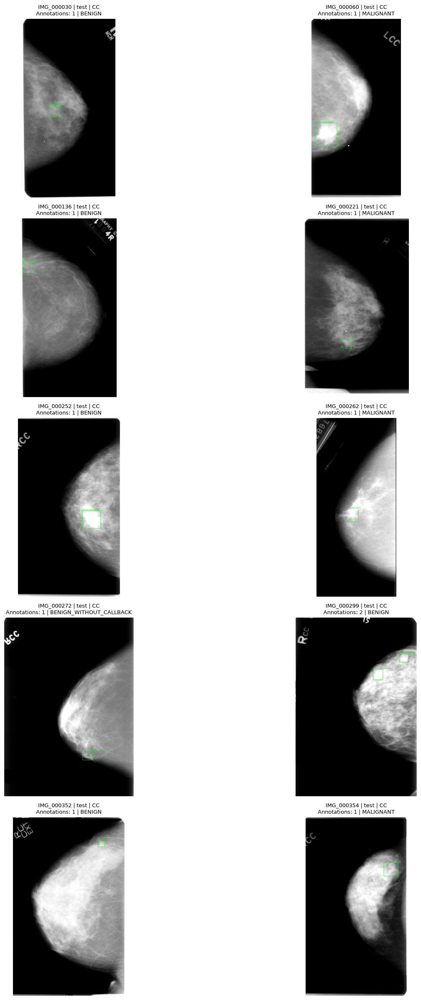

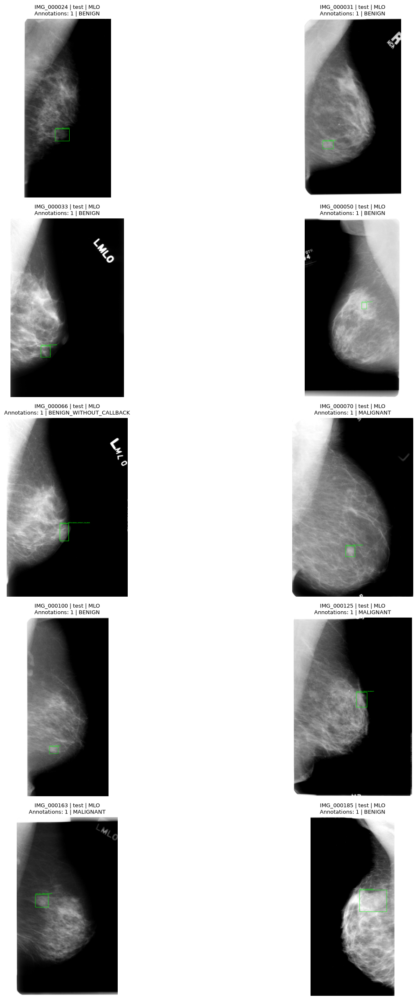

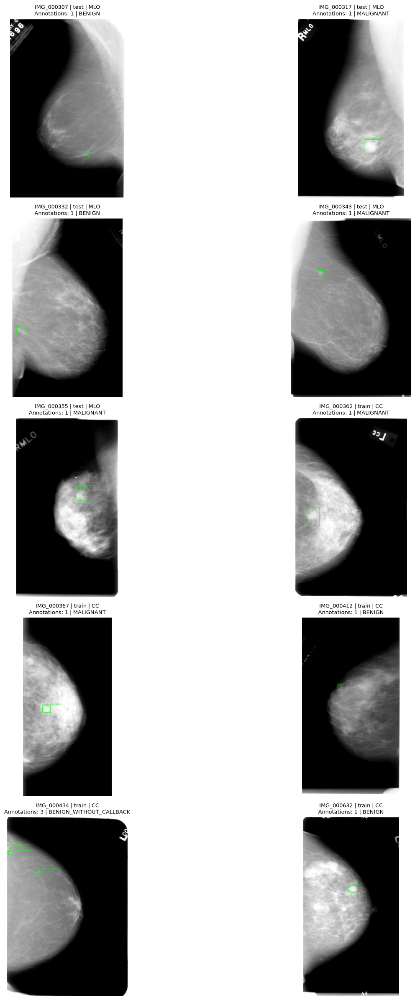

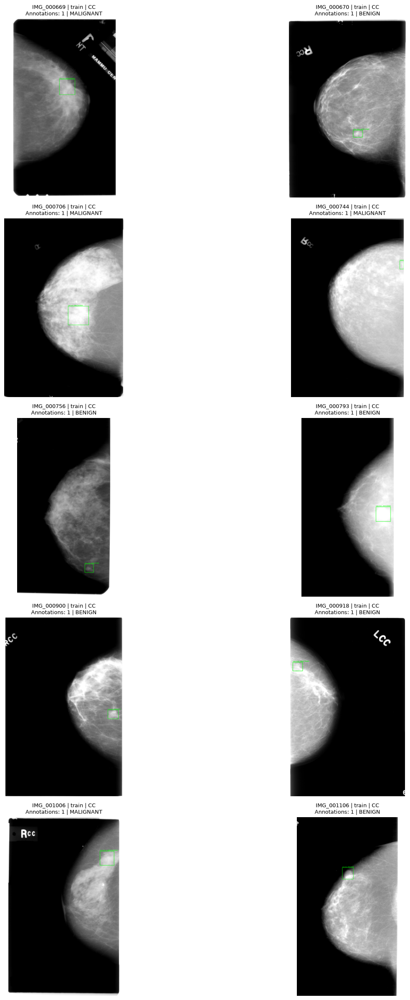

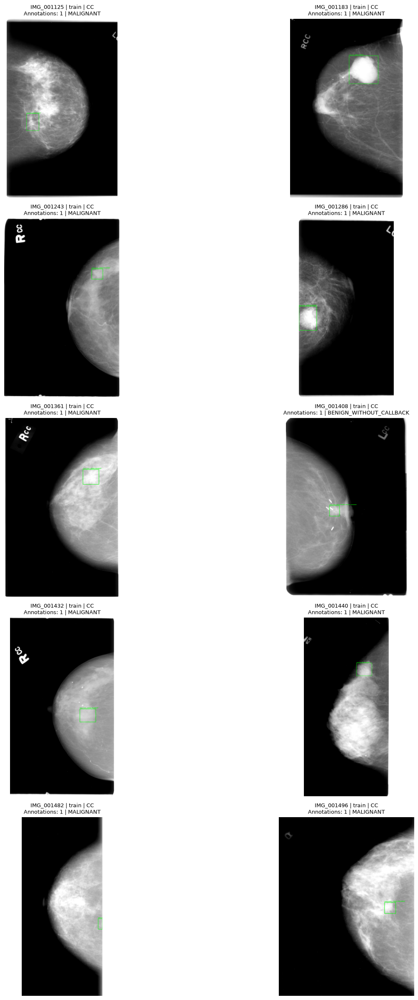

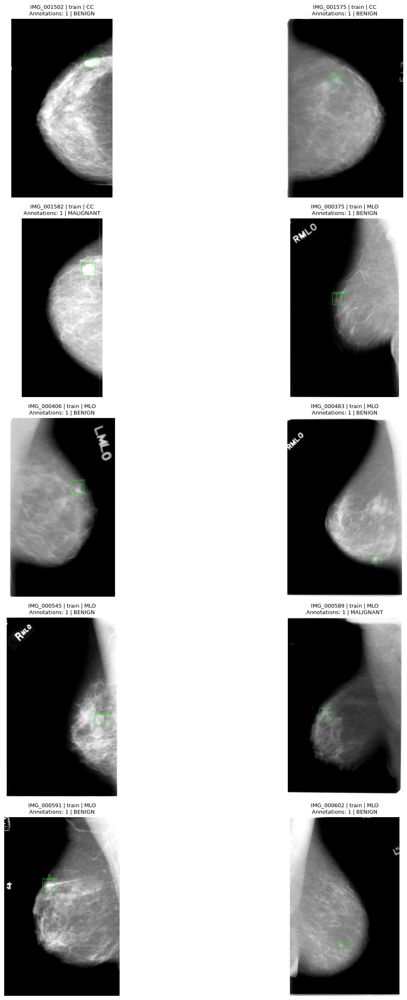

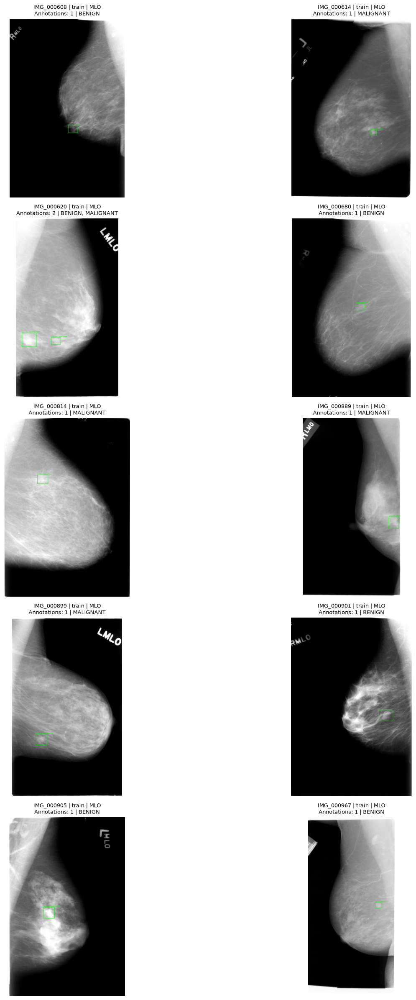

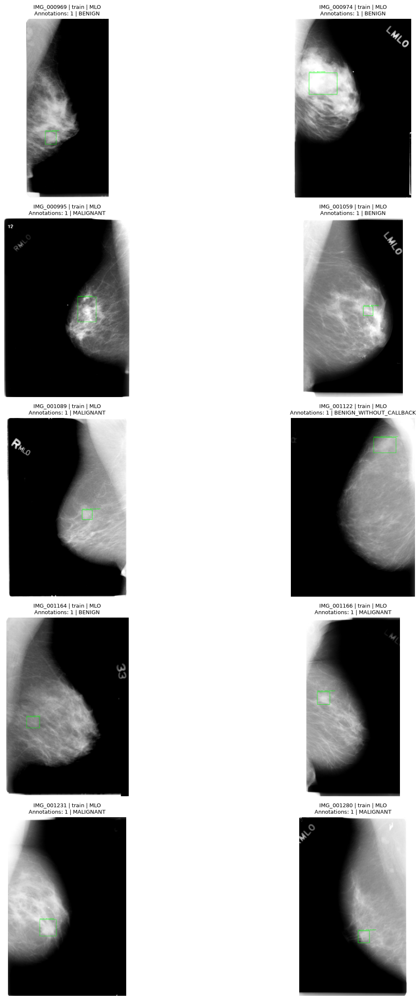

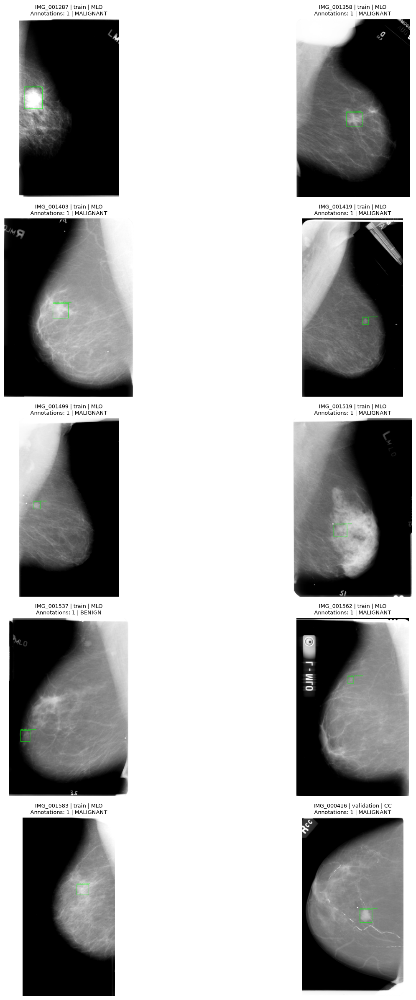

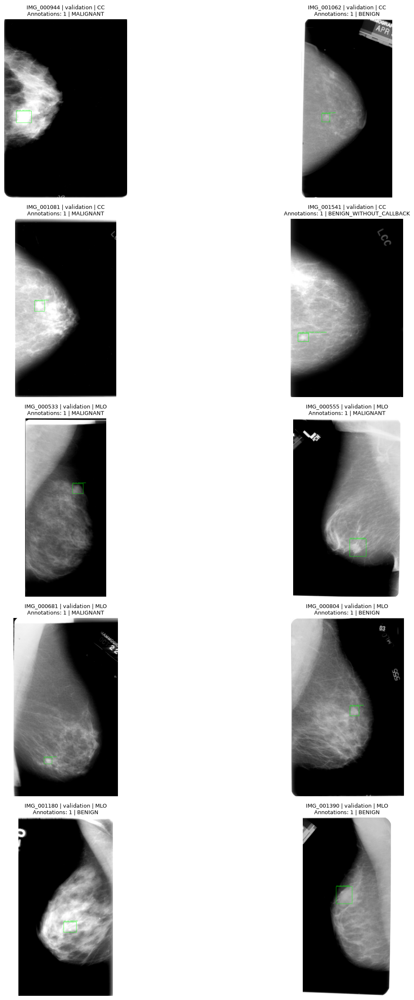

TỔNG QUAN KIỂM TRA TRỰC QUAN


,metric,value
0,unique_images_selected,100
1,annotations_in_selected_images,104
2,overlay_images_created,100
3,contact_sheets_created,10
4,image_read_failures,0



PHÂN BỐ MẪU THEO SPLIT VÀ VIEW


,dataset_split,image_view,image_count,annotation_count
0,test,CC,10,11
1,test,MLO,15,15
2,train,CC,28,30
3,train,MLO,36,37
4,validation,CC,5,5
5,validation,MLO,6,6



ĐƯỜNG DẪN LƯU OVERLAY:
C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb06_detection_dataset\nb06_8_quality_control_visualization\random_100_overlays

ĐƯỜNG DẪN LƯU CONTACT SHEETS:
C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb06_detection_dataset\nb06_8_quality_control_visualization\random_100_contact_sheets


In [ ]:
# Kiểm tra 100 ảnh ngẫu nhiên từ Detection Dataset để tạo Overlay Bounding Box và Contact Sheet
import cv2
import math
from pathlib import Path

NB068_OUTPUT_DIR = NB06_OUTPUT_DIR / "nb06_8_quality_control_visualization"
NB068_OVERLAY_DIR = NB068_OUTPUT_DIR / "random_100_overlays"
NB068_CONTACT_DIR = NB068_OUTPUT_DIR / "random_100_contact_sheets"

NB068_OVERLAY_DIR.mkdir(parents=True, exist_ok=True)
NB068_CONTACT_DIR.mkdir(parents=True, exist_ok=True)

required_columns = [
    "annotation_id",
    "image_id",
    "normalized_image_path",
    "dataset_split",
    "image_view",
    "pathology",
    "x_min",
    "y_min",
    "x_max",
    "y_max"
]

missing_columns = [
    col for col in required_columns
    if col not in detection_labels_df.columns
]

if missing_columns:
    raise ValueError(
        f"Thiếu các cột cần thiết trong detection_labels_df: {missing_columns}"
    )

visual_source_df = detection_labels_df[required_columns].copy()

visual_source_df["normalized_image_path"] = (
    visual_source_df["normalized_image_path"].astype(str)
)

image_sample_source_df = (
    visual_source_df
    .sort_values(["image_id", "annotation_id"])
    .drop_duplicates(subset="image_id")
    .reset_index(drop=True)
)

if len(image_sample_source_df) < 100:
    raise ValueError(
        f"Chỉ có {len(image_sample_source_df)} ảnh độc lập, không đủ 100 ảnh."
    )

random_image_sample_df = (
    image_sample_source_df
    .sample(n=100, random_state=42)
    .sort_values(["dataset_split", "image_view", "image_id"])
    .reset_index(drop=True)
)

overlay_records = []
contact_sheet_items = []

for sample_index, image_row in random_image_sample_df.iterrows():

    image_id = image_row["image_id"]
    image_path = Path(image_row["normalized_image_path"])

    if not image_path.exists():
        raise FileNotFoundError(
            f"Không tìm thấy ảnh {image_id}: {image_path}"
        )

    image = cv2.imread(str(image_path), cv2.IMREAD_GRAYSCALE)

    if image is None:
        raise ValueError(f"Không đọc được ảnh: {image_path}")

    overlay = cv2.cvtColor(image, cv2.COLOR_GRAY2BGR)

    image_labels = visual_source_df[
        visual_source_df["image_id"] == image_id
    ].copy()

    for _, label_row in image_labels.iterrows():

        x1 = int(label_row["x_min"])
        y1 = int(label_row["y_min"])
        x2 = int(label_row["x_max"])
        y2 = int(label_row["y_max"])

        cv2.rectangle(
            overlay,
            (x1, y1),
            (x2, y2),
            (0, 255, 0),
            thickness=8
        )

        label_text = (
            f'{label_row["annotation_id"]} | '
            f'{label_row["pathology"]}'
        )

        text_y = max(y1 - 15, 35)

        cv2.putText(
            overlay,
            label_text,
            (x1, text_y),
            cv2.FONT_HERSHEY_SIMPLEX,
            1.0,
            (0, 255, 0),
            2,
            cv2.LINE_AA
        )

    overlay_filename = f"{image_id}_overlay.png"
    overlay_path = NB068_OVERLAY_DIR / overlay_filename

    cv2.imwrite(str(overlay_path), overlay)

    overlay_records.append({
        "sample_number": sample_index + 1,
        "image_id": image_id,
        "patient_id": image_row.get("patient_id", ""),
        "dataset_split": image_row["dataset_split"],
        "image_view": image_row["image_view"],
        "annotation_count": len(image_labels),
        "annotation_ids": "|".join(
            image_labels["annotation_id"].astype(str)
        ),
        "pathologies": "|".join(
            sorted(image_labels["pathology"].astype(str).unique())
        ),
        "normalized_image_path": str(image_path),
        "overlay_path": str(overlay_path),
        "image_read_status": "success"
    })

    contact_sheet_items.append({
        "image_id": image_id,
        "image": overlay,
        "dataset_split": image_row["dataset_split"],
        "image_view": image_row["image_view"],
        "annotation_count": len(image_labels),
        "pathologies": ", ".join(
            sorted(image_labels["pathology"].astype(str).unique())
        )
    })

random_100_overlay_df = pd.DataFrame(overlay_records)

random_100_overlay_df.to_csv(
    NB068_OUTPUT_DIR / "nb06_8_random_100_overlay_manifest.csv",
    index=False,
    encoding="utf-8-sig"
)

# Tạo 10 contact sheets, mỗi sheet 10 ảnh

for sheet_index in range(10):

    sheet_items = contact_sheet_items[
        sheet_index * 10:(sheet_index + 1) * 10
    ]

    fig, axes = plt.subplots(5, 2, figsize=(18, 24))
    axes = axes.flatten()

    for ax, item in zip(axes, sheet_items):

        image = item["image"]
        height, width = image.shape[:2]

        scale = min(700 / width, 400 / height)

        resized_width = max(1, int(width * scale))
        resized_height = max(1, int(height * scale))

        resized_image = cv2.resize(
            image,
            (resized_width, resized_height),
            interpolation=cv2.INTER_AREA
        )

        ax.imshow(cv2.cvtColor(resized_image, cv2.COLOR_BGR2RGB))
        ax.set_title(
            f'{item["image_id"]} | '
            f'{item["dataset_split"]} | '
            f'{item["image_view"]}\n'
            f'Annotations: {item["annotation_count"]} | '
            f'{item["pathologies"]}',
            fontsize=9
        )
        ax.axis("off")

    for ax in axes[len(sheet_items):]:
        ax.axis("off")

    fig.tight_layout()

    sheet_path = (
        NB068_CONTACT_DIR /
        f"nb06_8_random_100_contact_sheet_{sheet_index + 1:02d}.png"
    )

    fig.savefig(sheet_path, dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)

print("TỔNG QUAN KIỂM TRA TRỰC QUAN")

display(pd.DataFrame([
    {
        "metric": "unique_images_selected",
        "value": random_100_overlay_df["image_id"].nunique()
    },
    {
        "metric": "annotations_in_selected_images",
        "value": random_100_overlay_df["annotation_count"].sum()
    },
    {
        "metric": "overlay_images_created",
        "value": len(random_100_overlay_df)
    },
    {
        "metric": "contact_sheets_created",
        "value": 10
    },
    {
        "metric": "image_read_failures",
        "value": (
            random_100_overlay_df["image_read_status"] != "success"
        ).sum()
    }
]))

print("\nPHÂN BỐ MẪU THEO SPLIT VÀ VIEW")

display(
    random_100_overlay_df
    .groupby(["dataset_split", "image_view"])
    .agg(
        image_count=("image_id", "nunique"),
        annotation_count=("annotation_count", "sum")
    )
    .reset_index()
)

print("\nĐƯỜNG DẪN LƯU OVERLAY:")
print(NB068_OVERLAY_DIR)

print("\nĐƯỜNG DẪN LƯU CONTACT SHEETS:")
print(NB068_CONTACT_DIR)


In [23]:
# Kiểm tra cấu trúc DataFrame
print("BBOX SPATIAL:")
print(bbox_spatial_df.columns.tolist())

print("\nRANDOM 100 OVERLAY:")
print(random_100_overlay_df.columns.tolist())

print("\nDETECTION IMAGES:")
print(detection_images_df.columns.tolist())

print("\nPATIENT SPLIT OVERLAP:")
print(detection_patient_overlap_df.columns.tolist())

BBOX SPATIAL:
['annotation_id', 'patient_id', 'dataset_split', 'pathology', 'image_view', 'laterality', 'normalized_image_path', 'normalized_mask_path', 'alignment_review_status', 'bbox_status_source', 'image_read_status', 'mask_read_status', 'image_height', 'image_width', 'mask_height', 'mask_width', 'image_manifest_dimension_match', 'image_mask_dimension_match', 'bbox_within_image', 'bbox_matches_mask_foreground', 'bbox_spatial_status', 'x_min', 'y_min', 'x_max', 'y_max', 'error']

RANDOM 100 OVERLAY:
['sample_number', 'image_id', 'patient_id', 'dataset_split', 'image_view', 'annotation_count', 'annotation_ids', 'pathologies', 'normalized_image_path', 'overlay_path', 'image_read_status']

DETECTION IMAGES:
['image_id', 'full_image_path', 'normalized_image_path', 'patient_id', 'dataset_split', 'image_view', 'laterality', 'image_height', 'image_width', 'annotation_count', 'normalized_image_copy_count', 'shared_image']

PATIENT SPLIT OVERLAP:
['split_a', 'split_b', 'overlap_patient_coun

In [24]:
# 06.8 — QUALITY CONTROL AND VISUALIZATION

NB068_OUTPUT_DIR = NB06_OUTPUT_DIR / "nb06_8_quality_control_visualization"
NB068_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# 1. Kiểm tra các DataFrame đầu vào

required_objects = [
    "detection_images_df",
    "detection_labels_df",
    "bbox_spatial_df",
    "detection_patient_overlap_df",
    "random_100_overlay_df"
]

missing_objects = [
    name for name in required_objects
    if name not in globals()
    or not isinstance(globals()[name], pd.DataFrame)
]

if missing_objects:
    raise ValueError(f"Thiếu DataFrame đầu vào: {missing_objects}")

images_df = detection_images_df.copy()
labels_df = detection_labels_df.copy()
spatial_df = bbox_spatial_df.copy()
patient_overlap_df = detection_patient_overlap_df.copy()
visual_df = random_100_overlay_df.copy()

# 2. Kiểm tra cấu trúc Detection Dataset

required_label_columns = [
    "annotation_id",
    "image_id",
    "patient_id",
    "dataset_split",
    "pathology",
    "x_min",
    "y_min",
    "x_max",
    "y_max",
    "bbox_x_center_norm",
    "bbox_y_center_norm",
    "bbox_width_norm",
    "bbox_height_norm"
]

missing_columns = [
    col for col in required_label_columns
    if col not in labels_df.columns
]

if missing_columns:
    raise ValueError(
        f"Detection Dataset thiếu các cột: {missing_columns}"
    )

# 3. Tổng quan dữ liệu

total_annotations = len(labels_df)
unique_annotations = labels_df["annotation_id"].nunique()
total_images = images_df["image_id"].nunique()
total_patients = labels_df["patient_id"].nunique()

# 4. Kiểm tra Bounding Box

bbox_columns = ["x_min", "y_min", "x_max", "y_max"]

bbox_numeric = labels_df[bbox_columns].apply(
    pd.to_numeric,
    errors="coerce"
)

bbox_valid_mask = (
    bbox_numeric.notna().all(axis=1)
    & (bbox_numeric["x_min"] >= 0)
    & (bbox_numeric["y_min"] >= 0)
    & (bbox_numeric["x_max"] > bbox_numeric["x_min"])
    & (bbox_numeric["y_max"] > bbox_numeric["y_min"])
)

valid_bbox_count = int(bbox_valid_mask.sum())

# 5. Kiểm tra tọa độ chuẩn hóa

normalized_columns = [
    "bbox_x_center_norm",
    "bbox_y_center_norm",
    "bbox_width_norm",
    "bbox_height_norm"
]

normalized_numeric = labels_df[normalized_columns].apply(
    pd.to_numeric,
    errors="coerce"
)

normalized_valid_mask = (
    normalized_numeric.notna().all(axis=1)
    & (normalized_numeric >= 0).all(axis=1)
    & (normalized_numeric <= 1).all(axis=1)
)

normalized_valid_count = int(normalized_valid_mask.sum())

# 6. Kiểm tra đồng bộ ảnh, Mask và Bounding Box

spatial_checks = [
    "image_read_status",
    "mask_read_status",
    "image_manifest_dimension_match",
    "image_mask_dimension_match",
    "bbox_within_image",
    "bbox_matches_mask_foreground"
]

missing_spatial_columns = [
    col for col in spatial_checks
    if col not in spatial_df.columns
]

if missing_spatial_columns:
    raise ValueError(
        f"Bảng Spatial Validation thiếu cột: {missing_spatial_columns}"
    )

spatial_boolean_columns = [
    "image_manifest_dimension_match",
    "image_mask_dimension_match",
    "bbox_within_image",
    "bbox_matches_mask_foreground"
]

spatial_success_count = int(
    (
        spatial_df["image_read_status"].astype(str).str.lower().eq("success")
        & spatial_df["mask_read_status"].astype(str).str.lower().eq("success")
        & spatial_df[spatial_boolean_columns]
        .fillna(False)
        .astype(bool)
        .all(axis=1)
    ).sum()
)

image_read_success_count = int(
    spatial_df["image_read_status"]
    .astype(str)
    .str.lower()
    .eq("success")
    .sum()
)

mask_read_success_count = int(
    spatial_df["mask_read_status"]
    .astype(str)
    .str.lower()
    .eq("success")
    .sum()
)

image_dimension_match_count = int(
    spatial_df["image_manifest_dimension_match"]
    .fillna(False).astype(bool).sum()
)

image_mask_match_count = int(
    spatial_df["image_mask_dimension_match"]
    .fillna(False).astype(bool).sum()
)

bbox_within_image_count = int(
    spatial_df["bbox_within_image"]
    .fillna(False).astype(bool).sum()
)

bbox_matches_mask_count = int(
    spatial_df["bbox_matches_mask_foreground"]
    .fillna(False).astype(bool).sum()
)

spatial_status_summary_df = (
    spatial_df["bbox_spatial_status"]
    .fillna("missing")
    .astype(str)
    .value_counts()
    .rename_axis("bbox_spatial_status")
    .reset_index(name="annotation_count")
)

# 7. Kiểm tra Pathology

expected_pathologies = {
    "BENIGN",
    "BENIGN_WITHOUT_CALLBACK",
    "MALIGNANT"
}

actual_pathologies = set(
    labels_df["pathology"].dropna().astype(str).unique()
)

pathology_valid = actual_pathologies == expected_pathologies

# 8. Kiểm tra Patient-level Split

if "overlap_patient_count" not in patient_overlap_df.columns:
    raise ValueError(
        "Không tìm thấy overlap_patient_count trong bảng Patient Split."
    )

patient_overlap_count = int(
    pd.to_numeric(
        patient_overlap_df["overlap_patient_count"],
        errors="coerce"
    ).fillna(0).sum()
)

# 9. Kiểm tra ảnh dùng chung giữa nhiều Annotation

if "shared_image" not in images_df.columns:
    raise ValueError("Không tìm thấy cột shared_image.")

shared_image_count = int(
    images_df["shared_image"].fillna(False).astype(bool).sum()
)

annotations_on_shared_images = int(
    images_df.loc[
        images_df["shared_image"].fillna(False).astype(bool),
        "annotation_count"
    ].sum()
)

# 10. Kiểm tra trực quan 100 ảnh

required_visual_columns = [
    "image_id",
    "annotation_count",
    "overlay_path",
    "image_read_status"
]

missing_visual_columns = [
    col for col in required_visual_columns
    if col not in visual_df.columns
]

if missing_visual_columns:
    raise ValueError(
        f"Bảng Visual Inspection thiếu cột: {missing_visual_columns}"
    )

visual_image_count = visual_df["image_id"].nunique()

visual_annotation_count = int(
    visual_df["annotation_count"].sum()
)

visual_read_success_count = int(
    visual_df["image_read_status"]
    .astype(str)
    .str.lower()
    .eq("success")
    .sum()
)

visual_overlay_exists_count = int(
    visual_df["overlay_path"]
    .apply(
        lambda path: (
            pd.notna(path)
            and Path(str(path)).is_file()
        )
    )
    .sum()
)

# 11. Thống kê số lượng Contact Sheet đã tạo

contact_sheet_files = [
    path
    for path in NB06_OUTPUT_DIR.rglob("*.png")
    if "contact" in path.name.lower()
    or "sheet" in path.name.lower()
]

contact_sheet_count = len(contact_sheet_files)

# 12. Tổng hợp Quality Control

qc_records = [
    ("total_annotations", total_annotations, 1696),
    ("unique_annotations", unique_annotations, 1696),
    ("unique_images", total_images, 1592),
    ("unique_patients", total_patients, 892),
    ("valid_bounding_boxes", valid_bbox_count, total_annotations),
    ("normalized_coordinates_in_range", normalized_valid_count, total_annotations),
    ("image_read_success", image_read_success_count, total_annotations),
    ("mask_read_success", mask_read_success_count, total_annotations),
    ("image_manifest_dimension_match", image_dimension_match_count, total_annotations),
    ("image_mask_dimension_match", image_mask_match_count, total_annotations),
    ("bbox_within_image", bbox_within_image_count, total_annotations),
    ("bbox_matches_mask_foreground", bbox_matches_mask_count, total_annotations),
    ("spatial_validation_success", spatial_success_count, total_annotations),
    ("pathology_labels_preserved", len(actual_pathologies), 3),
    ("patient_split_leakage", patient_overlap_count, 0),
    ("shared_images", shared_image_count, 71),
    ("annotations_on_shared_images", annotations_on_shared_images, 175),
    ("random_images_selected", visual_image_count, 100),
    ("annotations_in_random_images", visual_annotation_count, 104),
    ("random_image_read_success", visual_read_success_count, 100),
    ("overlay_files_created", visual_overlay_exists_count, 100)
]

final_qc_report_df = pd.DataFrame(
    qc_records,
    columns=["metric", "value", "expected"]
)

final_qc_report_df["status"] = np.where(
    final_qc_report_df["value"] == final_qc_report_df["expected"],
    "PASS",
    "CHECK"
)

# 13. Phân bố theo Dataset Split

final_split_summary_df = (
    labels_df.groupby("dataset_split")
    .agg(
        annotation_count=("annotation_id", "nunique"),
        image_count=("image_id", "nunique"),
        patient_count=("patient_id", "nunique")
    )
    .reset_index()
)

# 14. Phân bố theo Pathology

final_pathology_summary_df = (
    labels_df.groupby(["dataset_split", "pathology"])
    .agg(
        annotation_count=("annotation_id", "nunique"),
        image_count=("image_id", "nunique"),
        patient_count=("patient_id", "nunique")
    )
    .reset_index()
)

# 15. Phân bố theo Image View

final_view_summary_df = (
    labels_df.groupby(["dataset_split", "image_view"])
    .agg(
        annotation_count=("annotation_id", "nunique"),
        image_count=("image_id", "nunique"),
        patient_count=("patient_id", "nunique")
    )
    .reset_index()
)

# 16. Thống kê Bounding Box

bbox_statistics_records = []

for col in [
    "bbox_width",
    "bbox_height",
    "bbox_area",
    "bbox_x_center_norm",
    "bbox_y_center_norm",
    "bbox_width_norm",
    "bbox_height_norm"
]:
    if col in labels_df.columns:
        values = pd.to_numeric(labels_df[col], errors="coerce")

        bbox_statistics_records.append({
            "metric": col,
            "mean": values.mean(),
            "median": values.median(),
            "std": values.std(),
            "min": values.min(),
            "max": values.max()
        })

final_bbox_statistics_df = pd.DataFrame(
    bbox_statistics_records
)

# 17. Tổng hợp kết quả kiểm tra trực quan

final_visual_summary_df = pd.DataFrame([
    ("unique_images_selected", visual_image_count),
    ("annotations_in_selected_images", visual_annotation_count),
    ("overlay_images_created", visual_overlay_exists_count),
    ("image_read_failures", visual_image_count - visual_read_success_count),
    ("contact_sheets_created", contact_sheet_count)
], columns=["metric", "value"])

# 18. Xuất báo cáo

output_files = {
    "nb06_8_final_qc_report.csv": final_qc_report_df,
    "nb06_8_final_split_summary.csv": final_split_summary_df,
    "nb06_8_final_pathology_summary.csv": final_pathology_summary_df,
    "nb06_8_final_view_summary.csv": final_view_summary_df,
    "nb06_8_final_bbox_statistics.csv": final_bbox_statistics_df,
    "nb06_8_spatial_status_summary.csv": spatial_status_summary_df,
    "nb06_8_final_visual_summary.csv": final_visual_summary_df
}

for filename, dataframe in output_files.items():
    dataframe.to_csv(
        NB068_OUTPUT_DIR / filename,
        index=False,
        encoding="utf-8-sig"
    )

# 19. Hiển thị kết quả

print("BÁO CÁO QUALITY CONTROL NOTEBOOK 06")
display(final_qc_report_df)

print("\nPHÂN BỐ THEO DATASET SPLIT")
display(final_split_summary_df)

print("\nPHÂN BỐ THEO PATHOLOGY")
display(final_pathology_summary_df)

print("\nPHÂN BỐ THEO IMAGE VIEW")
display(final_view_summary_df)

print("\nTHỐNG KÊ BOUNDING BOX")
display(final_bbox_statistics_df)

print("\nTRẠNG THÁI SPATIAL VALIDATION")
display(spatial_status_summary_df)

print("\nKẾT QUẢ KIỂM TRA TRỰC QUAN 100 ẢNH")
display(final_visual_summary_df)

print("\nTỔNG SỐ HẠNG MỤC:", len(final_qc_report_df))
print("PASS:", int((final_qc_report_df["status"] == "PASS").sum()))
print("CHECK:", int((final_qc_report_df["status"] == "CHECK").sum()))

print("\nĐƯỜNG DẪN LƯU BÁO CÁO:")
print(NB068_OUTPUT_DIR)


BÁO CÁO QUALITY CONTROL NOTEBOOK 06


,metric,value,expected,status
0,total_annotations,1696,1696,PASS
1,unique_annotations,1696,1696,PASS
2,unique_images,1592,1592,PASS
3,unique_patients,892,892,PASS
4,valid_bounding_boxes,1696,1696,PASS
5,normalized_coordinates_in_range,1696,1696,PASS
6,image_read_success,1696,1696,PASS
7,mask_read_success,1696,1696,PASS
8,image_manifest_dimension_match,1696,1696,PASS
9,image_mask_dimension_match,1696,1696,PASS



PHÂN BỐ THEO DATASET SPLIT


,dataset_split,annotation_count,image_count,patient_count
0,test,378,361,201
1,train,1054,982,552
2,validation,264,249,139



PHÂN BỐ THEO PATHOLOGY


,dataset_split,pathology,annotation_count,image_count,patient_count
0,test,BENIGN,194,184,101
1,test,BENIGN_WITHOUT_CALLBACK,37,34,20
2,test,MALIGNANT,147,145,85
3,train,BENIGN,463,442,243
4,train,BENIGN_WITHOUT_CALLBACK,83,66,43
5,train,MALIGNANT,508,480,278
6,validation,BENIGN,114,108,61
7,validation,BENIGN_WITHOUT_CALLBACK,21,19,11
8,validation,MALIGNANT,129,122,68


... (5 outputs left out)

,bbox_spatial_status,annotation_count
0,dimension_and_coordinate_valid,1696



KẾT QUẢ KIỂM TRA TRỰC QUAN 100 ẢNH


,metric,value
0,unique_images_selected,100
1,annotations_in_selected_images,104
2,overlay_images_created,100
3,image_read_failures,0
4,contact_sheets_created,11



TỔNG SỐ HẠNG MỤC: 21
PASS: 21
CHECK: 0

ĐƯỜNG DẪN LƯU BÁO CÁO:
C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb06_detection_dataset\nb06_8_quality_control_visualization


## KẾT LUẬN NOTEBOOK 06

## 1. Kết quả thực hiện

Notebook 06 đã hoàn thành quy trình tiền xử lý ảnh và xây dựng Detection Dataset từ tập dữ liệu Mass của CBIS-DDSM.

Các công việc đã thực hiện:

- Phân tích cấu trúc và đặc tính Pixel Data của ảnh DICOM.
- Khảo sát phân bố cường độ Pixel và lựa chọn phương pháp chuẩn hóa ảnh.
- Chuẩn hóa 1.696 ảnh theo phương pháp A về ảnh grayscale 8-bit.
- Kiểm tra ROI Mask và trích xuất Bounding Box từ vùng foreground.
- Đồng bộ kích thước ảnh, ROI Mask và tọa độ Bounding Box.
- Xây dựng Detection Dataset với tọa độ Bounding Box dạng `xyxy` và tọa độ chuẩn hóa.
- Kiểm tra chất lượng dữ liệu, tính nhất quán giữa các tập và trực quan hóa kết quả.

## 2. Kết quả xây dựng Detection Dataset

| Thành phần | Số lượng |
|---|---:|
| Tổng số Annotation | 1.696 |
| Ảnh Full Image duy nhất | 1.592 |
| Patient ID | 892 |
| Bounding Box hợp lệ | 1.696 |
| ROI Mask đọc thành công | 1.696 |
| Nhãn Pathology | 3 |

Dataset được tổ chức thành hai thành phần:

- **Image Manifest:** 1.592 ảnh duy nhất, lưu thông tin ảnh và đường dẫn tương ứng.
- **Detection Annotations:** 1.696 Annotation, lưu Bounding Box, tọa độ chuẩn hóa và nhãn Pathology.

Phân chia dữ liệu:

| Dataset Split | Annotation | Image | Patient |
|---|---:|---:|---:|
| Train | 1.054 | 982 | 552 |
| Validation | 264 | 249 | 139 |
| Test | 378 | 361 | 201 |
| **Tổng** | **1.696** | **1.592** | **892** |

Ba nhãn Pathology được bảo toàn:

- `BENIGN`
- `BENIGN_WITHOUT_CALLBACK`
- `MALIGNANT`

Nhãn `BENIGN_WITHOUT_CALLBACK` được giữ riêng, chưa gộp vào BENIGN hoặc MALIGNANT.

## 3. Kết quả kiểm tra chất lượng

Toàn bộ **21/21 hạng mục Quality Control đạt PASS**, không có hạng mục cần kiểm tra lại.

Các kết quả chính:

- 1.696/1.696 Annotation có Bounding Box hợp lệ.
- 1.696/1.696 Annotation có tọa độ chuẩn hóa nằm trong khoảng [0, 1].
- 1.696/1.696 ảnh và ROI Mask đọc thành công.
- 1.696/1.696 trường hợp khớp kích thước ảnh–Mask.
- 1.696/1.696 Bounding Box nằm trong giới hạn ảnh và khớp với vùng foreground của Mask.
- Không ghi nhận Patient ID trùng giữa Train, Validation và Test.
- 71 ảnh được dùng chung bởi nhiều Annotation; 175 Annotation trên các ảnh này được giữ lại trong Detection Dataset.

### Kiểm tra trực quan

- Chọn ngẫu nhiên 100 ảnh từ Detection Dataset.
- Có tổng cộng 104 Annotation trên 100 ảnh được chọn.
- Tạo thành công 100 ảnh Bounding Box Overlay và 11 Contact Sheet.
- Không có lỗi đọc ảnh.
- Qua quan sát trực quan, các Bounding Box hiển thị rõ và nằm trên vùng tổn thương tương ứng.

## 4. Đầu ra của Notebook

Thư mục kết quả chính:

`Data/processed/nb06_detection_dataset/`

Các nhóm dữ liệu đầu ra:

- `nb06_3_pixel_intensity_analysis`: kết quả phân tích cường độ Pixel.
- `nb06_4_full_image_preprocessing`: ảnh Full Image sau chuẩn hóa và Manifest.
- `nb06_5_roi_mask_bbox_extraction`: Bounding Box trích xuất từ ROI Mask.
- `nb06_6_image_label_spatial_synchronization`: kết quả kiểm tra đồng bộ không gian.
- `nb06_7_detection_dataset`: Image Manifest, Detection Annotations và Detection Dataset.
- `nb06_8_quality_control_visualization`: báo cáo QC và kết quả kiểm tra trực quan.

## 5. Giới hạn và định hướng tiếp theo

- Bounding Box được trích xuất từ ROI Mask của CBIS-DDSM, không phải nhãn Bounding Box độc lập do chuyên gia tạo.
- Có 78 ROI Mask khác kích thước ảnh ban đầu đã được resize bằng Nearest Neighbor và kiểm tra overlay trực quan. Các trường hợp cùng kích thước được xử lý theo phép đồng nhất kích thước và kiểm tra bằng QC.
- Kiểm tra trực quan ngẫu nhiên 100 ảnh bổ sung cho kiểm tra tự động, không đồng nghĩa toàn bộ 1.696 ảnh đã được chuyên gia đánh giá riêng lẻ.
- Ba nhãn Pathology tiếp tục được bảo toàn để phục vụ nghiên cứu phân biệt tổn thương lành tính và ác tính ở giai đoạn mô hình.

**Kết luận:** ## KẾT LUẬN NOTEBOOK 06

## 1. Kết quả thực hiện

Notebook 06 đã hoàn thành quy trình tiền xử lý ảnh và xây dựng Detection Dataset từ tập dữ liệu Mass của CBIS-DDSM.

Các công việc đã thực hiện:

- Phân tích cấu trúc và đặc tính Pixel Data của ảnh DICOM.
- Khảo sát phân bố cường độ Pixel và lựa chọn phương pháp chuẩn hóa ảnh.
- Chuẩn hóa 1.696 ảnh theo phương pháp A về ảnh grayscale 8-bit.
- Kiểm tra ROI Mask và trích xuất Bounding Box từ vùng foreground.
- Đồng bộ kích thước ảnh, ROI Mask và tọa độ Bounding Box.
- Xây dựng Detection Dataset với tọa độ Bounding Box dạng `xyxy` và tọa độ chuẩn hóa.
- Kiểm tra chất lượng dữ liệu, tính nhất quán giữa các tập và trực quan hóa kết quả.

## 2. Kết quả xây dựng Detection Dataset

| Thành phần | Số lượng |
|---|---:|
| Tổng số Annotation | 1.696 |
| Ảnh Full Image duy nhất | 1.592 |
| Patient ID | 892 |
| Bounding Box hợp lệ | 1.696 |
| ROI Mask đọc thành công | 1.696 |
| Nhãn Pathology | 3 |

Dataset được tổ chức thành hai thành phần:

- **Image Manifest:** 1.592 ảnh duy nhất, lưu thông tin ảnh và đường dẫn tương ứng.
- **Detection Annotations:** 1.696 Annotation, lưu Bounding Box, tọa độ chuẩn hóa và nhãn Pathology.

Phân chia dữ liệu:

| Dataset Split | Annotation | Image | Patient |
|---|---:|---:|---:|
| Train | 1.054 | 982 | 552 |
| Validation | 264 | 249 | 139 |
| Test | 378 | 361 | 201 |
| **Tổng** | **1.696** | **1.592** | **892** |

Ba nhãn Pathology được bảo toàn:

- `BENIGN`
- `BENIGN_WITHOUT_CALLBACK`
- `MALIGNANT`

Nhãn `BENIGN_WITHOUT_CALLBACK` được giữ riêng, chưa gộp vào BENIGN hoặc MALIGNANT.

## 3. Kết quả kiểm tra chất lượng

Toàn bộ **21/21 hạng mục Quality Control đạt PASS**, không có hạng mục cần kiểm tra lại.

Các kết quả chính:

- 1.696/1.696 Annotation có Bounding Box hợp lệ.
- 1.696/1.696 Annotation có tọa độ chuẩn hóa nằm trong khoảng [0, 1].
- 1.696/1.696 ảnh và ROI Mask đọc thành công.
- 1.696/1.696 trường hợp khớp kích thước ảnh–Mask.
- 1.696/1.696 Bounding Box nằm trong giới hạn ảnh và khớp với vùng foreground của Mask.
- Không ghi nhận Patient ID trùng giữa Train, Validation và Test.
- 71 ảnh được dùng chung bởi nhiều Annotation; 175 Annotation trên các ảnh này được giữ lại trong Detection Dataset.

### Kiểm tra trực quan

- Chọn ngẫu nhiên 100 ảnh từ Detection Dataset.
- Có tổng cộng 104 Annotation trên 100 ảnh được chọn.
- Tạo thành công 100 ảnh Bounding Box Overlay và 11 Contact Sheet.
- Không có lỗi đọc ảnh.
- Qua quan sát trực quan, các Bounding Box hiển thị rõ và nằm trên vùng tổn thương tương ứng.

## 4. Đầu ra của Notebook

Thư mục kết quả chính:

`Data/processed/nb06_detection_dataset/`

Các nhóm dữ liệu đầu ra:

- `nb06_3_pixel_intensity_analysis`: kết quả phân tích cường độ Pixel.
- `nb06_4_full_image_preprocessing`: ảnh Full Image sau chuẩn hóa và Manifest.
- `nb06_5_roi_mask_bbox_extraction`: Bounding Box trích xuất từ ROI Mask.
- `nb06_6_image_label_spatial_synchronization`: kết quả kiểm tra đồng bộ không gian.
- `nb06_7_detection_dataset`: Image Manifest, Detection Annotations và Detection Dataset.
- `nb06_8_quality_control_visualization`: báo cáo QC và kết quả kiểm tra trực quan.

## 5. Giới hạn và định hướng tiếp theo

- Bounding Box được trích xuất từ ROI Mask của CBIS-DDSM, không phải nhãn Bounding Box độc lập do chuyên gia tạo.
- Có 78 ROI Mask khác kích thước ảnh ban đầu đã được resize bằng Nearest Neighbor và kiểm tra overlay trực quan. Các trường hợp cùng kích thước được xử lý theo phép đồng nhất kích thước và kiểm tra bằng QC.
- Kiểm tra trực quan ngẫu nhiên 100 ảnh bổ sung cho kiểm tra tự động, không đồng nghĩa toàn bộ 1.696 ảnh đã được chuyên gia đánh giá riêng lẻ.
- Ba nhãn Pathology tiếp tục được bảo toàn để phục vụ nghiên cứu phân biệt tổn thương lành tính và ác tính ở giai đoạn mô hình.

**Giới hạn:** Bounding Box được suy ra từ ROI Mask của CBIS-DDSM. Kết quả kiểm tra không gian xác nhận tính nhất quán của ảnh, Mask và tọa độ; kiểm tra trực quan ngẫu nhiên bổ sung xác nhận vị trí hiển thị trên mẫu ảnh. Đây là nhãn phục vụ thực nghiệm trên tập dữ liệu, không thay thế đánh giá độc lập của chuyên gia chẩn đoán hình ảnh.